# ElasticNet Benchmark — RAW vs SCALED (Separate Analyses + Plots)

This notebook runs the full analysis **twice**:

1. **RAW** (original model outputs)
2. **SCALED** (per-sample min–max scaling of `true` and `predicted` separately, scTranslator-style)

It produces four plot files:

- `elasticnet_metrics_raw.png`
- `elasticnet_detailed_metrics_raw.png`
- `elasticnet_metrics_scaled.png`
- `elasticnet_detailed_metrics_scaled.png`

**Input expected:** an HDF5 file named `enet_full_results.h5` in the current working directory (or set `H5_PATH` below).


## Readable figures and PDF export

Run this notebook from the first cell to the final export cell using the original data files. Fonts, subplot spacing, title wrapping, and statistics boxes have been enlarged. Six-panel detailed performance figures use two rows and three columns, with extra room for labels and statistics. Previous outputs were cleared so they cannot be mistaken for the updated plots.

The final cell writes **every generated figure** as a vector PDF into **`figures_pdf` beside this notebook**, including figures closed by earlier cells. Filenames contain a notebook prefix and figure number to prevent collisions. Standard Jupyter starts in the notebook folder; if your kernel was launched elsewhere and cannot report its notebook path, set `NOTEBOOK_DIRECTORY_OVERRIDE` in the setup cell.

All plot titles are hidden. A compact 1×3 protein-metric section with separate printed tables is appended after the existing analyses and before the final PDF export.


In [1]:
# Larger plot text and deferred PDF export.
# Keep this cell before the analysis/plotting cells.
from pathlib import Path
from collections import OrderedDict
from io import BytesIO
import os
import re
import textwrap
import warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib._pylab_helpers import Gcf
from matplotlib.ticker import MaxNLocator

NOTEBOOK_SLUG = 'enet_sctranslator'
REMOVE_PLOT_TITLES = True
NOTEBOOK_DIRECTORY_OVERRIDE = None  # Set a Path here only if the kernel runs elsewhere.


def _notebook_directory():
    if NOTEBOOK_DIRECTORY_OVERRIDE is not None:
        return Path(NOTEBOOK_DIRECTORY_OVERRIDE).expanduser().resolve()
    # VS Code and Jupyter may provide the notebook's actual path.
    candidates = [globals().get('__vsc_ipynb_file__'), os.environ.get('JPY_SESSION_NAME')]
    for candidate in candidates:
        if candidate:
            path = Path(candidate).expanduser()
            if path.suffix == '.ipynb' and path.is_file():
                return path.resolve().parent
    try:
        import ipynbname
        return ipynbname.path().resolve().parent
    except (ImportError, FileNotFoundError, RuntimeError, OSError):
        # Standard Jupyter kernels start in the notebook's own directory.
        return Path.cwd().resolve()


NOTEBOOK_DIRECTORY = _notebook_directory()
FIGURES_PDF_DIR = NOTEBOOK_DIRECTORY / 'figures_pdf'
_pdf_figure_cache = OrderedDict()
_pdf_next_number = 1

mpl.rcParams.update({
    'font.size': 13,
    'axes.titlesize': 17,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'legend.title_fontsize': 12,
    'figure.titlesize': 22,
    'figure.figsize': (8, 6.5),
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.25,
})


def set_readable_theme(*args, **kwargs):
    """Keep Seaborn's own implicit label/tick fonts larger as well."""
    import seaborn as sns
    kwargs.setdefault('font_scale', 1.20)
    return sns.set_theme(*args, **kwargs)


def readable_figsize(original_size):
    """Increase physical space together with fonts, including dynamic grids."""
    width, height = original_size
    if NOTEBOOK_SLUG == 'hpa_barplots':
        return float(width) * 1.18, float(height) * 1.35
    return float(width) * 1.10, float(height) * 1.25


def _wrap_to_width(artist, renderer, max_width):
    """Wrap whole words using measured text extents, without shortening labels."""
    original = getattr(artist, '_readable_original_text', artist.get_text())
    artist._readable_original_text = original
    if not original or '$' in original:
        return
    artist.set_text(original)
    if artist.get_window_extent(renderer).width <= max_width:
        return
    for width in range(max(12, max(map(len, original.splitlines())) - 1), 11, -1):
        candidate = '\n'.join(
            textwrap.fill(line, width=width, break_long_words=False, break_on_hyphens=False)
            for line in original.split('\n')
        )
        artist.set_text(candidate)
        if artist.get_window_extent(renderer).width <= max_width:
            break



def _remember_figure_name(fig, text):
    """Keep descriptive export names without displaying a plot title."""
    fig._readable_export_title = str(text)


def _remember_axes_name(ax, text):
    if not hasattr(ax.figure, '_readable_export_axes_title'):
        ax.figure._readable_export_axes_title = str(text)


def prepare_readable_figure(fig):
    """Apply minimum font sizes and measure margins before display or export."""
    if not fig.axes or getattr(fig, '_readable_preparing', False):
        return fig
    fig._readable_preparing = True
    try:
        if REMOVE_PLOT_TITLES:
            for axis in fig.axes:
                for location in ('left', 'center', 'right'):
                    title_artist = axis.set_title('', loc=location)
                    title_artist._readable_original_text = ''
            if fig._suptitle is not None:
                fig._suptitle.remove()
                fig._suptitle = None
        if getattr(fig, '_compact_protein_metrics', False):
            # Short, wide layout for stacking five panels on an A4 page.
            fig.tight_layout(pad=0.25, w_pad=0.8, h_pad=0.25)
            fig.canvas.draw()
            return fig
        for ax in fig.axes:
            if not ax.get_visible():
                continue
            ax.title.set_fontsize(max(16, ax.title.get_fontsize()))
            ax.xaxis.label.set_fontsize(max(14, ax.xaxis.label.get_fontsize()))
            ax.yaxis.label.set_fontsize(max(14, ax.yaxis.label.get_fontsize()))
            ax.xaxis.labelpad = max(8, ax.xaxis.labelpad)
            ax.yaxis.labelpad = max(9, ax.yaxis.labelpad)
            ax.tick_params(axis='both', which='major', pad=5)
            for label in ax.get_xticklabels() + ax.get_yticklabels():
                label.set_fontsize(max(11.5, label.get_fontsize()))
            for offset in (ax.xaxis.get_offset_text(), ax.yaxis.get_offset_text()):
                offset.set_fontsize(max(11.5, offset.get_fontsize()))
            for artist in ax.texts:
                artist.set_fontsize(max(11.5, artist.get_fontsize()))
                if re.fullmatch(r'\(?[A-Za-z]\)', artist.get_text().strip()):
                    # Panel letters sit outside the data and statistics boxes.
                    artist.set_position((-0.06, 1.03))
                    artist.set_ha('right')
                    artist.set_va('bottom')
                    artist.set_clip_on(False)
                if not ax.axison and artist.get_text().count('\n') >= 8:
                    # Keep the full statistics box within its own panel.
                    artist.set_position((0.03, 0.96))
                    artist.set_ha('left')
                    artist.set_va('top')
                    artist.set_linespacing(1.10)
            legend = ax.get_legend()
            if legend is not None:
                for label in legend.get_texts():
                    label.set_fontsize(max(11.5, label.get_fontsize()))
                legend.get_title().set_fontsize(max(12, legend.get_title().get_fontsize()))
        if fig._suptitle is not None:
            fig._suptitle.set_fontsize(max(20, fig._suptitle.get_fontsize()))
            fig._suptitle.set_y(0.985)
            fig._suptitle.set_va('top')
        for legend in fig.legends:
            for label in legend.get_texts():
                label.set_fontsize(max(11.5, label.get_fontsize()))
        # Repeat after layout: wrapping changes title height and required margins.
        for _ in range(3):
            fig.canvas.draw()
            renderer = fig.canvas.get_renderer()
            if fig._suptitle is not None:
                _wrap_to_width(fig._suptitle, renderer, fig.bbox.width * 0.94)
            for ax in fig.axes:
                if ax.get_visible():
                    _wrap_to_width(ax.title, renderer, ax.bbox.width * 0.96)
            bottom, top = 0.02, 0.98
            if fig._suptitle is not None:
                title_height = fig._suptitle.get_window_extent(renderer).height / fig.bbox.height
                top = min(top, 0.97 - title_height - 0.018)
            for legend in fig.legends:
                bounds = legend.get_window_extent(renderer)
                fraction = bounds.height / fig.bbox.height
                if bounds.y0 + bounds.height / 2 < fig.bbox.y0 + fig.bbox.height / 2:
                    bottom = max(bottom, fraction + 0.045)
                else:
                    top = min(top, 0.97 - fraction - 0.025)
            # Let tight_layout control GridSpec spacing instead of skipping grids
            # whose hspace/wspace was explicitly fixed by older plotting code.
            engine = fig.get_layout_engine()
            if engine is None or engine.__class__.__name__ != 'ConstrainedLayoutEngine':
                grids = set()
                for ax in fig.axes:
                    if hasattr(ax, 'get_subplotspec'):
                        spec = ax.get_subplotspec()
                        if spec is not None:
                            grids.add(spec.get_gridspec())
                for grid in grids:
                    grid.update(hspace=None, wspace=None)
            if engine is not None and engine.__class__.__name__ == 'ConstrainedLayoutEngine':
                engine.set(w_pad=0.12, h_pad=0.16, wspace=0.10, hspace=0.15)
            else:
                with warnings.catch_warnings():
                    warnings.filterwarnings('ignore', message='.*not compatible with tight_layout.*')
                    fig.tight_layout(pad=1.25, h_pad=2.1, w_pad=2.2, rect=(0.01, bottom, 0.99, top))
            fig.canvas.draw()
            renderer = fig.canvas.get_renderer()
            # A long statistics block must not extend below its allocated panel.
            required_growth = 1.0
            for ax in fig.axes:
                for artist in ax.texts:
                    # Reserve room inside axes for bar-end numbers and log-scale
                    # percentage annotations; do not move their data coordinates.
                    if artist.get_transform() is ax.transData and ax.axison:
                        bounds = artist.get_window_extent(renderer)
                        x0, x1 = ax.get_xlim()
                        y0, y1 = ax.get_ylim()
                        if x1 > x0 and bounds.x1 > ax.bbox.x1 + 1:
                            right = ax.transData.inverted().transform((bounds.x1 + 8, ax.bbox.y0))[0]
                            if np.isfinite(right):
                                ax.set_xlim(x0, right)
                        if y1 > y0 and bounds.y1 > ax.bbox.y1 + 1:
                            upper = ax.transData.inverted().transform((ax.bbox.x0, bounds.y1 + 8))[1]
                            if np.isfinite(upper):
                                ax.set_ylim(y0, upper)
                    if not ax.axison and artist.get_text().count('\n') >= 8:
                        bounds = artist.get_window_extent(renderer)
                        required_growth = max(required_growth, bounds.height / max(ax.bbox.height * 0.94, 1))
                # Numeric ticks can use fewer positions while preserving their scale.
                labels = [t for t in ax.get_xticklabels() if t.get_visible() and t.get_text()]
                boxes = [t.get_window_extent(renderer) for t in labels]
                overlaps = any(a.overlaps(b) for a, b in zip(boxes, boxes[1:]))
                if overlaps and not ax.xaxis.get_units() and len(labels) > 5:
                    if all(t.get_rotation() == 0 for t in labels):
                        locator = ax.xaxis.get_major_locator()
                        if locator.__class__.__name__ in {'AutoLocator', 'MaxNLocator'}:
                            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            if required_growth > 1.01:
                width, height = fig.get_size_inches()
                fig.set_size_inches(width, height * min(required_growth * 1.05, 1.6), forward=True)
        # Avoid collisions between annotation text and an axes legend.
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        for ax in fig.axes:
            legend = ax.get_legend()
            if legend is None:
                continue
            legend_box = legend.get_window_extent(renderer)
            if any(t.get_visible() and t.get_text() and legend_box.overlaps(t.get_window_extent(renderer))
                   for t in ax.texts):
                if hasattr(legend, 'set_loc'):
                    for location in ('upper left', 'lower right', 'lower left'):
                        legend.set_loc(location)
                        fig.canvas.draw()
                        legend_box = legend.get_window_extent(renderer)
                        if not any(t.get_visible() and t.get_text() and legend_box.overlaps(t.get_window_extent(renderer))
                                   for t in ax.texts):
                            break
        fig.canvas.draw()
        return fig
    finally:
        fig._readable_preparing = False


def _cache_figure_pdf(fig, source_name=None):
    """Snapshot vector PDFs in memory so closed figures survive until the last cell."""
    global _pdf_next_number
    if not fig.axes or not any(ax.get_visible() for ax in fig.axes):
        return
    key = getattr(fig, '_readable_pdf_key', None)
    if key is None or not str(key).startswith(NOTEBOOK_SLUG + '__'):
        key = f'{NOTEBOOK_SLUG}__{_pdf_next_number:03d}'
        _pdf_next_number += 1
        fig._readable_pdf_key = key
    previous = _pdf_figure_cache.get(key, {})
    name = previous.get('name')
    if source_name is not None and isinstance(source_name, (str, os.PathLike)):
        name = Path(source_name).stem
    if not name:
        title = getattr(fig, '_readable_export_title', '')
        if not title:
            title = getattr(fig, '_readable_export_axes_title', '')
        if not title:
            title = fig._suptitle.get_text() if fig._suptitle is not None else ''
        if not title:
            title = next((ax.get_title() for ax in fig.axes if ax.get_title()), 'figure')
        name = title
    name = re.sub(r'[^A-Za-z0-9._-]+', '_', name).strip('._')[:120] or 'figure'
    buffer = BytesIO()
    fig.savefig(buffer, format='pdf', bbox_inches='tight',
                pad_inches=getattr(fig, '_readable_pdf_pad', 0.25),
                metadata={'Creator': 'Matplotlib', 'Title': name})
    _pdf_figure_cache[key] = {
        'name': name, 'pdf': buffer.getvalue(),
        'export_name': getattr(fig, '_readable_export_name', None),
    }


def save_readable_figure(fig, filename, *args, **kwargs):
    prepare_readable_figure(fig)
    kwargs.setdefault('bbox_inches', 'tight')
    kwargs.setdefault('pad_inches', 0.25)
    result = fig.savefig(filename, *args, **kwargs)
    _cache_figure_pdf(fig, source_name=filename)
    return result


def save_readable_current_figure(filename, *args, **kwargs):
    return save_readable_figure(plt.gcf(), filename, *args, **kwargs)


def show_readable_figures(*args, **kwargs):
    for manager in list(Gcf.get_all_fig_managers()):
        fig = manager.canvas.figure
        prepare_readable_figure(fig)
        _cache_figure_pdf(fig)
    return plt.show(*args, **kwargs)


def close_readable_figures(fig=None):
    if fig == 'all':
        figures = [m.canvas.figure for m in Gcf.get_all_fig_managers()]
    elif fig is None:
        manager = Gcf.get_active()
        figures = [manager.canvas.figure] if manager is not None else []
    elif hasattr(fig, 'savefig'):
        figures = [fig]
    else:
        manager = Gcf.get_fig_manager(fig) if isinstance(fig, int) else None
        figures = [manager.canvas.figure] if manager is not None else []
    for figure in figures:
        prepare_readable_figure(figure)
        _cache_figure_pdf(figure)
    return plt.close(fig)


def export_notebook_figures():
    """Write every figure created during this run, including already-closed figures."""
    for manager in list(Gcf.get_all_fig_managers()):
        fig = manager.canvas.figure
        prepare_readable_figure(fig)
        _cache_figure_pdf(fig)
    if not _pdf_figure_cache:
        raise RuntimeError('No figures captured. Run the setup and plotting cells first.')
    FIGURES_PDF_DIR.mkdir(parents=True, exist_ok=True)
    saved = []
    for key, record in _pdf_figure_cache.items():
        filename = record.get('export_name') or f'{key}__{record["name"]}.pdf'
        path = FIGURES_PDF_DIR / filename
        path.write_bytes(record['pdf'])
        saved.append(path)
    print(f'Saved {len(saved)} PDF figures to: {FIGURES_PDF_DIR}')
    for path in saved:
        print('  ' + path.name)
    return saved

print('Readable plotting enabled. Final PDF destination:', FIGURES_PDF_DIR)


Readable plotting enabled. Final PDF destination: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\figures_pdf


In [2]:
# 0) Imports
import joblib  # imported in scripts; not required for metrics but kept for parity
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path


In [3]:
# 1) Config
H5_PATH = Path("res_data/enet_all_results.h5")  # change if needed

OUT_METRICS_RAW = Path("elasticnet_metrics_raw.png")
OUT_DETAILED_RAW = Path("elasticnet_detailed_metrics_raw.png")

OUT_METRICS_SCALED = Path("elasticnet_metrics_scaled.png")
OUT_DETAILED_SCALED = Path("elasticnet_detailed_metrics_scaled.png")

if not H5_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {H5_PATH.resolve()} — place 'elasticnet_results.h5' next to this notebook or update H5_PATH."
    )


## 2) Load the HDF5 into one long DataFrame (`combined_df`)

Expected columns:
- `protein`
- `LOO sample`
- `true`
- `predicted`


In [4]:
# 2a) Read all protein tables and build a long DataFrame
rows = []

with pd.HDFStore(H5_PATH, mode="r") as store:
    keys = store.keys()
    print(f"Found {len(keys)} protein keys in HDF5")

    for key in keys:
        protein_name = key.strip("/")
        t = store[key].copy()

        # Required columns check (matches what the scripts assume)
        req = {"LOO sample", "true", "predicted"}
        missing = req - set(t.columns)
        if missing:
            raise ValueError(
                f"Key '{key}' is missing required columns: {sorted(missing)}. Found: {list(t.columns)}"
            )

        tmp = t[["LOO sample", "true", "predicted"]].copy()
        tmp["protein"] = protein_name
        rows.append(tmp)

combined_df = pd.concat(rows, ignore_index=True)
combined_df = combined_df[["protein", "LOO sample", "true", "predicted"]]

print("combined_df shape:", combined_df.shape)
combined_df.head()


Found 5113 protein keys in HDF5
combined_df shape: (1886697, 4)


,protein,LOO sample,true,predicted
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651
1,A2M,SH4_SKIN,1.642186,0.308402
2,A2M,AU565_BREAST,-1.129114,-0.899868
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243
4,A2M,CAL51_BREAST,0.274652,0.275565


In [5]:
# 2b) Ensure numeric (coerce non-numeric to NaN)
df = combined_df.copy()
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")

print("NaNs after coercion:")
print("  true     :", int(df["true"].isna().sum()))
print("  predicted:", int(df["predicted"].isna().sum()))


NaNs after coercion:
  true     : 0
  predicted: 0


## 3) Build RAW matrices (samples × proteins)

In [6]:
# 3a) RAW pivot matrices
GT_raw = df.pivot(index="LOO sample", columns="protein", values="true")
PRED_raw = df.pivot(index="LOO sample", columns="protein", values="predicted")

print("RAW shapes:")
print("  GT_raw  :", GT_raw.shape)
print("  PRED_raw:", PRED_raw.shape)

assert list(GT_raw.index) == list(PRED_raw.index), "Sample indices don't match!"
assert list(GT_raw.columns) == list(PRED_raw.columns), "Protein columns don't match!"


RAW shapes:
  GT_raw  : (369, 5113)
  PRED_raw: (369, 5113)


## 4) Build SCALED matrices (per-sample min–max scaling, true/pred separately)

In [7]:
# 4a) Scaling function (scTranslator-style)
EPS = 1e-8  # lower bound in target range

def normalization(x: pd.Series, low: float = EPS, high: float = 1.0) -> pd.Series:
    xmin = x.min(skipna=True)
    xmax = x.max(skipna=True)
    if pd.isna(xmin) or pd.isna(xmax):
        return pd.Series(np.nan, index=x.index, dtype="float64")
    if xmax == xmin:
        return pd.Series(low, index=x.index, dtype="float64")
    return low + (x - xmin) / (xmax - xmin) * (high - low)


In [8]:
# 4b) Apply scaling per sample, separately for true and predicted
df["true_mm"] = df.groupby("LOO sample", observed=True)["true"].transform(normalization)
df["pred_mm"] = df.groupby("LOO sample", observed=True)["predicted"].transform(normalization)

df["true_mm"] = df["true_mm"].clip(lower=EPS, upper=1.0)
df["pred_mm"] = df["pred_mm"].clip(lower=EPS, upper=1.0)

print("Ranges after scaling:")
print("  true_mm :", float(np.nanmin(df["true_mm"])), "→", float(np.nanmax(df["true_mm"])))
print("  pred_mm :", float(np.nanmin(df["pred_mm"])), "→", float(np.nanmax(df["pred_mm"])))


Ranges after scaling:
  true_mm : 1e-08 → 1.0
  pred_mm : 1e-08 → 1.0


In [9]:
# 4c) SCALED pivot matrices
GT_scaled = df.pivot(index="LOO sample", columns="protein", values="true_mm")
PRED_scaled = df.pivot(index="LOO sample", columns="protein", values="pred_mm")

print("SCALED shapes:")
print("  GT_scaled  :", GT_scaled.shape)
print("  PRED_scaled:", PRED_scaled.shape)

assert list(GT_scaled.index) == list(PRED_scaled.index), "Sample indices don't match!"
assert list(GT_scaled.columns) == list(PRED_scaled.columns), "Protein columns don't match!"


SCALED shapes:
  GT_scaled  : (369, 5113)
  PRED_scaled: (369, 5113)


## 5) Metric functions (same as scripts)

In [10]:
def cosine_similarity(y_true, y_pred, eps=1e-8):
    dot_product = np.dot(y_true, y_pred)
    norm_true = np.linalg.norm(y_true)
    norm_pred = np.linalg.norm(y_pred)
    return dot_product / max(norm_true * norm_pred, eps)

def pearson_correlation(y_true, y_pred):
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

def spearman_correlation(y_true, y_pred):
    return stats.spearmanr(y_true, y_pred)[0]

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))




## 6) Helper functions to compute metrics and generate plots

In [11]:
from sklearn.metrics import r2_score

def _clean_pair(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = ~(np.isnan(y_true) | np.isnan(y_pred))
    return y_true[mask], y_pred[mask]

def _safe_r2(y_true, y_pred):
    if len(y_true) <= 1:
        return np.nan
    try:
        return r2_score(y_true, y_pred)
    except Exception:
        return np.nan

def _safe_spearman(y_true, y_pred):
    if len(y_true) <= 1:
        return np.nan
    try:
        return spearman_correlation(y_true, y_pred)
    except Exception:
        return np.nan

def _compute_metric_row(y_true, y_pred):
    if len(y_true) <= 1:
        return None
    return {
        "pearson": pearson_correlation(y_true, y_pred),
        "spearman": _safe_spearman(y_true, y_pred),
        "mse": mse(y_true, y_pred),
        "rmse": rmse(y_true, y_pred),
        "mae": mae(y_true, y_pred),
        "cosine": cosine_similarity(y_true, y_pred),
        "r2": _safe_r2(y_true, y_pred),
    }

def _add_panel_label(ax, label):
    ax.text(
        0.01, 0.99, label,
        transform=ax.transAxes,
        fontsize=18.8,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="black", alpha=0.9),
    )

def _get_group_colors(group):
    if group == "proteins":
        return {
            "pearson": "#F5B041",
            "mse": "#E74C3C",
            "cosine": "#5DADE2",
            "r2": "#AF7AC5",
        }
    elif group == "samples":
        return {
            "pearson": "#F8C471",
            "mse": "#EC7063",
            "cosine": "#85C1E9",
            "r2": "#C39BD3",
        }
    else:
        raise ValueError("group must be either 'samples' or 'proteins'")

def compute_mean_metrics(ground_truth, predictions, group="samples"):
    if group not in {"samples", "proteins"}:
        raise ValueError("group must be either 'samples' or 'proteins'")

    metrics_per_item = {
        "MSE": [],
        "RMSE": [],
        "MAE": [],
        "Pearson": [],
        "Spearman": [],
        "Cosine Similarity": [],
        "R2": [],
    }

    if group == "samples":
        for sample in predictions.index.tolist():
            y_true, y_pred = _clean_pair(
                ground_truth.loc[sample].values,
                predictions.loc[sample].values,
            )
            row = _compute_metric_row(y_true, y_pred)
            if row is not None:
                metrics_per_item["MSE"].append(row["mse"])
                metrics_per_item["RMSE"].append(row["rmse"])
                metrics_per_item["MAE"].append(row["mae"])
                metrics_per_item["Pearson"].append(row["pearson"])
                metrics_per_item["Spearman"].append(row["spearman"])
                metrics_per_item["Cosine Similarity"].append(row["cosine"])
                metrics_per_item["R2"].append(row["r2"])

    else:  # proteins
        for protein in predictions.columns.tolist():
            y_true, y_pred = _clean_pair(
                ground_truth[protein].values,
                predictions[protein].values,
            )
            row = _compute_metric_row(y_true, y_pred)
            if row is not None:
                metrics_per_item["MSE"].append(row["mse"])
                metrics_per_item["RMSE"].append(row["rmse"])
                metrics_per_item["MAE"].append(row["mae"])
                metrics_per_item["Pearson"].append(row["pearson"])
                metrics_per_item["Spearman"].append(row["spearman"])
                metrics_per_item["Cosine Similarity"].append(row["cosine"])
                metrics_per_item["R2"].append(row["r2"])

    out = {
        k: np.nanmean(v) if len(v) > 0 else np.nan
        for k, v in metrics_per_item.items()
    }

    # Backward-compatible alias
    out["Cosine"] = out["Cosine Similarity"]
    return out

def compute_detailed_tables(ground_truth, predictions):
    per_sample = {
        "sample": [],
        "pearson": [],
        "mse": [],
        "cosine": [],
        "r2": [],
    }

    for sample in predictions.index.tolist():
        y_true, y_pred = _clean_pair(
            ground_truth.loc[sample].values,
            predictions.loc[sample].values,
        )
        row = _compute_metric_row(y_true, y_pred)
        if row is not None:
            per_sample["sample"].append(sample)
            per_sample["pearson"].append(row["pearson"])
            per_sample["mse"].append(row["mse"])
            per_sample["cosine"].append(row["cosine"])
            per_sample["r2"].append(row["r2"])

    per_sample_df = pd.DataFrame(per_sample).sort_values("pearson", ascending=False, na_position="last")

    per_protein = {
        "protein": [],
        "pearson": [],
        "mse": [],
        "cosine": [],
        "r2": [],
    }

    for protein in predictions.columns.tolist():
        y_true, y_pred = _clean_pair(
            ground_truth[protein].values,
            predictions[protein].values,
        )
        row = _compute_metric_row(y_true, y_pred)
        if row is not None:
            per_protein["protein"].append(protein)
            per_protein["pearson"].append(row["pearson"])
            per_protein["mse"].append(row["mse"])
            per_protein["cosine"].append(row["cosine"])
            per_protein["r2"].append(row["r2"])

    per_protein_df = pd.DataFrame(per_protein).sort_values("pearson", ascending=False, na_position="last")

    best_10_samples = per_sample_df.sort_values("pearson", ascending=False, na_position="last").head(10)
    worst_10_samples = per_sample_df.sort_values("pearson", ascending=True, na_position="last").head(10)

    best_10_proteins = per_protein_df.sort_values("pearson", ascending=False, na_position="last").head(10)
    worst_10_proteins = per_protein_df.sort_values("pearson", ascending=True, na_position="last").head(10)

    return (
        per_sample_df,
        per_protein_df,
        best_10_samples,
        worst_10_samples,
        best_10_proteins,
        worst_10_proteins,
    )

def plot_overall_bar(mean_metrics, out_path=None, label="ElasticNet", group="proteins", title=None):
    plt.style.use("seaborn-v0_8-whitegrid")
    colors = _get_group_colors(group)

    fig, axes = plt.subplots(2, 2, figsize=readable_figsize((12, 8)))
    fig.patch.set_facecolor("#F8F9FA")

    if title is not None:
        _remember_figure_name(fig, title)

    plots = [
        ("Pearson Correlation", "PCC", mean_metrics.get("Pearson", np.nan), colors["pearson"], "a)"),
        ("Mean Squared Error", "MSE", mean_metrics.get("MSE", np.nan), colors["mse"], "b)"),
        ("Cosine Similarity", "Cosine Similarity", mean_metrics.get("Cosine Similarity", mean_metrics.get("Cosine", np.nan)), colors["cosine"], "c)"),
        ("R² Score", "R²", mean_metrics.get("R2", np.nan), colors["r2"], "d)"),
    ]

    for ax, (plot_title, ylabel, value, color, panel_label) in zip(axes.flatten(), plots):
        ax.set_facecolor("#FFFFFF")

        if np.isfinite(value):
            ax.bar(
                [label], [value],
                color=color,
                width=0.6,
                edgecolor="#2C3E50",
                linewidth=2,
                alpha=0.9
            )

            if value >= 0:
                ax.set_ylim(0, value * 1.35 if value != 0 else 1)
            else:
                ax.set_ylim(value * 1.35, abs(value) * 0.35)
        else:
            ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)

        _remember_axes_name(ax, plot_title)
        ax.set_ylabel(ylabel, fontsize=15.9, fontweight="bold", color="#2C3E50")
        ax.tick_params(axis="x", labelsize=15.9, colors="#2C3E50")
        ax.tick_params(axis="y", labelsize=14.5, colors="#7F8C8D")
        ax.yaxis.grid(True, linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_color("#BDC3C7")
            spine.set_linewidth(1.2)

        _add_panel_label(ax, panel_label)

    if title is not None:
        plt.tight_layout(rect=[0, 0, 1, 0.97])
    else:
        plt.tight_layout()

    if out_path is not None:
        save_readable_current_figure(out_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")

    show_readable_figures()

def _plot_metric_hist(ax, values, title, xlabel, color, fmt=".3f", panel_label=None):
    values = pd.Series(values).dropna()

    ax.set_facecolor("#FFFFFF")
    if len(values) > 0:
        ax.hist(values, bins=30, color=color, edgecolor="black", alpha=0.8)
        mean_val = values.mean()
        if np.isfinite(mean_val):
            ax.axvline(mean_val, color="red", linestyle="--", linewidth=2)
    else:
        ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)

    ax.set_xlabel(xlabel, fontsize=14.5)
    ax.set_ylabel("Count", fontsize=14.5)
    _remember_axes_name(ax, title)

    if panel_label is not None:
        _add_panel_label(ax, panel_label)
        
def _build_summary_text(df, title_label, count_label):
    n_items = len(df)

    summary_text = f"""{title_label} Summary
{'='*28}
{count_label} (n={n_items})

Pearson:
  Mean: {df['pearson'].mean():.4f} +/- {df['pearson'].std():.4f}
  Min:  {df['pearson'].min():.4f}
  Max:  {df['pearson'].max():.4f}

MSE:
  Mean: {df['mse'].mean():.4f} +/- {df['mse'].std():.4f}
  Min:  {df['mse'].min():.4f}
  Max:  {df['mse'].max():.4f}

Cosine Similarity:
  Mean: {df['cosine'].mean():.4f} +/- {df['cosine'].std():.4f}
  Min:  {df['cosine'].min():.4f}
  Max:  {df['cosine'].max():.4f}

R²:
  Mean: {df['r2'].mean():.4f} +/- {df['r2'].std():.4f}
  Min:  {df['r2'].min():.4f}
  Max:  {df['r2'].max():.4f}
"""
    return summary_text

def plot_detailed(per_sample_df=None, per_protein_df=None, *legacy_args, group="samples", out_path=None, title=None):
    if group not in {"samples", "proteins"}:
        raise ValueError("group must be either 'samples' or 'proteins'")

    colors = _get_group_colors(group)

    fig = plt.figure(figsize=readable_figsize((22, 11)))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.2])

    if title is not None:
        _remember_figure_name(fig, title)

    if group == "samples":
        if per_sample_df is None:
            raise ValueError("per_sample_df is required when group='samples'")

        df = per_sample_df.copy()

        ax1 = fig.add_subplot(gs[0, 0])
        _plot_metric_hist(ax1, df["pearson"], "Per-Sample PCC", "Pearson Correlation", colors["pearson"], panel_label="a)")

        ax2 = fig.add_subplot(gs[0, 1])
        _plot_metric_hist(ax2, df["mse"], "Per-Sample MSE", "MSE", colors["mse"], fmt=".4f", panel_label="b)")

        ax3 = fig.add_subplot(gs[0, 2])
        _plot_metric_hist(ax3, df["cosine"], "Per-Sample Cosine Similarity", "Cosine Similarity", colors["cosine"], panel_label="c)")

        ax4 = fig.add_subplot(gs[1, 0])
        _plot_metric_hist(ax4, df["r2"], "Per-Sample R²", "R² Score", colors["r2"], panel_label="d)")

        ax5 = fig.add_subplot(gs[1, 1])
        best_10 = df.sort_values("pearson", ascending=False, na_position="last").head(10).sort_values("pearson", ascending=True)
        worst_10 = df.sort_values("pearson", ascending=True, na_position="last").head(10).sort_values("pearson", ascending=False)

        combined = pd.concat([best_10, worst_10], axis=0)
        bar_colors = (["#58D68D"] * len(best_10)) + (["#E74C3C"] * len(worst_10))
        y_pos = np.arange(len(combined))

        ax5.barh(y_pos, combined["pearson"].values, color=bar_colors, edgecolor="black", alpha=0.8)
        ax5.set_yticks(y_pos)
        ax5.set_yticklabels(combined["sample"].values, fontsize=11.6)
        ax5.axvline(0, color="red", linestyle="-", linewidth=1)
        ax5.set_xlabel("PCC", fontsize=14.5)
        _remember_axes_name(ax5, "Best 10 / Worst 10 Samples by PCC")
        _add_panel_label(ax5, "e)")

        ax6 = fig.add_subplot(gs[1, 2])
        ax6.axis("off")
        _remember_axes_name(ax6, "Summary Statistics")
        _add_panel_label(ax6, "f)")

        summary_text = _build_summary_text(
            df=df,
            title_label="Per-Sample",
            count_label="Samples",
        )

        ax6.text(
            0.5, 0.92, summary_text,
            transform=ax6.transAxes,
            fontsize=13.0,
            va="top",
            ha="center",
            multialignment="left",
            fontfamily="monospace",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
        )

    else:  # proteins
        if per_protein_df is None:
            raise ValueError("per_protein_df is required when group='proteins'")

        df = per_protein_df.copy()

        ax1 = fig.add_subplot(gs[0, 0])
        _plot_metric_hist(ax1, df["pearson"], "Per-Protein PCC", "Pearson Correlation", colors["pearson"], panel_label="a)")

        ax2 = fig.add_subplot(gs[0, 1])
        _plot_metric_hist(ax2, df["mse"], "Per-Protein MSE", "MSE", colors["mse"], fmt=".4f", panel_label="b)")

        ax3 = fig.add_subplot(gs[0, 2])
        _plot_metric_hist(ax3, df["cosine"], "Per-Protein Cosine Similarity", "Cosine Similarity", colors["cosine"], panel_label="c)")

        ax4 = fig.add_subplot(gs[1, 0])
        _plot_metric_hist(ax4, df["r2"], "Per-Protein R²", "R² Score", colors["r2"], panel_label="d)")

        ax5 = fig.add_subplot(gs[1, 1])
        best_10 = df.sort_values("pearson", ascending=False, na_position="last").head(10).sort_values("pearson", ascending=True)
        worst_10 = df.sort_values("pearson", ascending=True, na_position="last").head(10).sort_values("pearson", ascending=False)

        combined = pd.concat([best_10, worst_10], axis=0)
        bar_colors = (["#58D68D"] * len(best_10)) + (["#E74C3C"] * len(worst_10))
        y_pos = np.arange(len(combined))

        ax5.barh(y_pos, combined["pearson"].values, color=bar_colors, edgecolor="black", alpha=0.8)
        ax5.set_yticks(y_pos)
        ax5.set_yticklabels(combined["protein"].values, fontsize=11.6)
        ax5.axvline(0, color="red", linestyle="-", linewidth=1)
        ax5.set_xlabel("PCC", fontsize=14.5)
        _remember_axes_name(ax5, "Best 10 / Worst 10 Proteins by PCC")
        _add_panel_label(ax5, "e)")

        ax6 = fig.add_subplot(gs[1, 2])
        ax6.axis("off")
        _remember_axes_name(ax6, "Summary Statistics")
        _add_panel_label(ax6, "f)")

        summary_text = _build_summary_text(
            df=df,
            title_label="Per-Protein",
            count_label="Proteins",
        )

        ax6.text(
            0.5, 0.92, summary_text,
            transform=ax6.transAxes,
            fontsize=13.0,
            va="top",
            ha="center",
            multialignment="left",
            fontfamily="monospace",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
        )

    if title is not None:
        plt.tight_layout(rect=[0, 0, 1, 0.96])
    else:
        plt.tight_layout()

    if out_path is not None:
        save_readable_current_figure(out_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {out_path}")

    show_readable_figures()

# RAW analysis (original scale)

In [12]:
# 7) RAW: compute mean metrics
mean_metrics_raw = compute_mean_metrics(GT_raw, PRED_raw)
print("Mean Metrics (RAW):")
for k, v in mean_metrics_raw.items():
    print(f"  {k:8s}: {v:.6f}")


Mean Metrics (RAW):
  MSE     : 0.349150
  RMSE    : 0.579322
  MAE     : 0.444333
  Pearson : 0.668077
  Spearman: 0.569050
  Cosine Similarity: 0.656606
  R2      : 0.415152
  Cosine  : 0.656606


Saved: elasticnet_metrics_raw.png


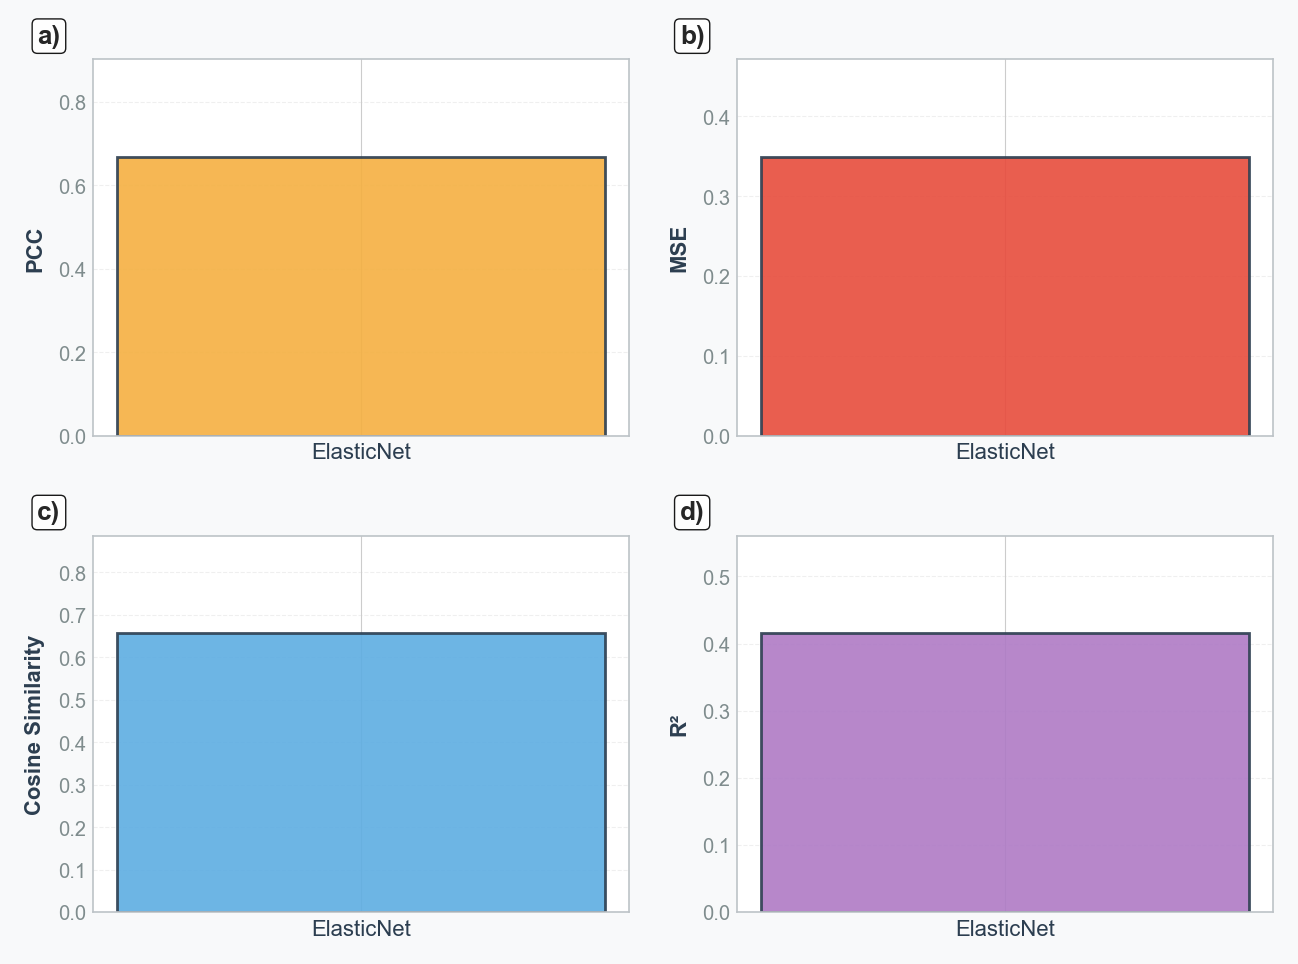

In [13]:
# 8) RAW: overall bar chart
plot_overall_bar(
    mean_metrics_raw,
    out_path=OUT_METRICS_RAW
)


In [14]:
# 9) RAW: detailed tables
per_cell_raw, per_protein_raw, best10_cells_raw, worst10_cells_raw, best10_proteins_raw, worst10_proteins_raw = compute_detailed_tables(
    GT_raw, PRED_raw
)

print("RAW detailed tables:")
print("  cells   :", len(per_cell_raw))
print("  proteins:", len(per_protein_raw))

display(per_cell_raw.head())
display(per_protein_raw.head(10))

RAW detailed tables:
  cells   : 369
  proteins: 5113


,sample,pearson,mse,cosine,r2
254,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.861113,0.355779,0.857569,0.704278
257,OCILY3_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.853181,0.387380,0.857549,0.692568
277,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.851813,0.463647,0.853806,0.674108
97,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.851200,0.304355,0.849703,0.700002
41,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.841333,0.309728,0.840152,0.691873


,protein,pearson,mse,cosine,r2
2016,IGF2BP1,0.908862,0.416145,0.911410,0.825527
433,BASP1,0.906439,1.141386,0.906542,0.817430
2346,MAGEA4,0.898980,0.633953,0.901013,0.801495
2363,MAP1B,0.885239,0.630594,0.885723,0.783257
1719,GNG12,0.885098,0.519501,0.885092,0.783357
924,CORO1A,0.884077,0.552889,0.887314,0.770120
4526,TJP2,0.879913,0.295899,0.879938,0.772144
2233,LCP1,0.879216,0.643812,0.881811,0.767309
1843,HCLS1,0.878749,0.646377,0.881924,0.770159
3655,RBM47,0.877860,0.430100,0.877891,0.769908


Saved: elasticnet_detailed_metrics_raw.png


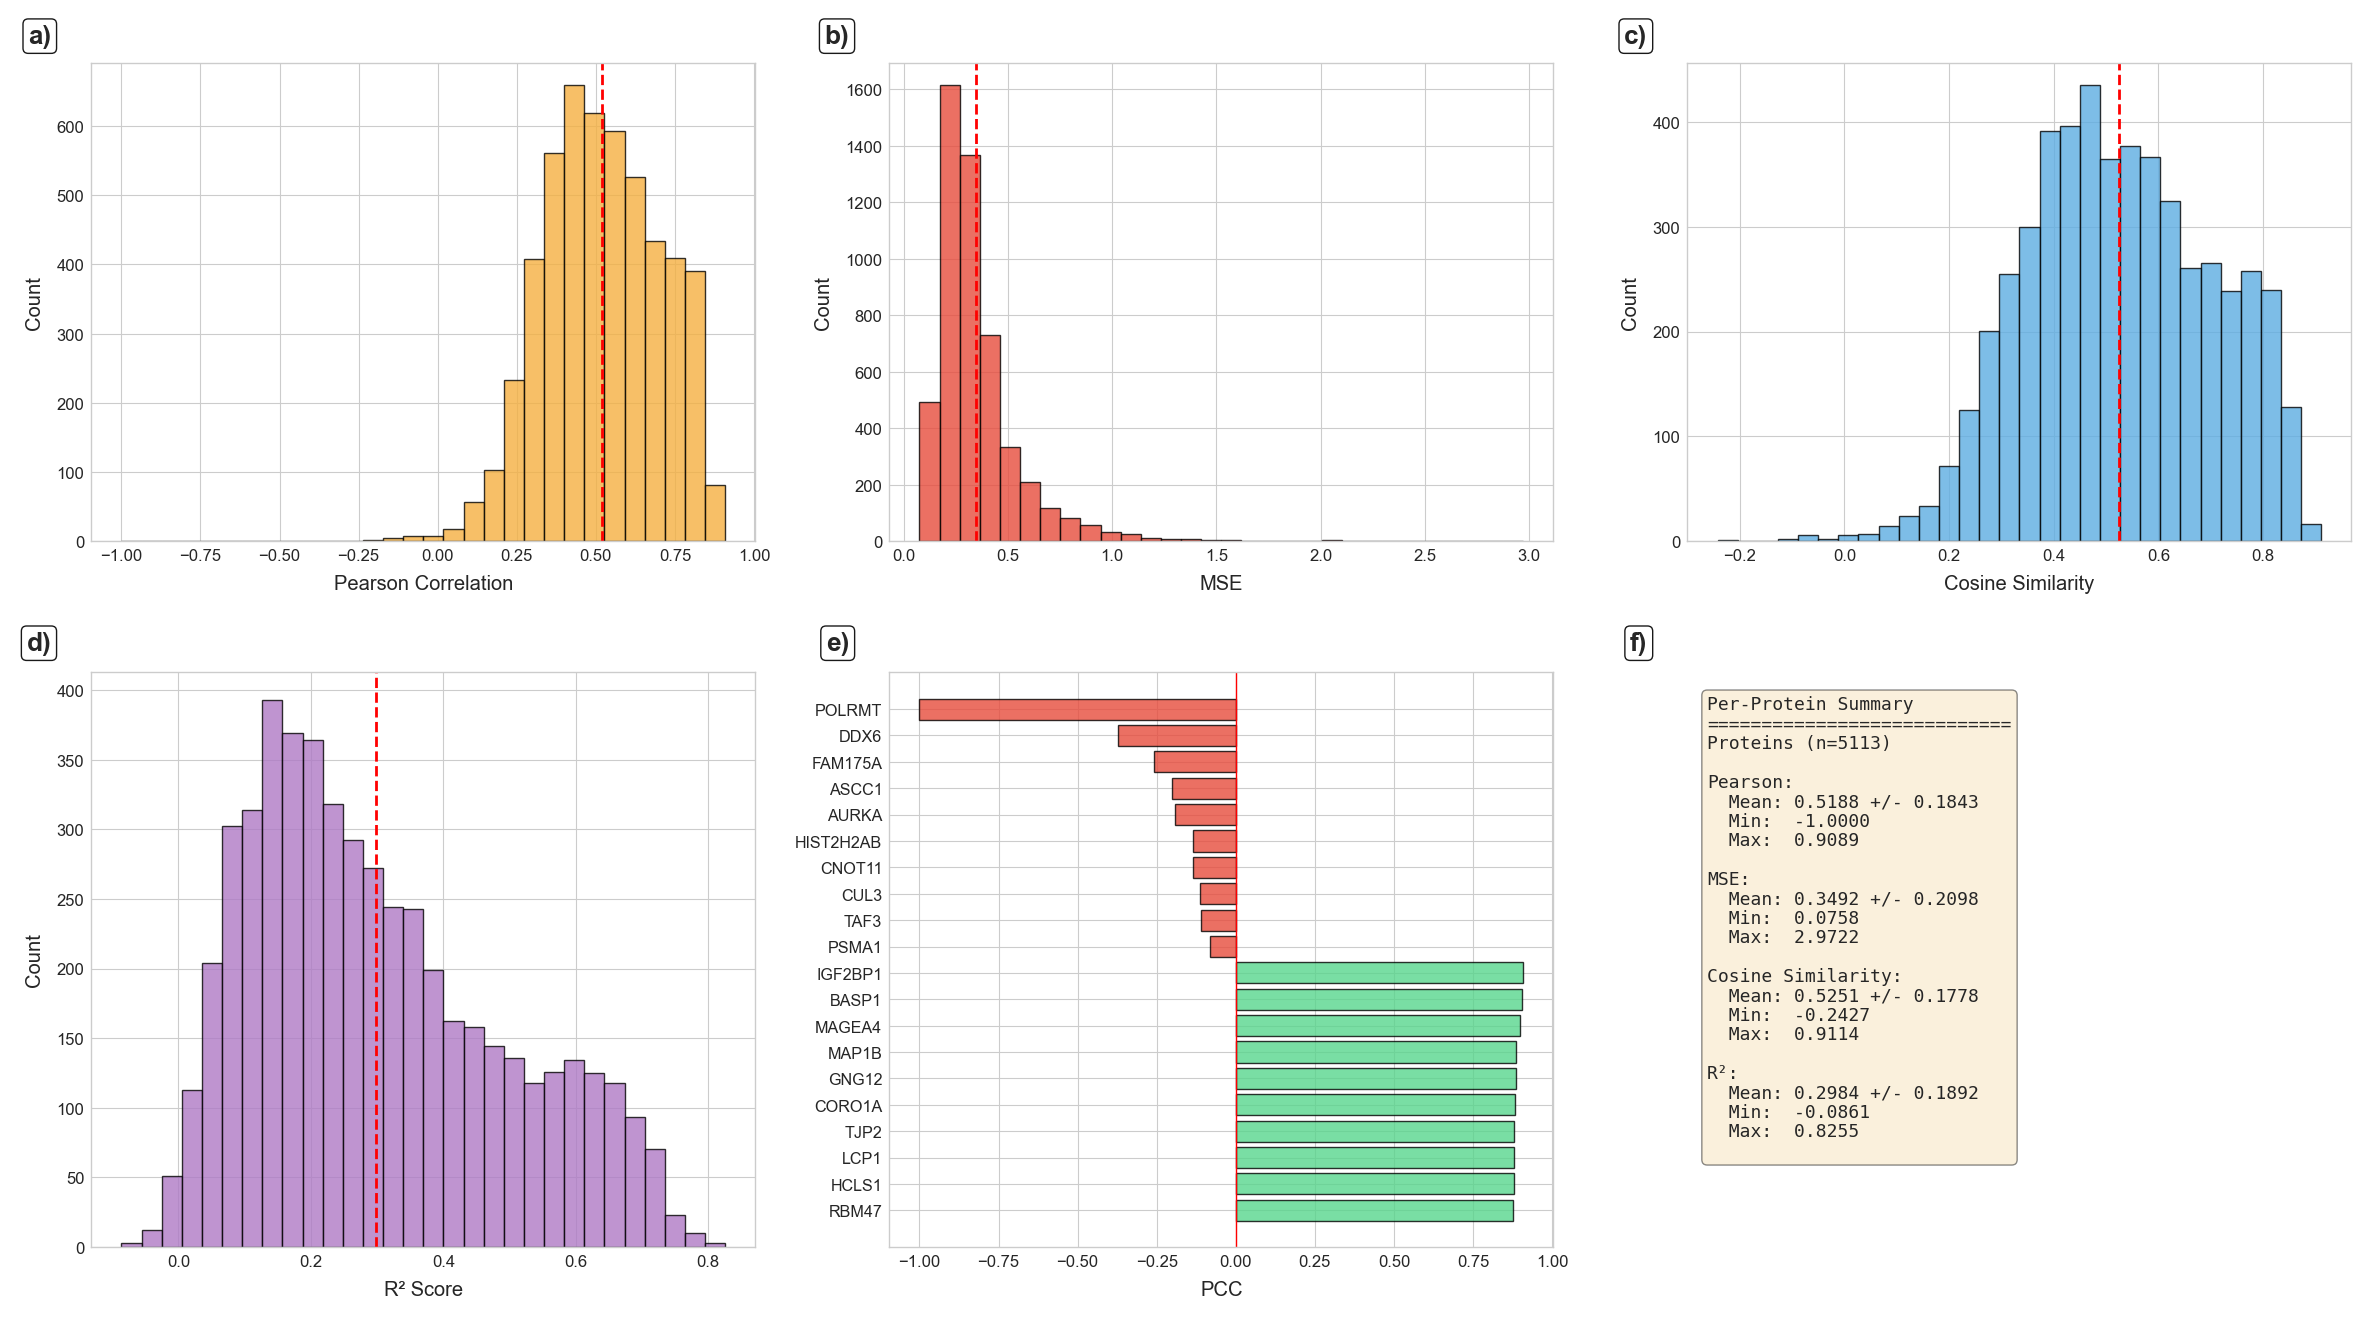

In [15]:
# 10) RAW: detailed visualization
plot_detailed(
    per_cell_raw,
    per_protein_raw,
    group="proteins",
    out_path=OUT_DETAILED_RAW
)


Saved: elasticnet_detailed_metrics_raw.png


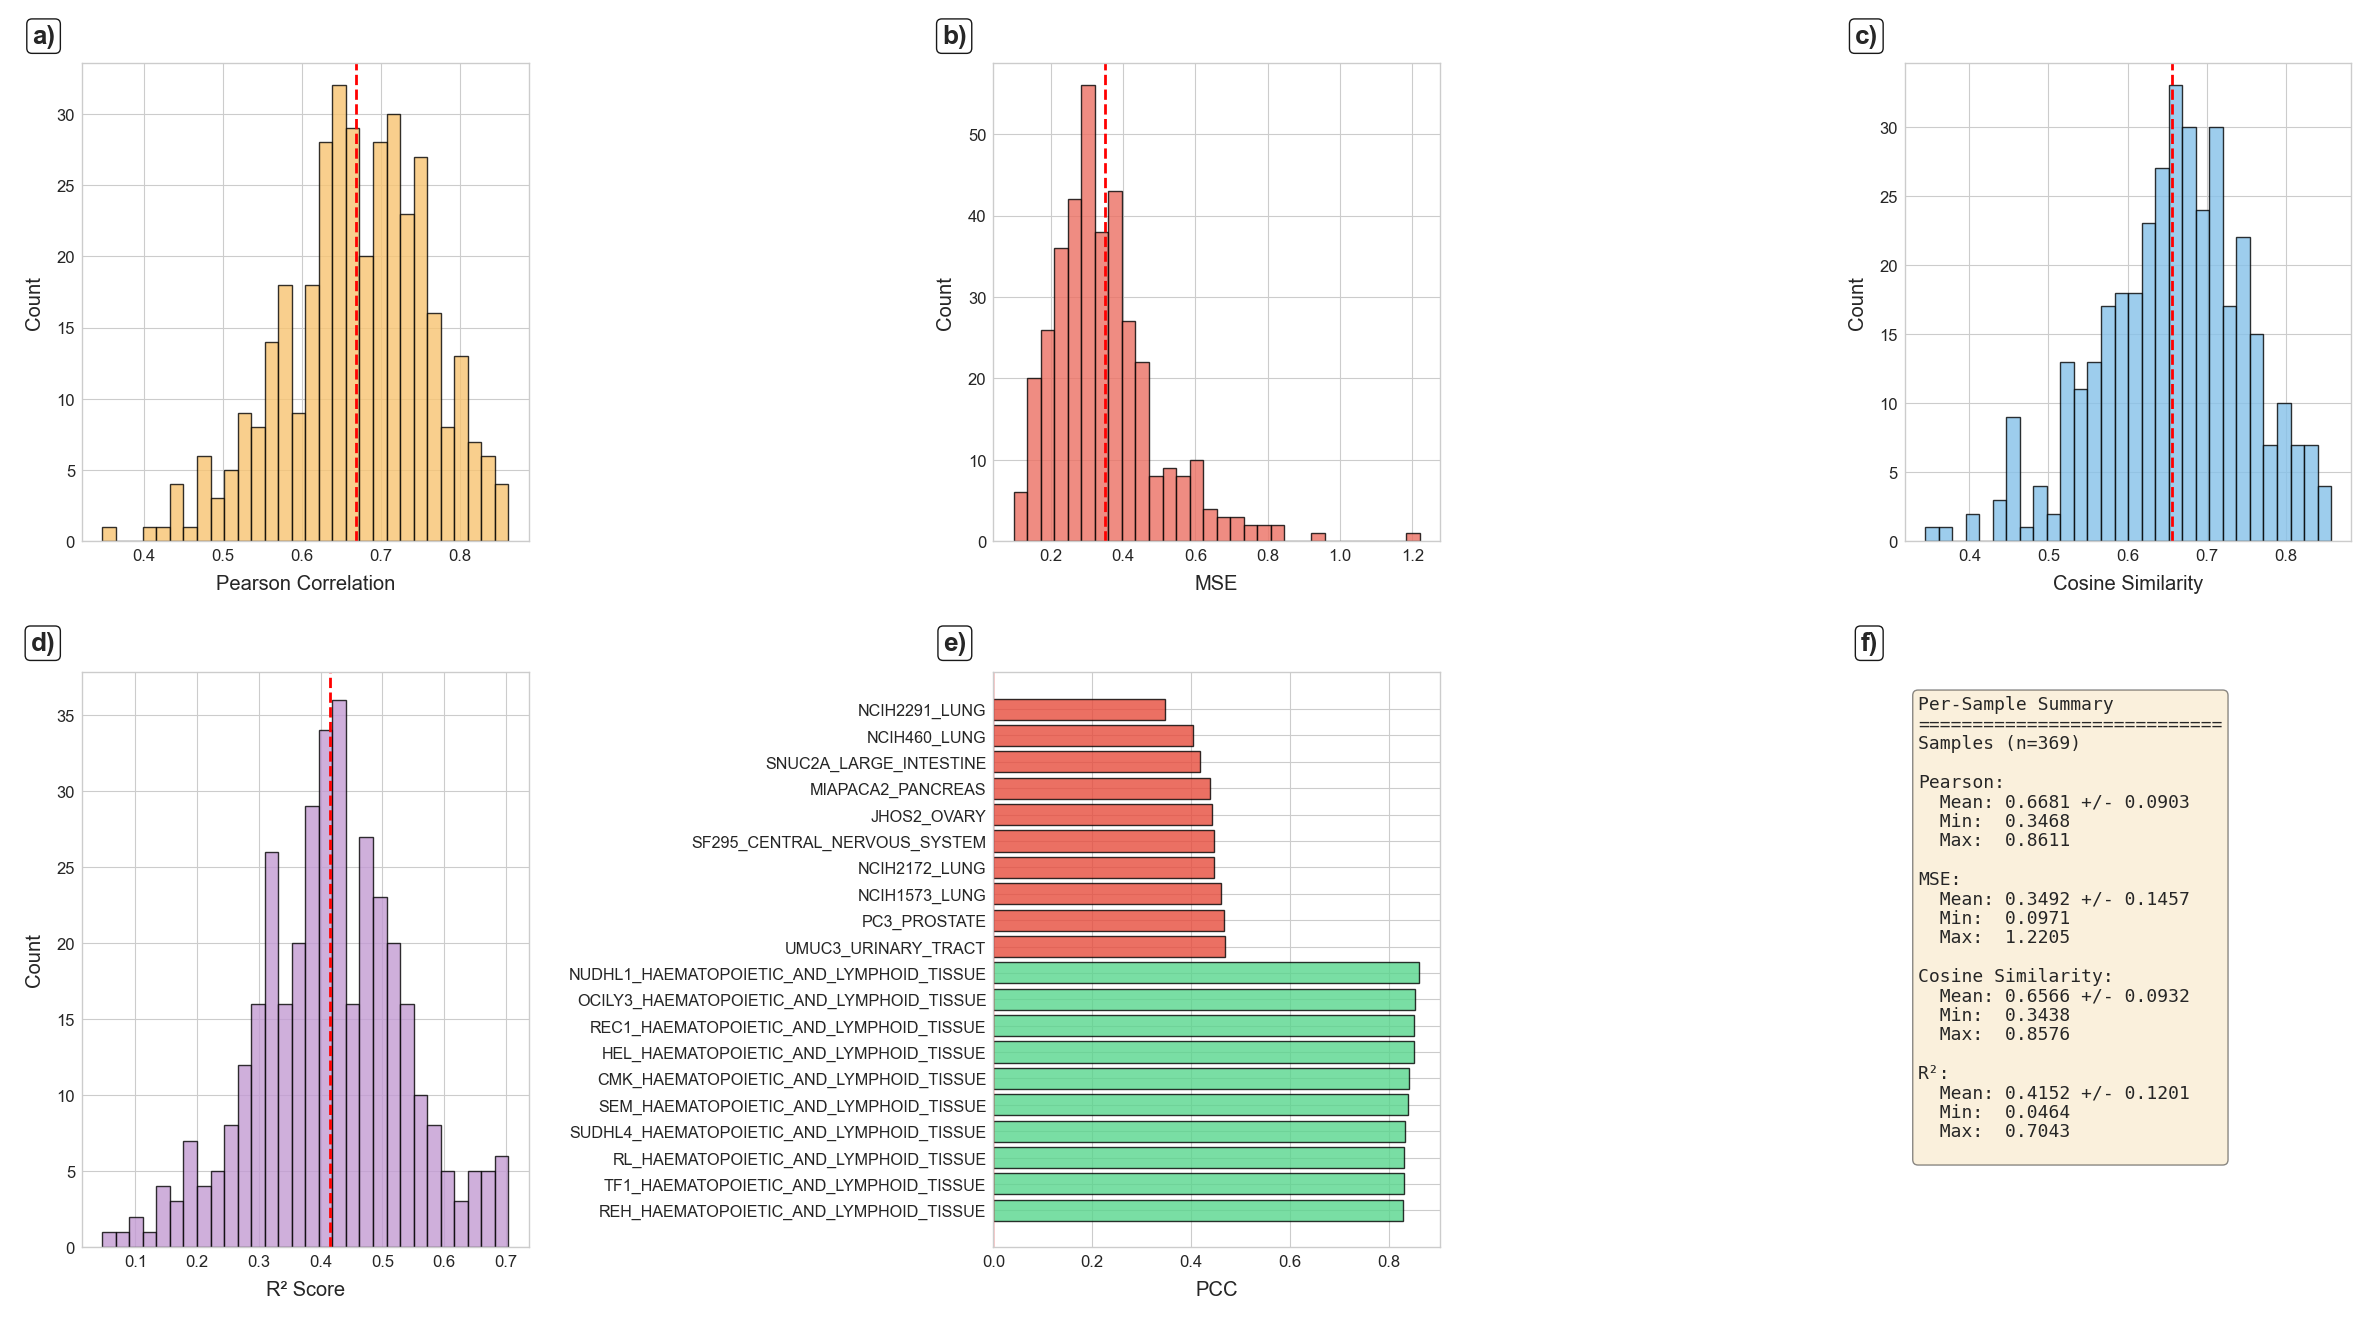

In [16]:
# 10) RAW: detailed visualization
plot_detailed(
    per_cell_raw,
    per_protein_raw,
    group="samples",
    out_path=OUT_DETAILED_RAW
)


# SCALED analysis (per-sample min–max)

In [17]:
# 11) SCALED: compute mean metrics
mean_metrics_scaled = compute_mean_metrics(GT_scaled, PRED_scaled)
print("Mean Metrics (SCALED per-sample min–max):")
for k, v in mean_metrics_scaled.items():
    print(f"  {k:8s}: {v:.6f}")


Mean Metrics (SCALED per-sample min–max):
  MSE     : 0.016814
  RMSE    : 0.115082
  MAE     : 0.100603
  Pearson : 0.668077
  Spearman: 0.569050
  Cosine Similarity: 0.988667
  R2      : -3.218914
  Cosine  : 0.988667


Saved: elasticnet_metrics_scaled.png


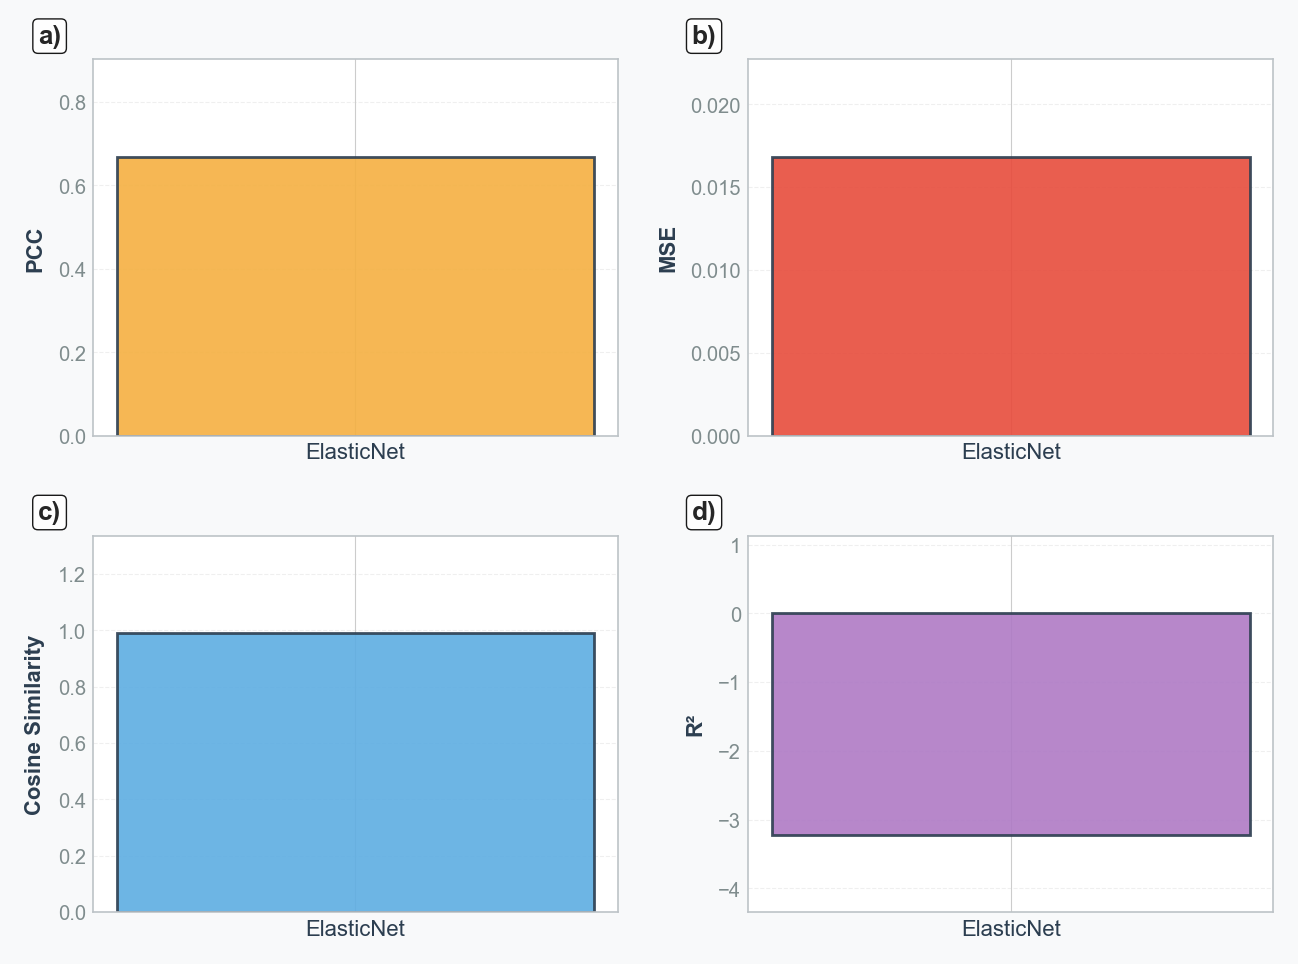

In [18]:
# 12) SCALED: overall bar chart
plot_overall_bar(
    mean_metrics_scaled,
    title="ElasticNet Benchmark: Overall Performance Metrics (SCALED per-sample min–max)",
    out_path=OUT_METRICS_SCALED
)


In [19]:
# 13) SCALED: detailed tables
per_cell_scaled, per_protein_scaled, best10_cells_scaled, worst10_cells_scaled, best10_proteins_scaled, worst10_proteins_scaled = compute_detailed_tables(
    GT_scaled, PRED_scaled
)

print("SCALED detailed tables:")
print("  cells   :", len(per_cell_scaled))
print("  proteins:", len(per_protein_scaled))

display(per_cell_scaled.head())
display(per_protein_scaled.head(10))

SCALED detailed tables:
  cells   : 369
  proteins: 5113


,sample,pearson,mse,cosine,r2
254,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.861113,0.011223,0.992993,-0.508247
257,OCILY3_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.853181,0.002542,0.993834,0.634575
277,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.851813,0.010988,0.993349,-0.462744
97,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.851200,0.003363,0.992981,0.627421
41,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.841333,0.002954,0.994176,0.671274


,protein,pearson,mse,cosine,r2
433,BASP1,0.853678,0.034336,0.948446,0.535943
1386,EPCAM,0.805745,0.034291,0.941196,0.465157
3898,S100A14,0.793624,0.031999,0.943002,0.476622
2346,MAGEA4,0.791338,0.024151,0.952153,0.476529
4402,TACSTD2,0.789501,0.026165,0.950990,0.422856
4306,ST14,0.775901,0.025520,0.951646,0.437819
565,CA2,0.774254,0.028933,0.942762,0.403174
4004,SERPINB5,0.774187,0.025609,0.951477,0.470510
3100,PDLIM4,0.773463,0.025372,0.953330,0.422943
2016,IGF2BP1,0.772038,0.023338,0.951932,0.355209


Saved: elasticnet_detailed_metrics_scaled.png


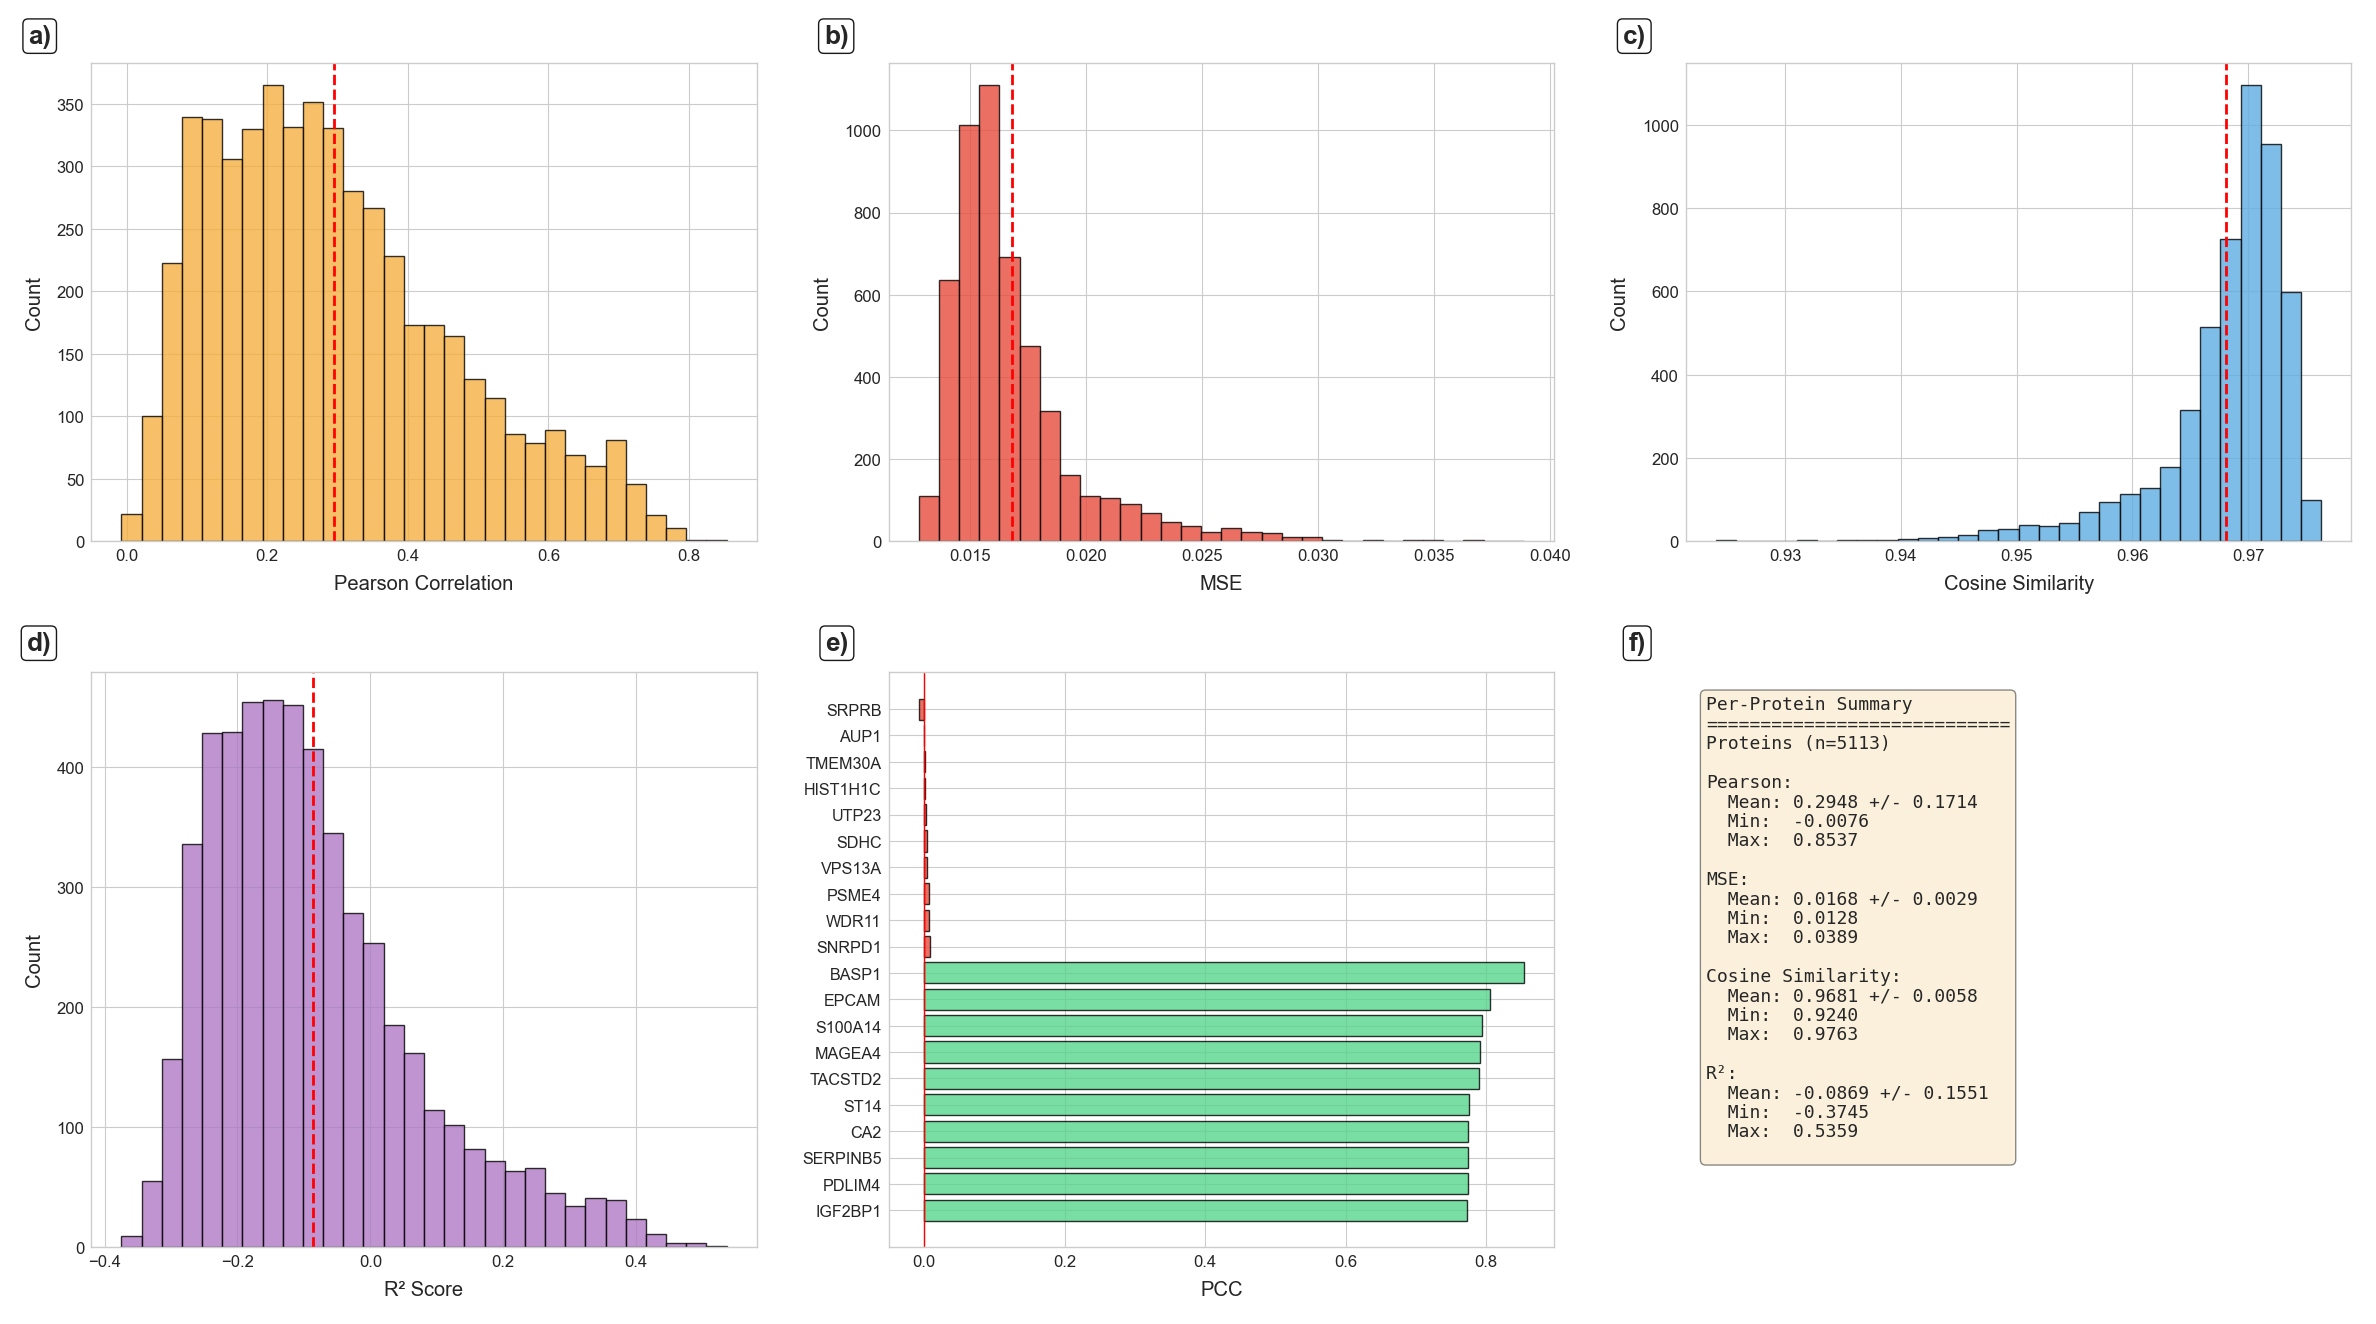

In [20]:
# 14) SCALED: detailed visualization (proteins)
plot_detailed(
    per_protein_df=per_protein_scaled,
    group="proteins",
    out_path=OUT_DETAILED_SCALED
)


Saved: elasticnet_detailed_metrics_scaled.png


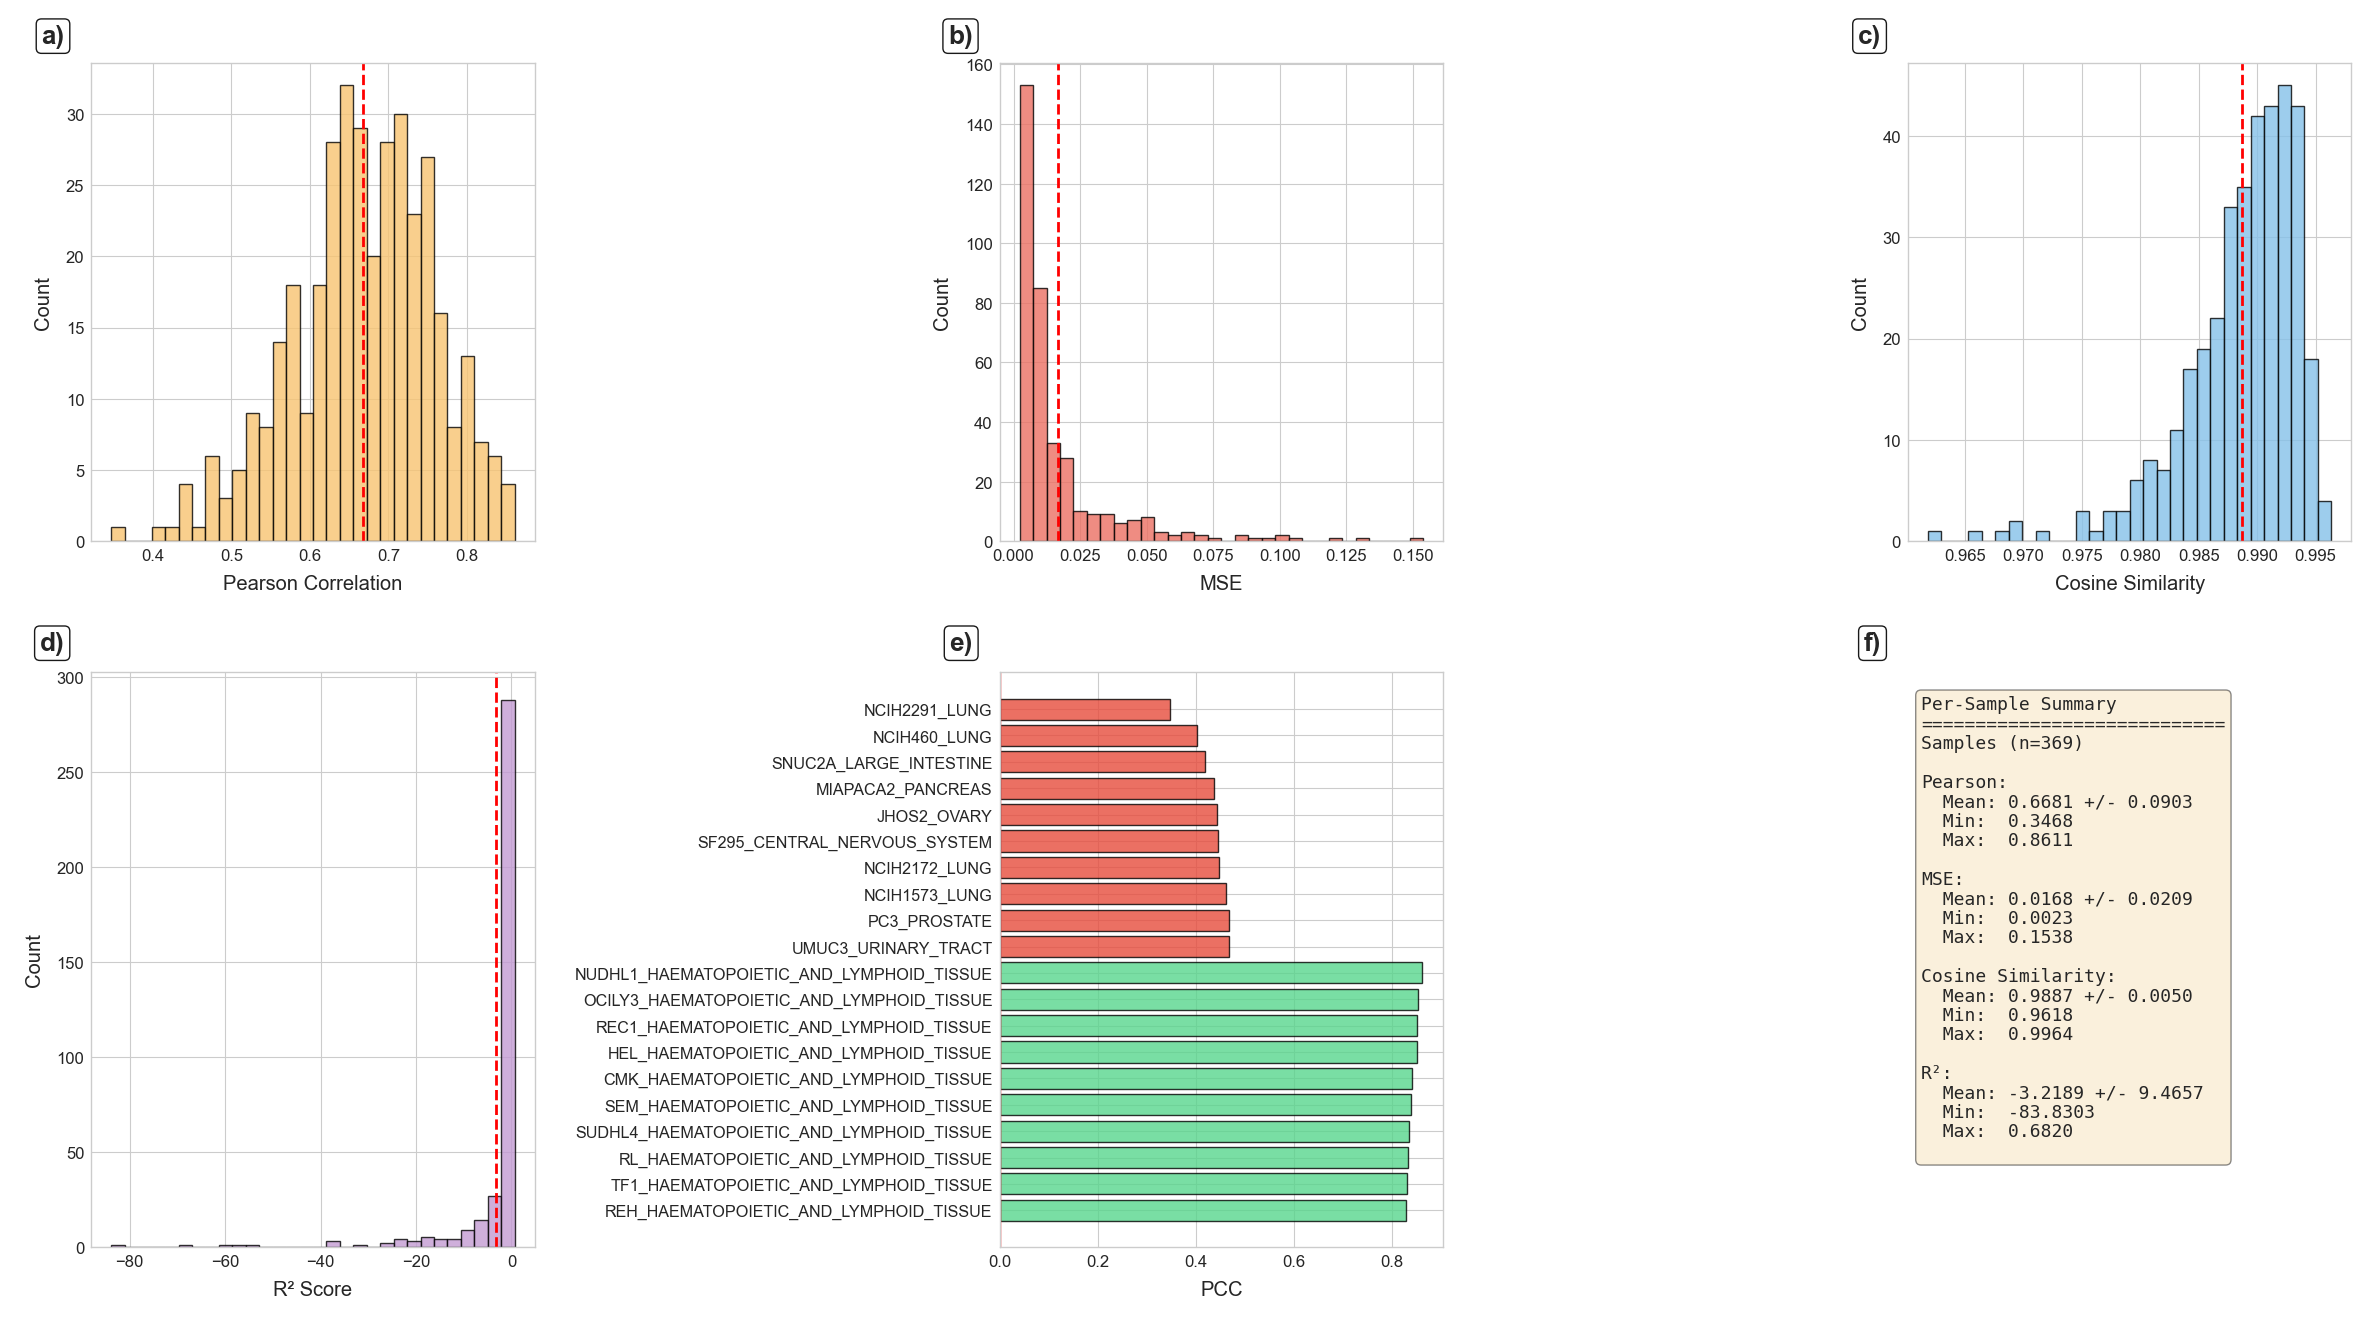

In [21]:
# 15) SCALED: detailed visualization (samples)
plot_detailed(
    per_sample_df=per_cell_scaled,
    group="samples",
    out_path=OUT_DETAILED_SCALED
)

## Optional quick check: correlations should match (almost) exactly

Pearson/Spearman are scale-invariant (with positive scaling), so RAW vs SCALED should match except for constant-vector/NaN edge cases.


In [22]:
print("Mean Pearson RAW   :", float(mean_metrics_raw["Pearson"]))
print("Mean Pearson SCALED:", float(mean_metrics_scaled["Pearson"]))
print("Mean Spearman RAW  :", float(mean_metrics_raw["Spearman"]))
print("Mean Spearman SCALED:", float(mean_metrics_scaled["Spearman"]))


Mean Pearson RAW   : 0.6680773220567542
Mean Pearson SCALED: 0.6680773220567542
Mean Spearman RAW  : 0.5690496986218593
Mean Spearman SCALED: 0.5690496986218593


## scTranslator vs ElasticNet Comparison

We now compare the results of ElasticNet against the model scTranslator. scTranslator has three publically available checkpoints: 10k, 160k, and 2M representing the size of the pre-training. The comparison will re-run the same analysis as we have done above on ElasticNet on the three scTranslator models then we will compare the distributions of the predicted protein abundance of the two models ElasticNet and scTranslator


Below we load the predictions for protein abundance of the three models into a data frame and make sure all cells and proteins are aligned with the Ground Truth scaled we have defined before

In [23]:
# 1b) Load scTranslator predictions (bundled with names/ids)
base_dir = Path(".")
pred_bundle_paths = {
    "2M": base_dir / "res_data/sc_predictions_2M.npz",
    "160K": base_dir / "res_data/sc_predictions_160K.npz",
    "10K": base_dir / "res_data/sc_predictions_10K.npz",
}

bundles = {label: np.load(path) for label, path in pred_bundle_paths.items()}

pred_df_2m = pd.DataFrame(
    bundles["2M"]["predictions"],
    columns=[str(x) for x in bundles["2M"]["protein_names"]],
)
pred_df_160k = pd.DataFrame(
    bundles["160K"]["predictions"],
    columns=[str(x) for x in bundles["160K"]["protein_names"]],
)
pred_df_10k = pd.DataFrame(
    bundles["10K"]["predictions"],
    columns=[str(x) for x in bundles["10K"]["protein_names"]],
)
# 1c) Apply cell names as DataFrame index
pred_df_2m.index = [str(x) for x in bundles["2M"]["cell_names"]]
pred_df_160k.index = [str(x) for x in bundles["160K"]["cell_names"]]
pred_df_10k.index = [str(x) for x in bundles["10K"]["cell_names"]]


#Reindex the order to make suyre
pred_df_2m = pred_df_2m.reindex(index = GT_scaled.index, columns = GT_scaled.columns)
pred_df_160k = pred_df_160k.reindex(index = GT_scaled.index, columns = GT_scaled.columns)
pred_df_10k = pred_df_10k.reindex(index = GT_scaled.index, columns = GT_scaled.columns)

We use the same functions as we have above to compute the mean metrics for all three models of scTranslator then we plot them all side-by-side 

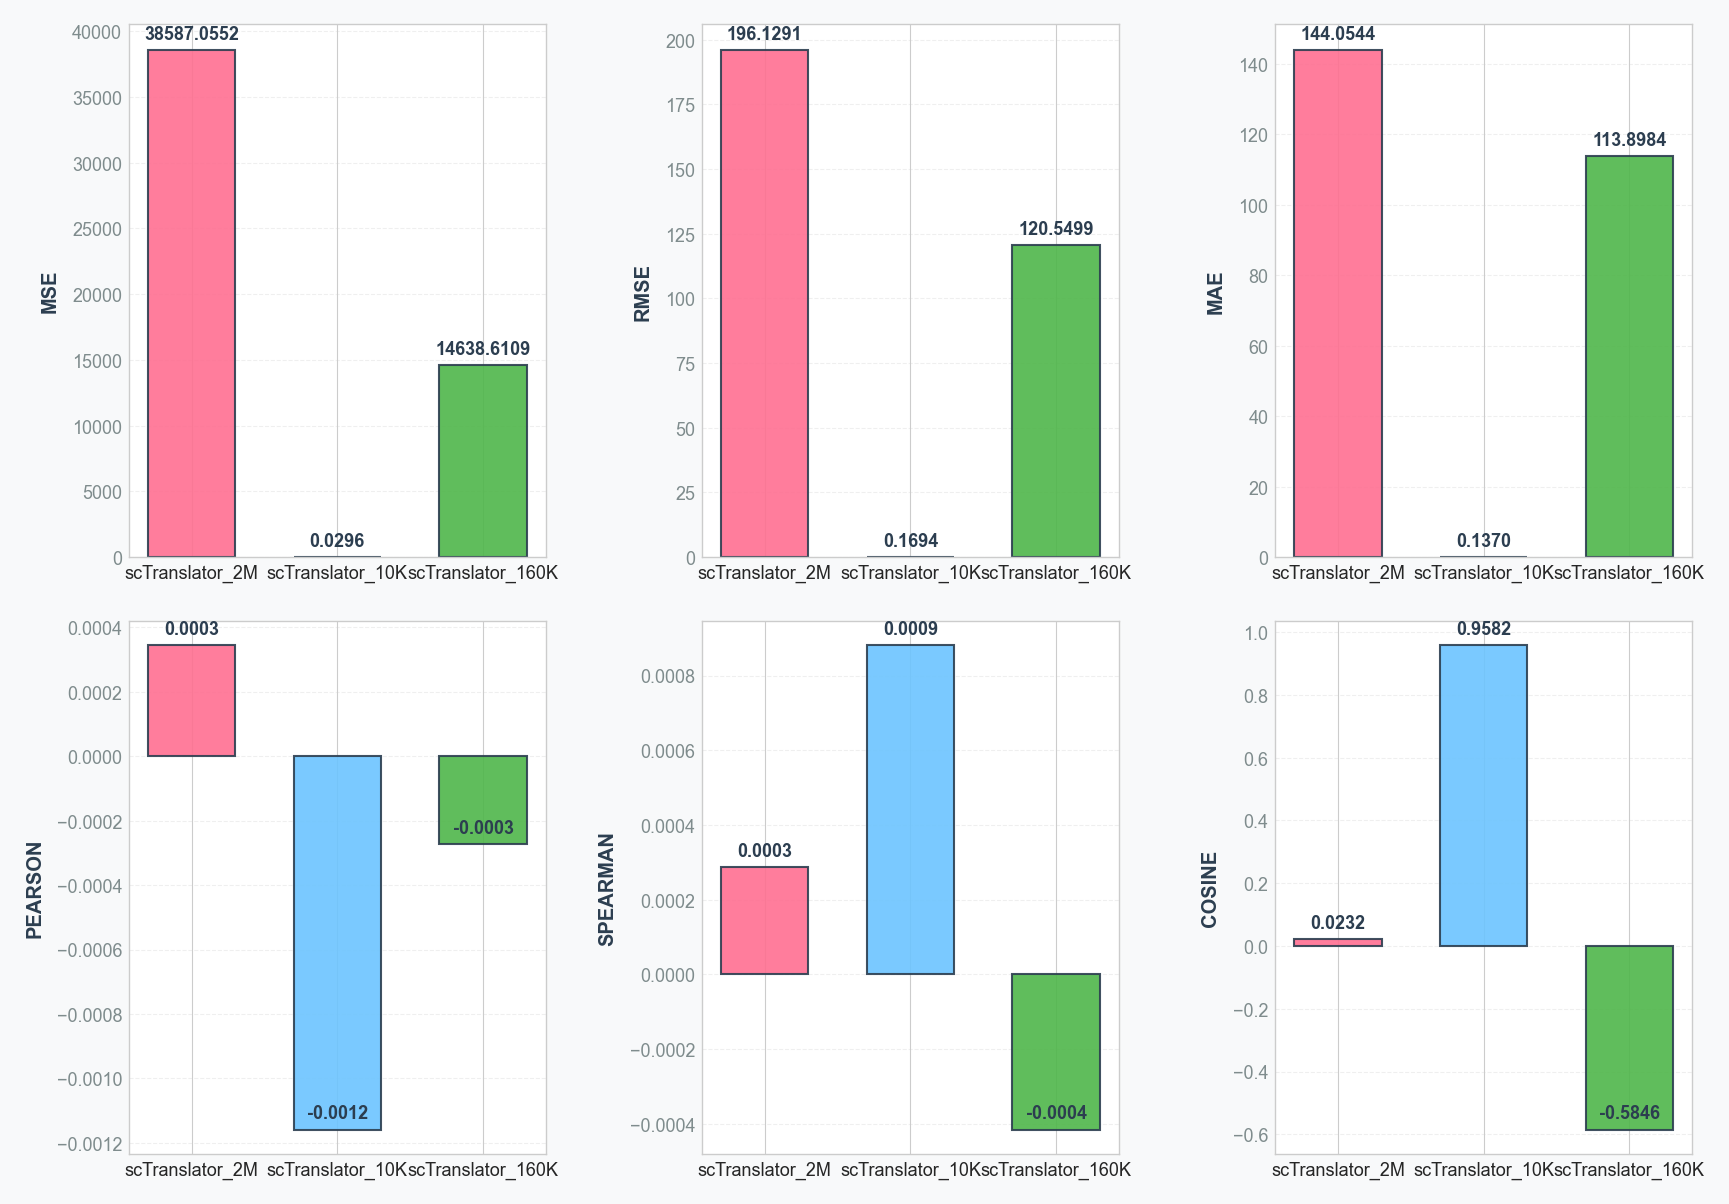

In [24]:
# ---------- compute mean metrics ----------
metrics_2M = compute_mean_metrics(GT_scaled, pred_df_2m)
metrics_10K = compute_mean_metrics(GT_scaled, pred_df_10k)
metrics_160K = compute_mean_metrics(GT_scaled, pred_df_160k)

# ---------- build table for plotting ----------
models = ["scTranslator_2M", "scTranslator_10K", "scTranslator_160K"]
metric_order = [
    ("Mean Squared Error", "MSE"),
    ("Root MSE", "RMSE"),
    ("Mean Absolute Error", "MAE"),
    ("Pearson Correlation", "Pearson"),
    ("Spearman Correlation", "Spearman"),
    ("Cosine Similarity", "Cosine"),
]

metrics_df = pd.DataFrame(
    [metrics_2M, metrics_10K, metrics_160K],
    index=models
)

# ---------- plot ----------
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 3, figsize=readable_figsize((16, 10)))
fig.patch.set_facecolor("#F8F9FA")
_remember_figure_name(fig, "scTranslator Benchmark: Overall Performance Metrics")

bar_colors = ["#FF6F91", "#6CC4FF", "#4FB64A"]  # pink, blue, green

for idx, (title, key) in enumerate(metric_order):
    row, col = divmod(idx, 3)
    ax = axes[row, col]
    ax.set_facecolor("#FFFFFF")

    values = metrics_df[key].values.astype(float)
    bars = ax.bar(models, values, color=bar_colors, width=0.6,
                  edgecolor="#2C3E50", linewidth=1.5, alpha=0.9)

    # value labels
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.4f}",
                    xy=(b.get_x() + b.get_width()/2, h),
                    xytext=(0, 5),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=13.0, fontweight="bold", color="#2C3E50")

    _remember_axes_name(ax, title)
    ax.set_ylabel(key.upper(), fontsize=14.5, fontweight="bold", color="#2C3E50")
    ax.tick_params(axis="x", labelsize=13.0, rotation=0)
    ax.tick_params(axis="y", labelsize=13.0, colors="#7F8C8D")
    ax.yaxis.grid(True, linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
show_readable_figures()

### Focused 10K comparison used in this notebook

This section highlights the **same aligned intersection of cells and proteins** used for the 10K comparison cells below.

- `pred_best_10k` is used when it already exists in memory.
- If `pred_best_10k` is not defined, the notebook falls back to the original `pred_df_10k` loaded from the 10K bundle.
- The comparison barplots keep **proteins on the top row** and **samples on the bottom row**.
- Two figures are generated:
  1. **Pred-best-10K vs ElasticNet (min-max scaled)**
  2. **ElasticNet raw vs ElasticNet min-max scaled**


`pred_best_10k` was not found; falling back to bundle-loaded `pred_df_10k`.
Aligned comparison subset: 369 cells x 5113 proteins
Saved: comparison_plots\pred_best_10k_vs_enet_minmax_barplot.png


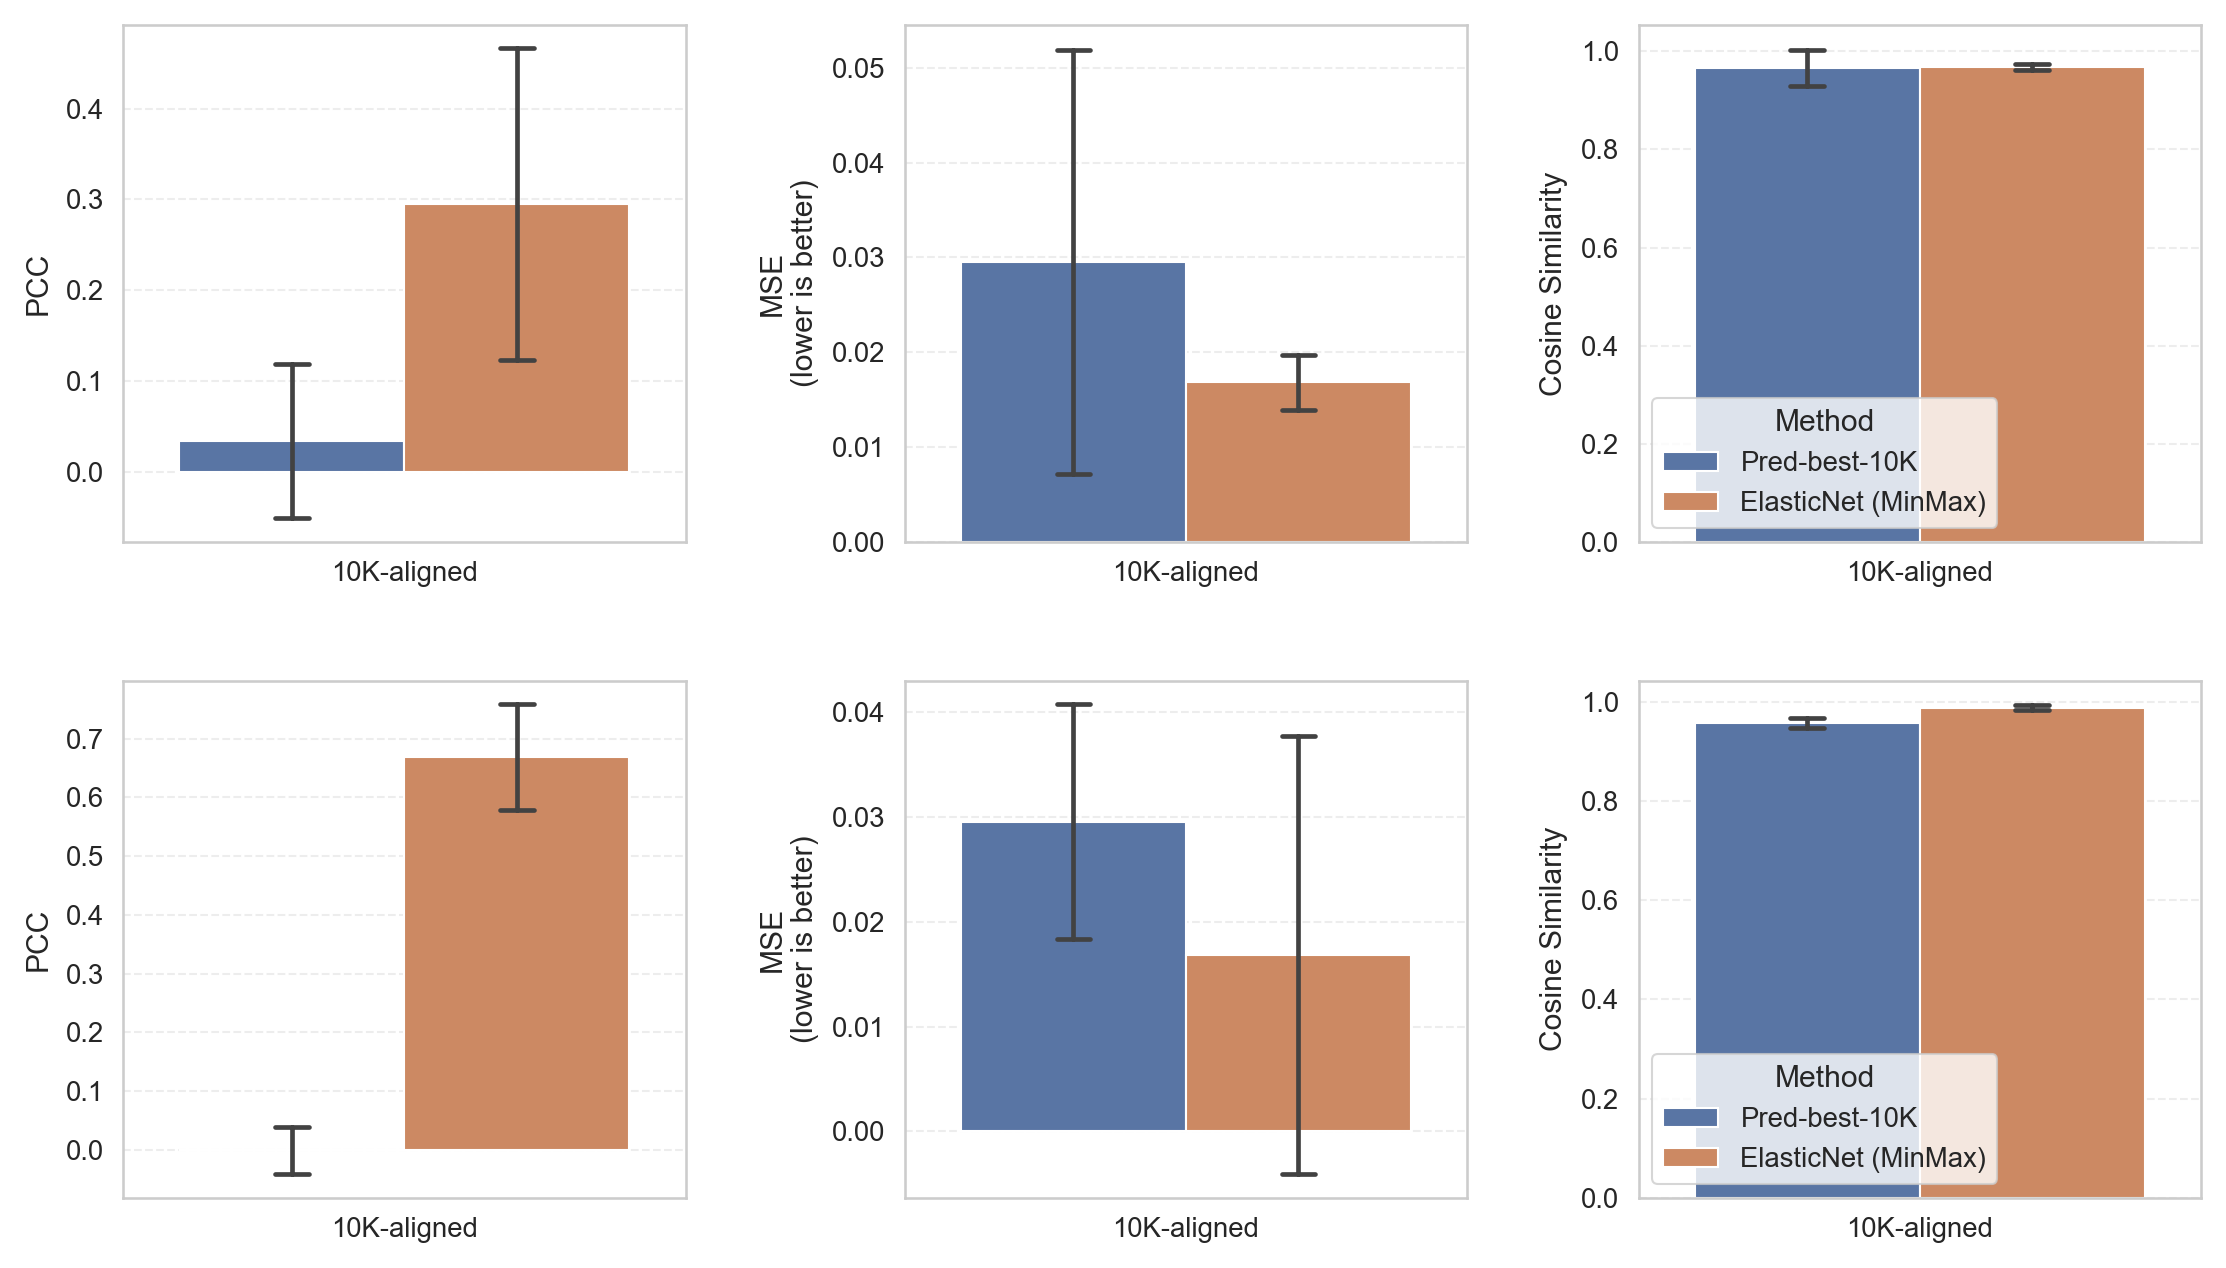

Saved: comparison_plots\enet_raw_vs_minmax_barplot.png


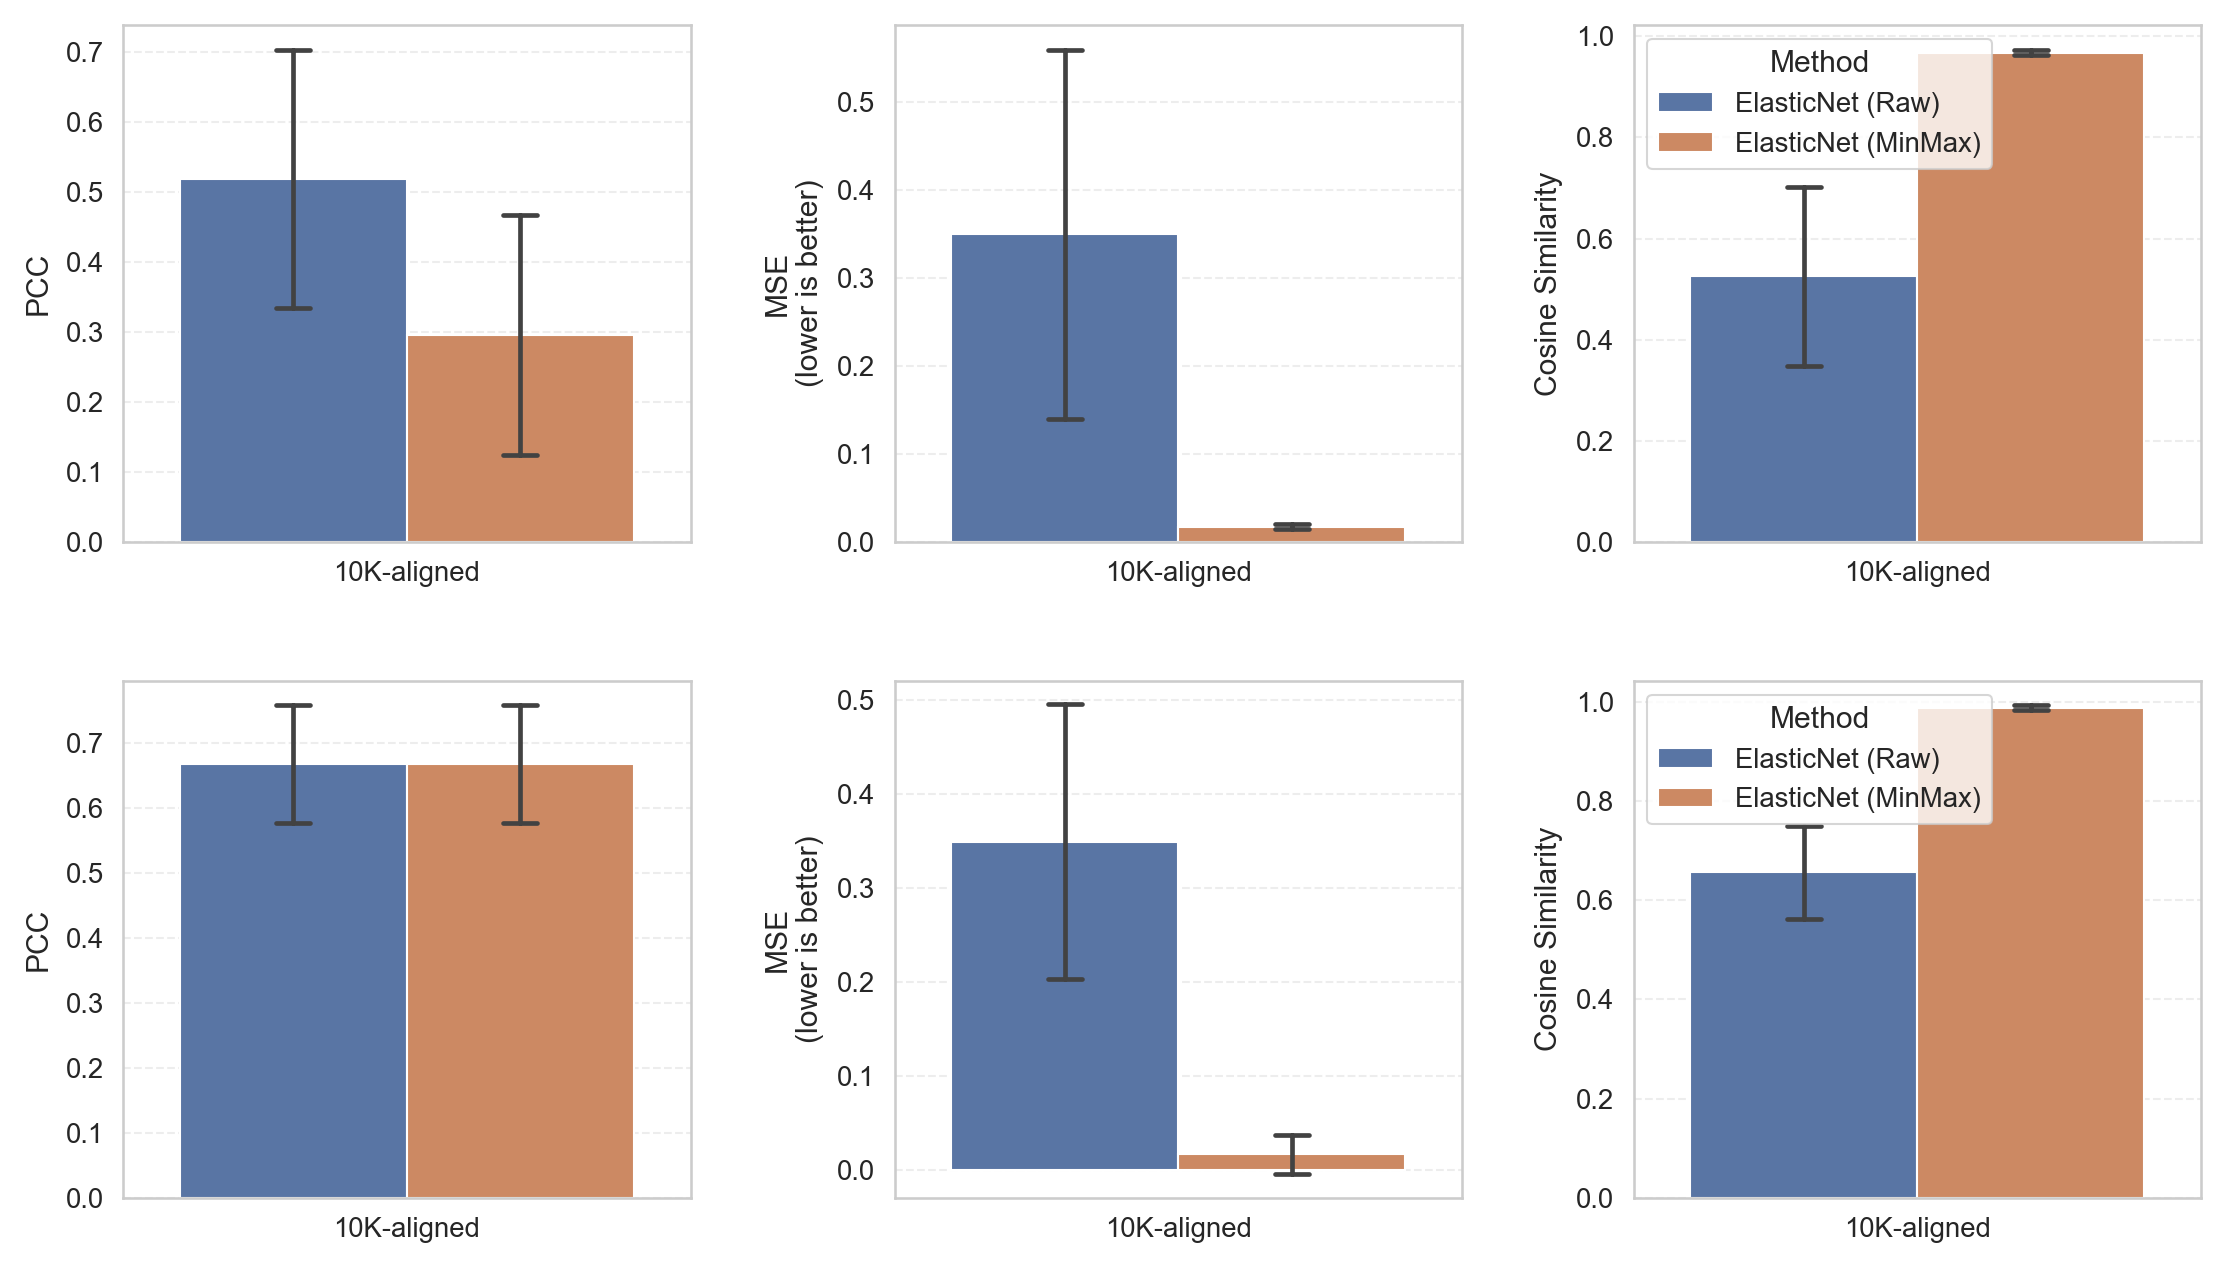

,Comparison,Cells considered,Proteins considered,Figure file
0,Pred-best-10K vs ElasticNet (MinMax),369,5113,comparison_plots\pred_best_10k_vs_enet_minmax_...
1,ElasticNet (Raw) vs ElasticNet (MinMax),369,5113,comparison_plots\enet_raw_vs_minmax_barplot.png


In [25]:
import seaborn as sns

COMPARISON_DIR = Path("comparison_plots")
COMPARISON_DIR.mkdir(exist_ok=True)

def _coerce_prediction_df(pred_like, reference_df):
    if isinstance(pred_like, pd.DataFrame):
        pred_df = pred_like.copy()
    else:
        pred_df = pd.DataFrame(pred_like, index=reference_df.index, columns=reference_df.columns)

    pred_df.index = pred_df.index.map(str)
    pred_df.columns = pred_df.columns.map(str)
    return pred_df

def build_raw_metric_frames(ground_truth, predictions, method_name, dataset_name="10K-aligned"):
    per_sample_df, per_protein_df, *_ = compute_detailed_tables(ground_truth, predictions)

    sample_metrics = per_sample_df.rename(columns={
        "pearson": "PCC",
        "mse": "MSE",
        "cosine": "Cosine Similarity",
        "r2": "R2",
    }).copy()
    sample_metrics["Dataset"] = dataset_name
    sample_metrics["Method"] = method_name

    protein_metrics = per_protein_df.rename(columns={
        "pearson": "PCC",
        "mse": "MSE",
        "cosine": "Cosine Similarity",
        "r2": "R2",
    }).copy()
    protein_metrics["Dataset"] = dataset_name
    protein_metrics["Method"] = method_name

    return sample_metrics, protein_metrics

def plot_metric_comparison_barplots(raw_sample_metrics, raw_protein_metrics, title, out_path=None):
    set_readable_theme(style="whitegrid", context="talk")

    metrics_to_plot = ["PCC", "MSE", "Cosine Similarity"]
    fig, axes = plt.subplots(2, 3, figsize=readable_figsize((20, 10)), constrained_layout=True)

    for col, metric in enumerate(metrics_to_plot):
        ax = axes[0, col]
        sns.barplot(
            data=raw_protein_metrics,
            x="Dataset",
            y=metric,
            hue="Method",
            errorbar="sd",
            capsize=0.12,
            ax=ax,
        )
        _remember_axes_name(ax, f"Protein-wise {metric}")
        ax.set_xlabel("")
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        if metric == "MSE":
            ax.set_ylabel("MSE\n(lower is better)")
        else:
            ax.set_ylabel(metric)

        if col == 2:
            ax.legend(title="Method", frameon=True)
        else:
            ax.get_legend().remove()

    for col, metric in enumerate(metrics_to_plot):
        ax = axes[1, col]
        sns.barplot(
            data=raw_sample_metrics,
            x="Dataset",
            y=metric,
            hue="Method",
            errorbar="sd",
            capsize=0.12,
            ax=ax,
        )
        _remember_axes_name(ax, f"Sample-wise {metric}")
        ax.set_xlabel("")
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        if metric == "MSE":
            ax.set_ylabel("MSE\n(lower is better)")
        else:
            ax.set_ylabel(metric)

        if col == 2:
            ax.legend(title="Method", frameon=True)
        else:
            ax.get_legend().remove()

    _remember_figure_name(fig, title)

    if out_path is not None:
        save_readable_current_figure(out_path, dpi=180, bbox_inches="tight")
        print(f"Saved: {out_path}")
    show_readable_figures()

# Prefer pred_best_10k if it already exists, otherwise fall back to pred_df_10k from the bundle.
if "pred_best_10k" in globals():
    pred_best_10k_source = pred_best_10k
    print("Using existing `pred_best_10k` from memory.")
else:
    pred_best_10k_source = pred_df_10k
    print("`pred_best_10k` was not found; falling back to bundle-loaded `pred_df_10k`.")

pred_best_10k_df = _coerce_prediction_df(pred_best_10k_source, GT_scaled)
pred_best_10k_df = pred_best_10k_df.reindex(index=GT_scaled.index.map(str), columns=GT_scaled.columns.map(str))

GT_raw_cmp = GT_raw.copy()
PRED_raw_cmp = PRED_raw.copy()
GT_scaled_cmp = GT_scaled.copy()
PRED_scaled_cmp = PRED_scaled.copy()

GT_raw_cmp.index = GT_raw_cmp.index.map(str)
GT_raw_cmp.columns = GT_raw_cmp.columns.map(str)
PRED_raw_cmp.index = PRED_raw_cmp.index.map(str)
PRED_raw_cmp.columns = PRED_raw_cmp.columns.map(str)
GT_scaled_cmp.index = GT_scaled_cmp.index.map(str)
GT_scaled_cmp.columns = GT_scaled_cmp.columns.map(str)
PRED_scaled_cmp.index = PRED_scaled_cmp.index.map(str)
PRED_scaled_cmp.columns = PRED_scaled_cmp.columns.map(str)

common_index = (
    GT_scaled_cmp.index
    .intersection(PRED_scaled_cmp.index)
    .intersection(pred_best_10k_df.index)
    .intersection(GT_raw_cmp.index)
    .intersection(PRED_raw_cmp.index)
)
common_cols = (
    GT_scaled_cmp.columns
    .intersection(PRED_scaled_cmp.columns)
    .intersection(pred_best_10k_df.columns)
    .intersection(GT_raw_cmp.columns)
    .intersection(PRED_raw_cmp.columns)
)

GT_scaled_10k = GT_scaled_cmp.loc[common_index, common_cols]
PRED_scaled_10k = PRED_scaled_cmp.loc[common_index, common_cols]
pred_best_10k_aligned = pred_best_10k_df.loc[common_index, common_cols]
GT_raw_10k = GT_raw_cmp.loc[common_index, common_cols]
PRED_raw_10k = PRED_raw_cmp.loc[common_index, common_cols]

print(f"Aligned comparison subset: {len(common_index)} cells x {len(common_cols)} proteins")

# --- Figure 1: Pred-best-10K vs ElasticNet on min-max scaled values ---
sample_best_scaled, protein_best_scaled = build_raw_metric_frames(
    GT_scaled_10k,
    pred_best_10k_aligned,
    method_name="Pred-best-10K",
    dataset_name="10K-aligned",
)

sample_enet_scaled, protein_enet_scaled = build_raw_metric_frames(
    GT_scaled_10k,
    PRED_scaled_10k,
    method_name="ElasticNet (MinMax)",
    dataset_name="10K-aligned",
)

raw_sample_metrics_scaled_cmp = pd.concat([sample_best_scaled, sample_enet_scaled], ignore_index=True)
raw_protein_metrics_scaled_cmp = pd.concat([protein_best_scaled, protein_enet_scaled], ignore_index=True)

plot_metric_comparison_barplots(
    raw_sample_metrics_scaled_cmp,
    raw_protein_metrics_scaled_cmp,
    title="Pred-best-10K vs ElasticNet (Raw metrics on min-max scaled values)",
    out_path=COMPARISON_DIR / "pred_best_10k_vs_enet_minmax_barplot.png",
)

# --- Figure 2: ElasticNet raw vs ElasticNet min-max scaled ---
sample_enet_raw, protein_enet_raw = build_raw_metric_frames(
    GT_raw_10k,
    PRED_raw_10k,
    method_name="ElasticNet (Raw)",
    dataset_name="10K-aligned",
)

sample_enet_scaled_only, protein_enet_scaled_only = build_raw_metric_frames(
    GT_scaled_10k,
    PRED_scaled_10k,
    method_name="ElasticNet (MinMax)",
    dataset_name="10K-aligned",
)

raw_sample_metrics_enet_scale_cmp = pd.concat([sample_enet_raw, sample_enet_scaled_only], ignore_index=True)
raw_protein_metrics_enet_scale_cmp = pd.concat([protein_enet_raw, protein_enet_scaled_only], ignore_index=True)

plot_metric_comparison_barplots(
    raw_sample_metrics_enet_scale_cmp,
    raw_protein_metrics_enet_scale_cmp,
    title="ElasticNet raw vs ElasticNet min-max scaled (same 10K-aligned subset)",
    out_path=COMPARISON_DIR / "enet_raw_vs_minmax_barplot.png",
)

comparison_overview = pd.DataFrame({
    "Comparison": [
        "Pred-best-10K vs ElasticNet (MinMax)",
        "ElasticNet (Raw) vs ElasticNet (MinMax)",
    ],
    "Cells considered": [len(common_index), len(common_index)],
    "Proteins considered": [len(common_cols), len(common_cols)],
    "Figure file": [
        str(COMPARISON_DIR / "pred_best_10k_vs_enet_minmax_barplot.png"),
        str(COMPARISON_DIR / "enet_raw_vs_minmax_barplot.png"),
    ],
})
display(comparison_overview)


#### To get more insight into model-specific performance of scTranslator we now plot metrics for each specific model. The plot above is averaged across samples in the dataset so it says nothing of the distribution of these metrics across cells and moreover across proteins. Thus below we plot histograms of Per-cell MSE, Cosine Similarity and then do the same Per-Protein. Moreover we plot the top 10 and bottom 10 proteins ranked by PCC

Analysis for 10k

In [26]:
# scTranslator 10K: detailed tables
per_cell_10k, per_protein_10k, best10_cells_10k, worst10_cells_10k, best10_proteins_10k, worst10_proteins_10k = compute_detailed_tables(
    GT_scaled, pred_df_10k
)

print("10K detailed tables:")
print("  cells   :", len(per_cell_10k))
print("  proteins:", len(per_protein_10k))

display(per_cell_10k.head())
display(per_protein_10k.head(10))

10K detailed tables:
  cells   : 369
  proteins: 5112


,sample,pearson,mse,cosine,r2
26,CAKI1_KIDNEY,0.108230,0.028818,0.969401,-4.075613
201,MONOMAC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.088192,0.024237,0.955166,-0.832556
240,NCIH441_LUNG,0.086799,0.024410,0.969626,-3.207242
228,NCIH2122_LUNG,0.082265,0.023675,0.955550,-1.427793
223,NCIH1975_LUNG,0.081639,0.016793,0.967496,-2.395932


,protein,pearson,mse,cosine,r2
4442,TBCA,0.360360,0.056040,0.958037,-1.576343
693,CD9,0.336713,0.035969,0.935128,-0.021919
2200,KTI12,0.320515,0.027781,0.971563,-0.885555
3017,PAFAH1B3,0.312388,0.019270,0.963699,-0.021478
4593,TNRC6B,0.308993,0.016204,0.974851,-0.243271
4778,UBE2N,0.301594,0.023336,0.965825,-0.336674
1593,FTO,0.287951,0.017471,0.966595,-0.044127
3483,PSPH,0.286030,0.022839,0.960039,-0.079192
346,ATE1,0.283959,0.021349,0.970171,-0.431564
4330,STMN1,0.282122,0.026613,0.948339,-0.009959


Analysis for 160k

In [27]:
# scTranslator 160K: detailed tables
per_cell_160k, per_protein_160k, best10_cells_160k, worst10_cells_160k, best10_proteins_160k, worst10_proteins_160k = compute_detailed_tables(
    GT_scaled, pred_df_160k
)

print("160K detailed tables:")
print("  cells   :", len(per_cell_160k))
print("  proteins:", len(per_protein_160k))

display(per_cell_160k.head())
display(per_protein_160k.head(10))

160K detailed tables:
  cells   : 369
  proteins: 5112


,sample,pearson,mse,cosine,r2
132,JHH5_LIVER,0.049754,13288.457435,-0.572674,-1.966193e+06
266,OVSAHO_OVARY,0.044304,13056.819125,-0.563872,-7.887214e+05
159,KURAMOCHI_OVARY,0.042827,13959.969160,-0.568850,-1.143300e+06
291,SAOS2_BONE,0.041193,17753.110005,-0.562826,-1.403230e+06
124,IGROV1_OVARY,0.039688,14275.255884,-0.591932,-7.874328e+06


,protein,pearson,mse,cosine,r2
3723,RNASET2,0.259485,23459.190161,-0.928060,-727998.703684
2927,NUDT8,0.247183,12441.940538,-0.953095,-650187.252450
2606,MRRF,0.243959,13910.119643,-0.963171,-971634.702141
2318,LSP1,0.242302,19892.487131,-0.913097,-594356.244523
806,CIB1,0.242143,15664.629914,-0.947055,-702822.667908
3140,PFN2,0.241027,3037.793013,0.952669,-116086.867066
1505,FAM83H,0.236855,11938.161391,-0.942491,-492571.868219
2500,MISP,0.233911,16883.378064,-0.910108,-390360.246586
1353,ELF1,0.232107,11276.946574,-0.951647,-585758.170717
4305,ST14,0.231272,12846.632587,-0.900753,-282996.643131


Analysis for 2M

In [28]:
# scTranslator 2M: detailed tables
per_cell_2m, per_protein_2m, best10_cells_2m, worst10_cells_2m, best10_proteins_2m, worst10_proteins_2m = compute_detailed_tables(
    GT_scaled, pred_df_2m
)

print("2M detailed tables:")
print("  cells   :", len(per_cell_2m))
print("  proteins:", len(per_protein_2m))

display(per_cell_2m.head())
display(per_protein_2m.head(10))

2M detailed tables:
  cells   : 369
  proteins: 5112


,sample,pearson,mse,cosine,r2
245,NCIH647_LUNG,0.038376,37417.477300,0.030460,-5.604645e+06
136,JHUEM2_ENDOMETRIUM,0.035123,41490.698122,0.028439,-6.881625e+06
52,DANG_PANCREAS,0.029061,38274.933460,0.030921,-3.788773e+06
327,SW1271_LUNG,0.029034,43811.280922,0.027223,-5.810149e+06
332,SW403_LARGE_INTESTINE,0.026636,35857.444411,0.028135,-4.626545e+06


,protein,pearson,mse,cosine,r2
3897,S100A14,0.332299,1380.687149,-0.876487,-2.258169e+04
1238,DSC2,0.309906,2077.545447,-0.918186,-5.458598e+04
2208,LAD1,0.306198,341014.742894,-0.904820,-7.329711e+06
1625,GALNT3,0.287201,123830.594034,-0.921754,-3.457892e+06
3210,PKP2,0.282406,37802.965074,-0.928245,-1.138265e+06
2361,MAP1A,0.280365,687.467011,0.947034,-2.410526e+04
4661,TRIM29,0.280258,29979.789775,-0.906464,-7.085443e+05
1436,EVPL,0.271378,73150.375884,-0.932993,-2.413412e+06
828,CLIC1,0.270203,70.643447,0.970280,-4.374778e+03
3354,PPP2R2B,0.268949,57.583477,0.966290,-3.238558e+03


## Comparison Statistics between the different models predictions:


Below we try and dig deeper into what the distributions of the models predictions look like focusing on the variance of the predictions to see if they are on the same scale or not. This analysis includes: Looking at the scatter plots of the ground truth vs prediction for the proteins and cells with the worst PCC, median PCC and highest PCC across the scTranslator models and ElasticNet. After this we look at the histograms of the standard deviation and mean across cells and across proteins of the predictions of both models. Moreover we define a metric which is a scalar value that quantifies how closely the standard deviation of the predictions resembles that of the ground truth on average across cells, called the "Variation Ratio". The "Variation Ratio" is defined as the mean of the standard deviation per cell or per protein of the predictions divided by the mean of the standard deviation per cell or per protein of the ground truth.


Below shows the scatter plot of ground truth vs predicted value for the scTranslator models. We pick the proteins and cells to show in this scatterplot by ranking them by their PCC and taking the worst, median and best

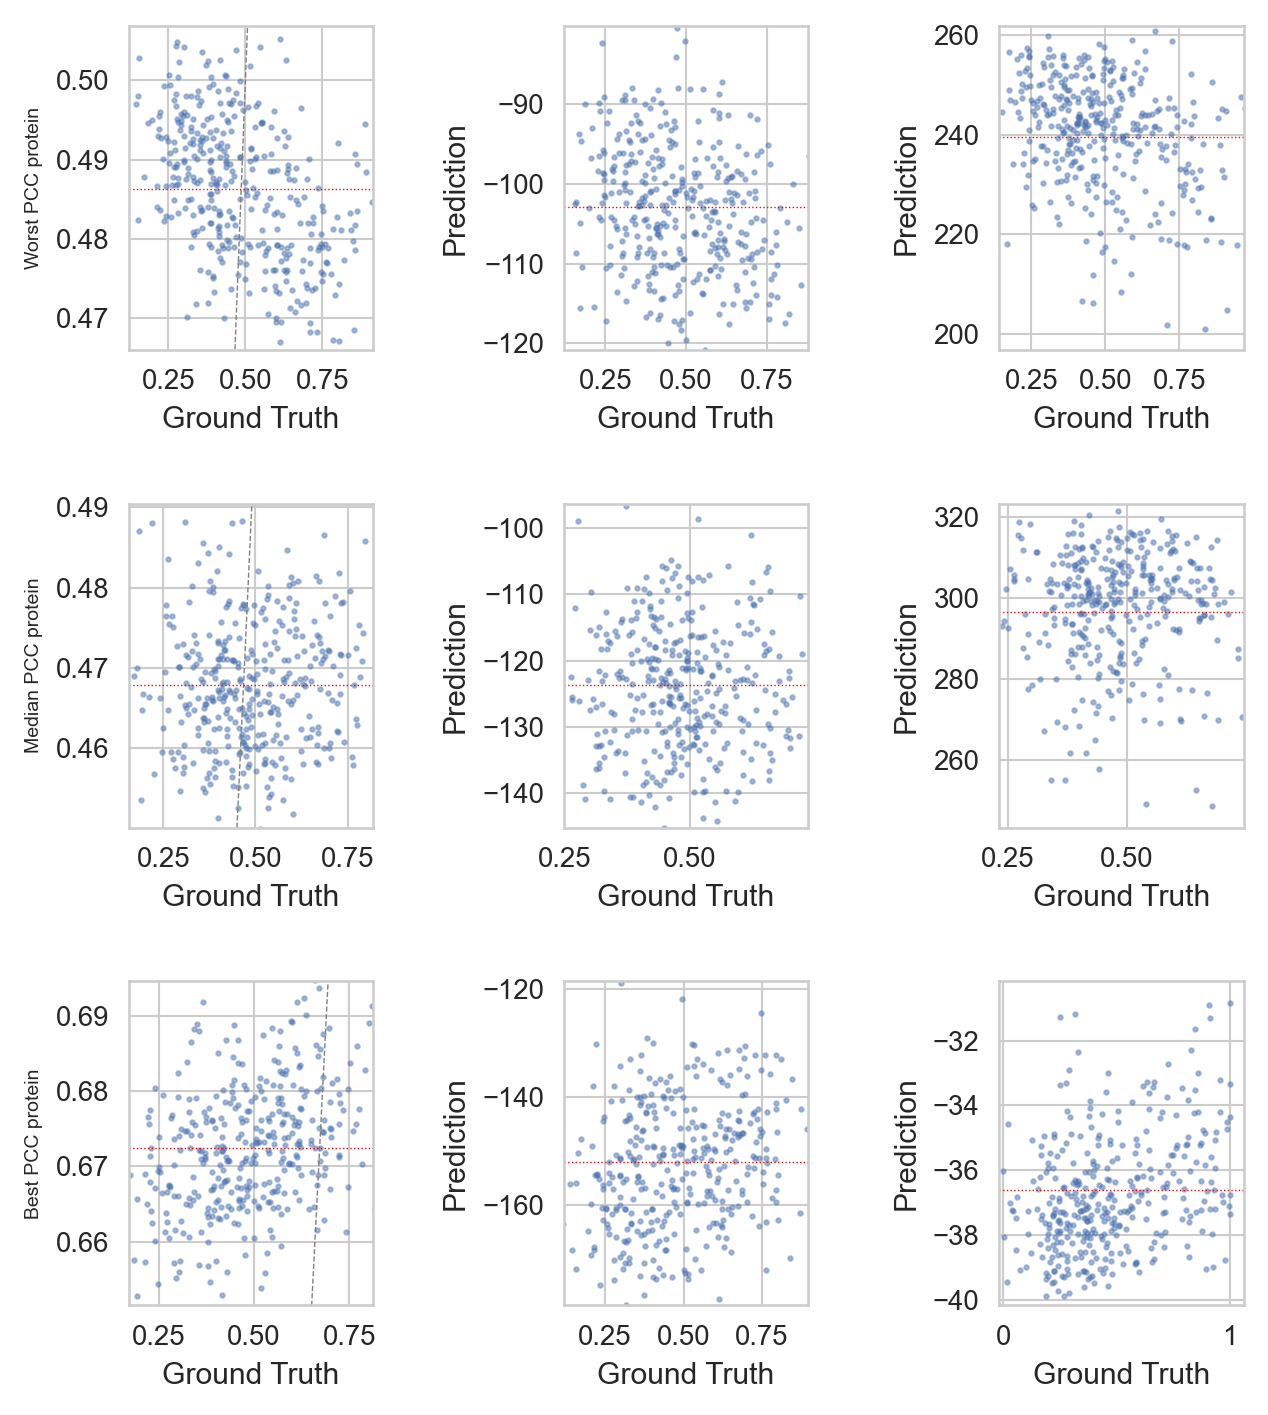

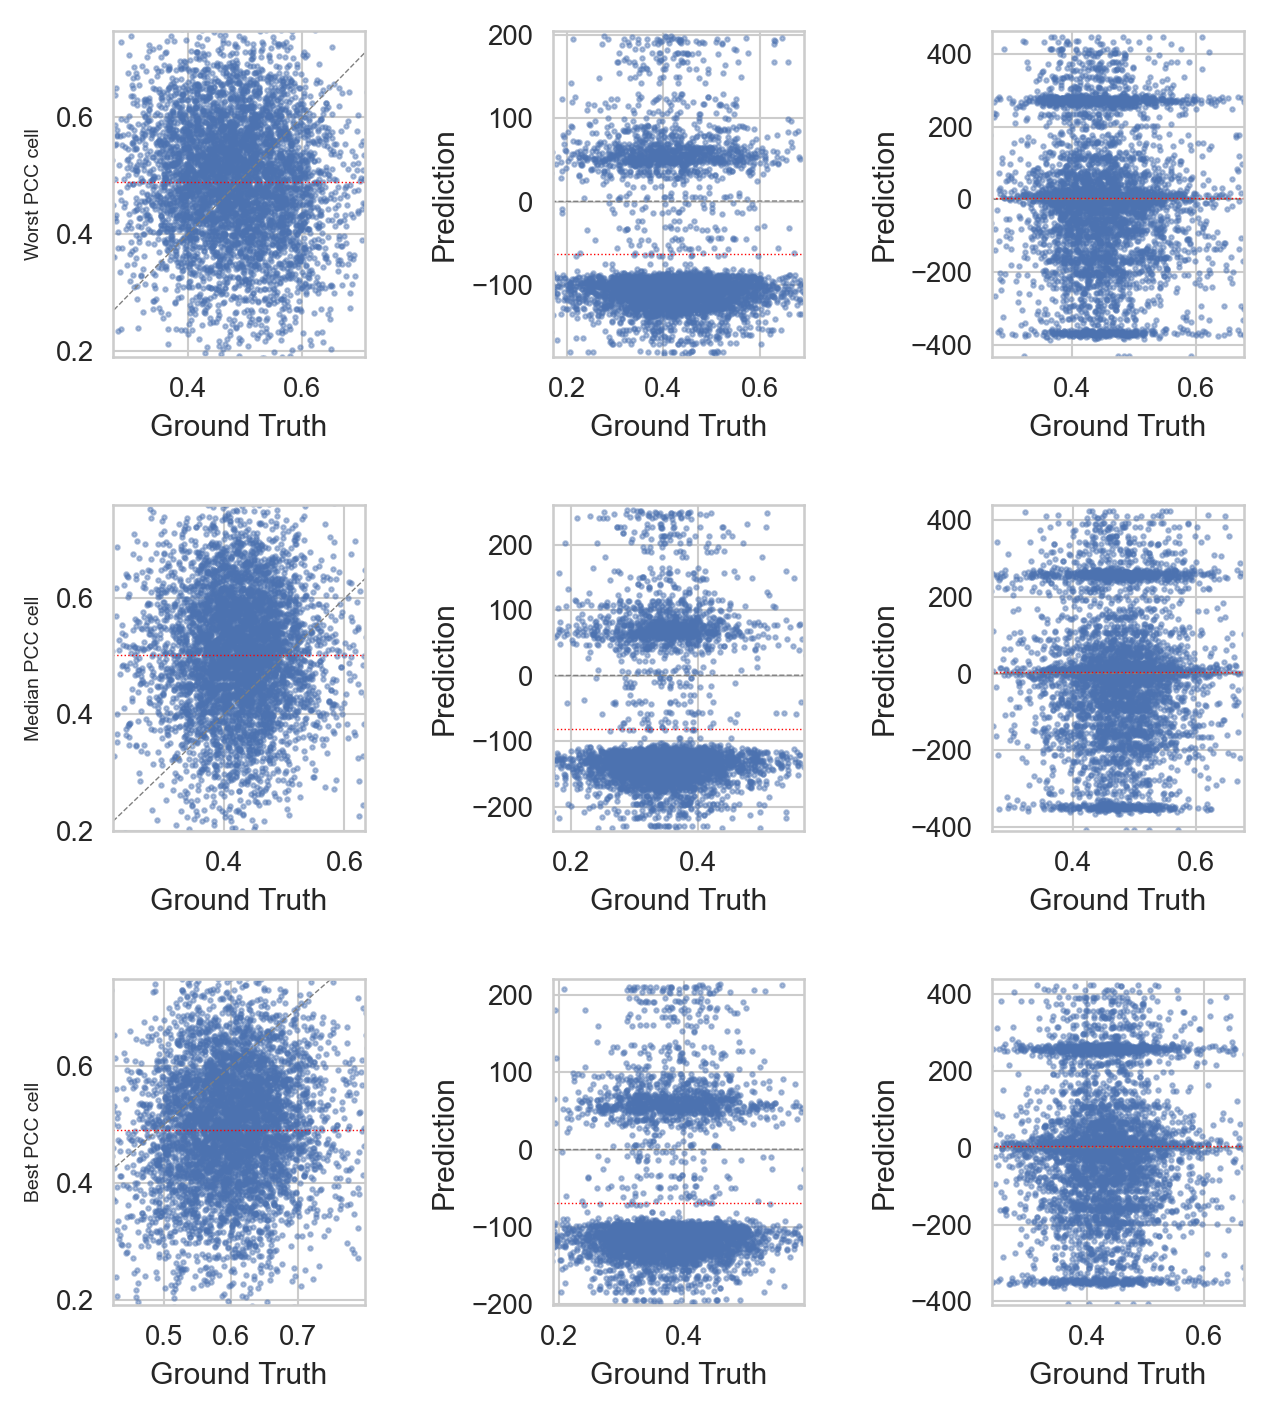

In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



# ---------- helpers ----------
def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def pcc_series_rows(gt, pred):
    pcc = []
    for i in gt.index:
        y = gt.loc[i].values.astype(float)
        p = pred.loc[i].values.astype(float)
        mask = ~(np.isnan(y) | np.isnan(p))
        if mask.sum() > 1 and np.std(y[mask]) > 0 and np.std(p[mask]) > 0:
            pcc.append(pearson_correlation(y[mask], p[mask]))
        else:
            pcc.append(np.nan)
    return pd.Series(pcc, index=gt.index)

def pcc_series_cols(gt, pred):
    pcc = []
    for c in gt.columns:
        y = gt[c].values.astype(float)
        p = pred[c].values.astype(float)
        mask = ~(np.isnan(y) | np.isnan(p))
        if mask.sum() > 1 and np.std(y[mask]) > 0 and np.std(p[mask]) > 0:
            pcc.append(pearson_correlation(y[mask], p[mask]))
        else:
            pcc.append(np.nan)
    return pd.Series(pcc, index=gt.columns)

def pick_worst_median_best(pcc_series):
    s = pcc_series.dropna().sort_values()
    worst = s.index[0]
    median = s.index[len(s)//2]
    best = s.index[-1]
    return worst, median, best

def set_axes_limits(ax, x, y, quantile=0.02, pad_frac=0.08):
    x_low, x_high = np.quantile(x, [quantile, 1-quantile])
    y_low, y_high = np.quantile(y, [quantile, 1-quantile])
    xr = x_high - x_low if x_high > x_low else 1.0
    yr = y_high - y_low if y_high > y_low else 1.0
    ax.set_xlim(x_low - pad_frac*xr, x_high + pad_frac*xr)
    ax.set_ylim(y_low - pad_frac*yr, y_high + pad_frac*yr)

def scatter_panel(ax, x, y, title, pcc):
    ax.scatter(x, y, s=10, alpha=0.45)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]),
            max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, "--", color="gray", linewidth=1)
    ax.axhline(np.mean(y), color="red", linestyle=":", linewidth=1)
    _remember_axes_name(ax, f"{title}\nPCC={pcc:.3f}")
    ax.set_xlabel("Ground Truth")
    ax.set_ylabel("Prediction")

# ---------- data prep ----------
pred_df_10k = align_to_gt(GT_scaled, pred_df_10k)
pred_df_160k = align_to_gt(GT_scaled, pred_df_160k)
pred_df_2m = align_to_gt(GT_scaled, pred_df_2m)

models = {
    "scTranslator 10K": pred_df_10k,
    "scTranslator 160K": pred_df_160k,
    "scTranslator 2M": pred_df_2m,
}

# ---------- PER-PROTEIN ----------
fig, axes = plt.subplots(3, 3, figsize=readable_figsize((12, 12)))
_remember_figure_name(fig, "Zero-Shot: Per-Protein View\nGround Truth vs Predictions (across 369 cells)")

row_labels = ["Worst PCC protein", "Median PCC protein", "Best PCC protein"]

for col_idx, (model_name, pred) in enumerate(models.items()):
    pcc_protein = pcc_series_cols(GT_scaled, pred)
    worst, median, best = pick_worst_median_best(pcc_protein)
    proteins = [worst, median, best]

    for row_idx, protein in enumerate(proteins):
        ax = axes[row_idx, col_idx]
        x = GT_scaled[protein].values.astype(float)
        y = pred[protein].values.astype(float)
        mask = ~(np.isnan(x) | np.isnan(y))
        x = x[mask]; y = y[mask]
        pcc = pearson_correlation(x, y) if len(x) > 1 else np.nan

        set_axes_limits(ax, x, y, quantile=0.02, pad_frac=0.08)
        label = f"{model_name}\n{row_labels[row_idx]}: {protein}"
        scatter_panel(ax, x, y, label, pcc)

        if col_idx == 0:
            ax.set_ylabel(row_labels[row_idx], fontsize=13.0)

plt.tight_layout(rect=[0, 0, 1, 0.95])
show_readable_figures()

# ---------- PER-CELL ----------
fig, axes = plt.subplots(3, 3, figsize=readable_figsize((12, 12)))
_remember_figure_name(fig, "Zero-Shot: Per-Cell View\nGround Truth vs Predictions (across 5112 proteins)")

row_labels = ["Worst PCC cell", "Median PCC cell", "Best PCC cell"]

for col_idx, (model_name, pred) in enumerate(models.items()):
    pcc_cell = pcc_series_rows(GT_scaled, pred)
    worst, median, best = pick_worst_median_best(pcc_cell)
    cells = [worst, median, best]

    for row_idx, cell in enumerate(cells):
        ax = axes[row_idx, col_idx]
        x = GT_scaled.loc[cell].values.astype(float)
        y = pred.loc[cell].values.astype(float)
        mask = ~(np.isnan(x) | np.isnan(y))
        x = x[mask]; y = y[mask]
        pcc = pearson_correlation(x, y) if len(x) > 1 else np.nan

        set_axes_limits(ax, x, y, quantile=0.02, pad_frac=0.08)
        label = f"{model_name}\n{row_labels[row_idx]}: {cell}"
        scatter_panel(ax, x, y, label, pcc)

        if col_idx == 0:
            ax.set_ylabel(row_labels[row_idx], fontsize=13.0)

plt.tight_layout(rect=[0, 0, 1, 0.95])
show_readable_figures()

Below is the same analysis for ElasticNet

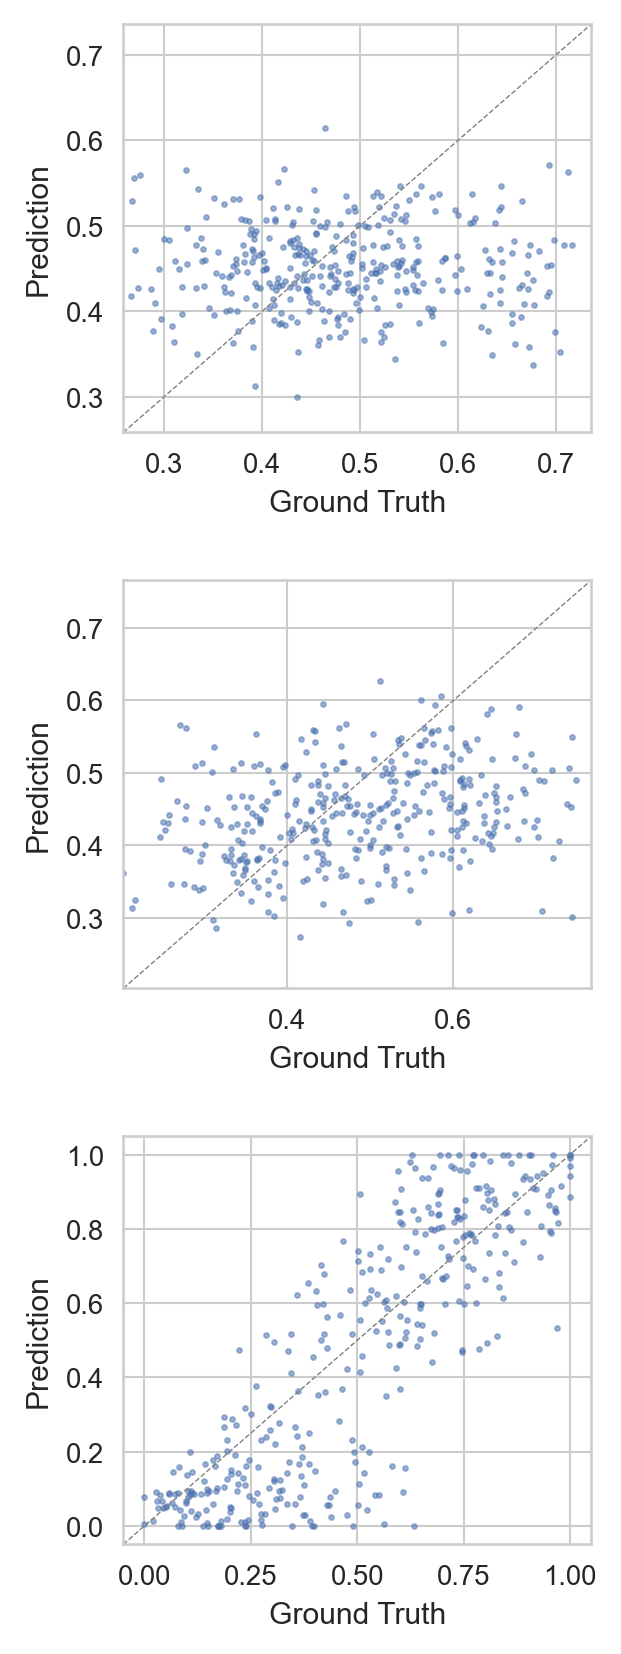

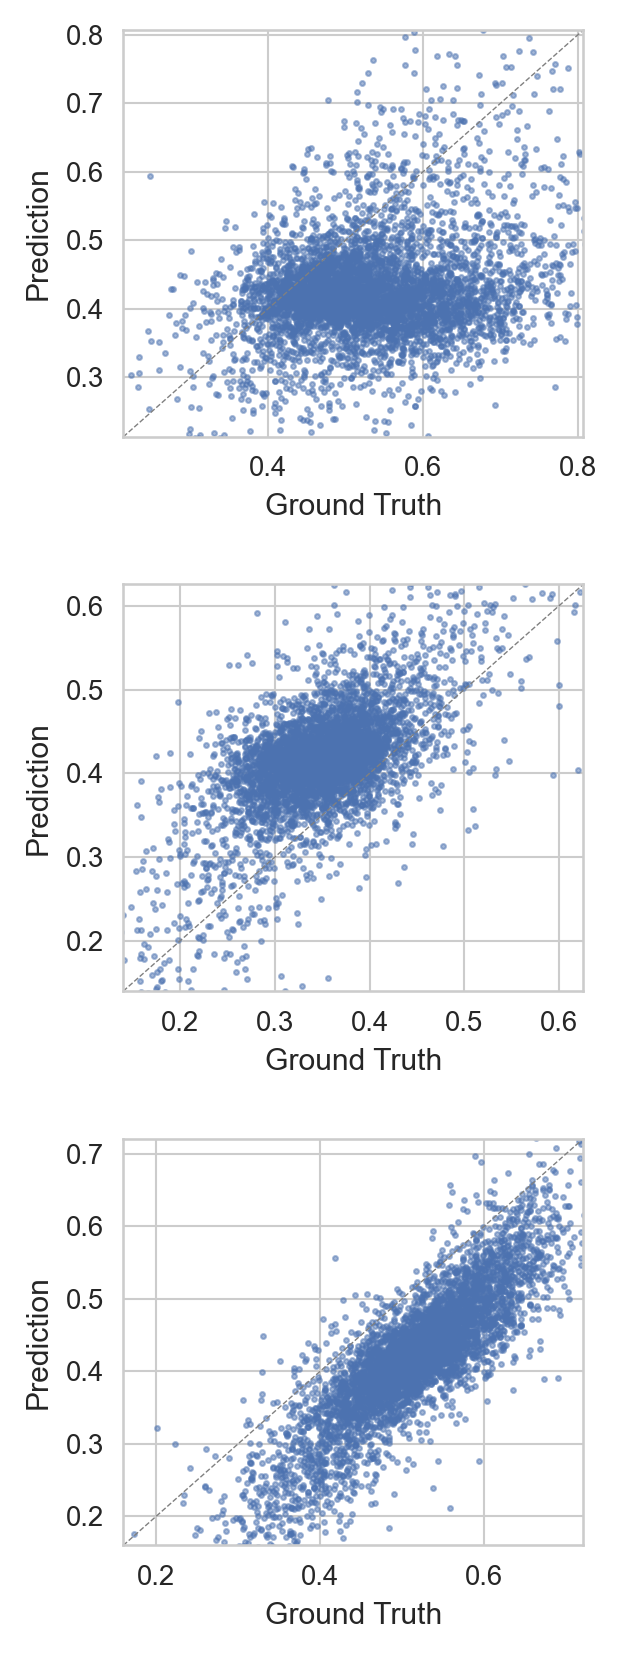

In [30]:

# ---------- align rows/cols ----------
pred_df_enet = PRED_scaled

# ---------- helpers ----------
def _robust_limits(x, y, pad=0.05):
    vals = np.concatenate([x, y])
    lo, hi = np.nanpercentile(vals, [1, 99])
    if lo == hi:
        lo, hi = np.nanmin(vals), np.nanmax(vals)
    if lo == hi:
        lo, hi = lo - 1, hi + 1
    span = hi - lo
    return lo - pad * span, hi + pad * span

def _pick_ranked_proteins(gt, pred):
    pccs = {}
    for prot in gt.columns:
        y_true = gt[prot].values.astype(float)
        y_pred = pred[prot].values.astype(float)
        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        if mask.sum() > 1:
            pccs[prot] = pearson_correlation(y_true[mask], y_pred[mask])
    s = pd.Series(pccs).dropna().sort_values()
    worst = s.index[0]
    median = s.index[len(s) // 2]
    best = s.index[-1]
    return {"worst": worst, "median": median, "best": best}, s

def _pick_ranked_cells(gt, pred):
    pccs = {}
    for cell in gt.index:
        y_true = gt.loc[cell].values.astype(float)
        y_pred = pred.loc[cell].values.astype(float)
        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        if mask.sum() > 1:
            pccs[cell] = pearson_correlation(y_true[mask], y_pred[mask])
    s = pd.Series(pccs).dropna().sort_values()
    worst = s.index[0]
    median = s.index[len(s) // 2]
    best = s.index[-1]
    return {"worst": worst, "median": median, "best": best}, s

def _scatter_panel(ax, x, y, title, pcc):
    ax.scatter(x, y, s=12, alpha=0.5)
    lims = _robust_limits(x, y)
    ax.plot(lims, lims, "--", color="gray", linewidth=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    _remember_axes_name(ax, f"{title}\nPCC={pcc:.3f}")
    ax.set_xlabel("Ground Truth")
    ax.set_ylabel("Prediction")

# ---------- compute ranked items ----------
prot_ranked, prot_pccs = _pick_ranked_proteins(GT_scaled, pred_df_enet)
cell_ranked, cell_pccs = _pick_ranked_cells(GT_scaled, pred_df_enet)

# ---------- PER-PROTEIN scatter ----------
fig, axes = plt.subplots(3, 1, figsize=readable_figsize((6, 14)))
_remember_figure_name(fig, "ElasticNet: Per-Protein View\nGround Truth vs Predictions (across cells)")

for ax, label in zip(axes, ["worst", "median", "best"]):
    prot = prot_ranked[label]
    x = GT_scaled[prot].values.astype(float)
    y = pred_df_enet[prot].values.astype(float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]; y = y[mask]
    _scatter_panel(ax, x, y, f"{label.capitalize()} PCC Protein\n{prot}", prot_pccs[prot])

plt.tight_layout(rect=[0, 0, 1, 0.96])
show_readable_figures()

# ---------- PER-CELL scatter ----------
fig, axes = plt.subplots(3, 1, figsize=readable_figsize((6, 14)))
_remember_figure_name(fig, "ElasticNet: Per-Cell View\nGround Truth vs Predictions (across proteins)")

for ax, label in zip(axes, ["worst", "median", "best"]):
    cell = cell_ranked[label]
    x = GT_scaled.loc[cell].values.astype(float)
    y = pred_df_enet.loc[cell].values.astype(float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]; y = y[mask]
    _scatter_panel(ax, x, y, f"{label.capitalize()} PCC Cell\n{cell}", cell_pccs[cell])

plt.tight_layout(rect=[0, 0, 1, 0.96])
show_readable_figures()

Now let's look at the distributions of the predicted values of both scTranslator and ElasticNet to see how they differ focusing on the standard deviation and mean

Below is the analysis per cell. In the plot we depict the histogram of the standard deviation per cell of the predictions and as mentioned above quanitfy how it differs from the ground truth with the Variation Ratio metric. Plotted we have the histogram of the standard deviation per cell of the ground truth and then of the four models tested and the plots of the variation ratio of the four models.

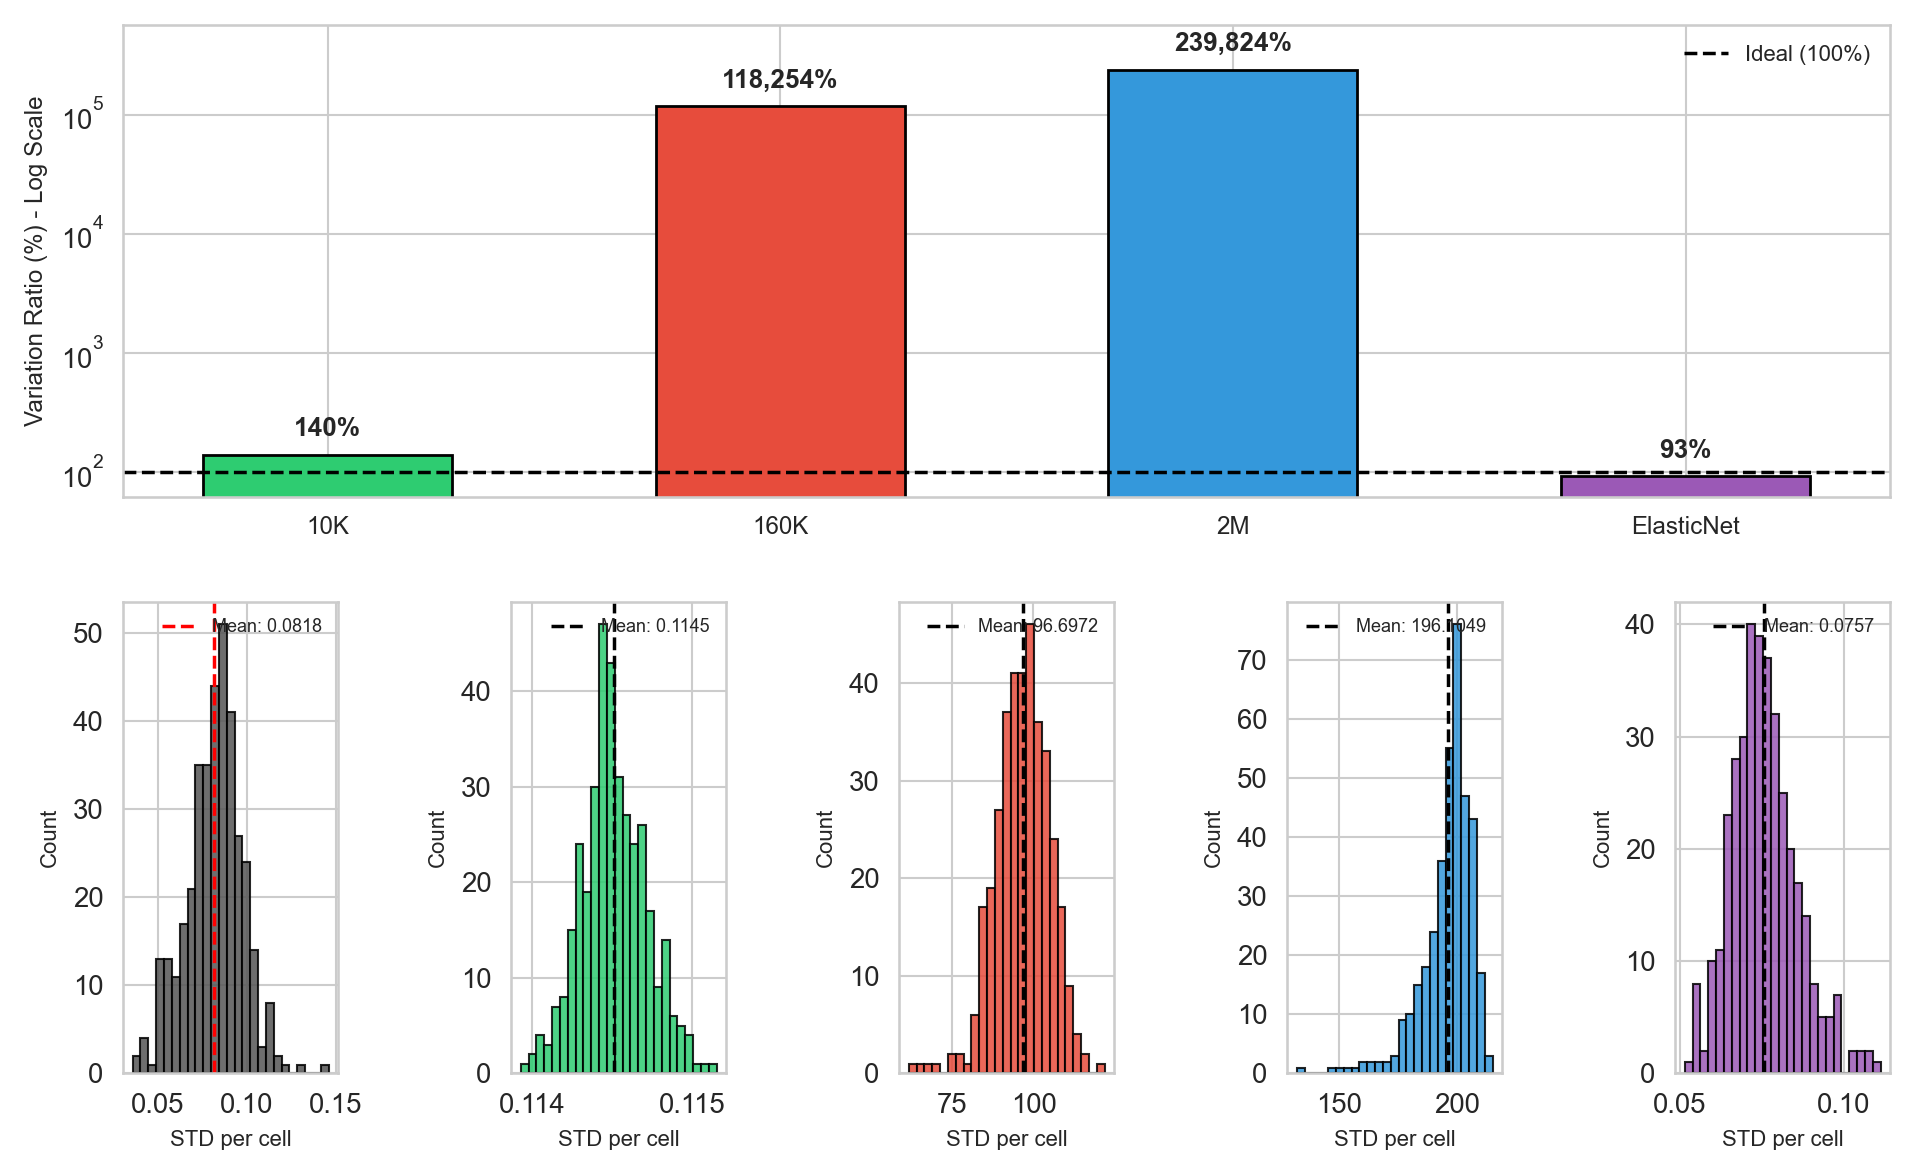

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


GT = GT_scaled
pred_10k = pred_df_10k
pred_160k = pred_df_160k
pred_2m = pred_df_2m
pred_enet = pred_df_enet  


ANALYSIS_MODE = "cell"  

# ----- helpers -----
def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def compute_stds(gt, pred, mode="cell"):
    if mode == "cell":
        true_stds = gt.std(axis=1, skipna=True)
        pred_stds = pred.std(axis=1, skipna=True)
    else:
        true_stds = gt.std(axis=0, skipna=True)
        pred_stds = pred.std(axis=0, skipna=True)
    return true_stds.values, pred_stds.values

def variation_ratio(true_stds, pred_stds):
    return (np.nanmean(pred_stds) / np.nanmean(true_stds)) * 100

# ----- align -----
pred_10k = align_to_gt(GT, pred_10k)
pred_160k = align_to_gt(GT, pred_160k)
pred_2m = align_to_gt(GT, pred_2m)
pred_enet = align_to_gt(GT, pred_enet)

models = {
    "10K": pred_10k,
    "160K": pred_160k,
    "2M": pred_2m,
    "ElasticNet": pred_enet,
}
colors = {
    "10K": "#2ECC71",
    "160K": "#E74C3C",
    "2M": "#3498DB",
    "ElasticNet": "#9B59B6",
}

# ----- compute -----
true_stds, _ = compute_stds(GT, GT, mode=ANALYSIS_MODE)
metrics = {}
for name, pred in models.items():
    _, pred_stds = compute_stds(GT, pred, mode=ANALYSIS_MODE)
    metrics[name] = {
        "pred_stds": pred_stds,
        "mean_var_ratio": variation_ratio(true_stds, pred_stds),
    }

# ----- plot -----
fig = plt.figure(figsize=readable_figsize((18, 10)))
gs = GridSpec(2, 5, figure=fig, height_ratios=[1, 1], hspace=0.49, wspace=0.42)

# Top row: bar chart across all 4 models
ax1 = fig.add_subplot(gs[0, :])
model_names = list(models.keys())
var_ratios = [metrics[m]["mean_var_ratio"] for m in model_names]
x_pos = np.arange(len(model_names))

bars = ax1.bar(
    x_pos, var_ratios,
    color=[colors[m] for m in model_names],
    edgecolor="black", linewidth=2, width=0.55
)

ax1.axhline(y=100, color="black", linestyle="--", linewidth=2.5, label="Ideal (100%)")
ax1.set_yscale("log")
ax1.set_ylabel("Variation Ratio (%) - Log Scale", fontsize=17.4)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(model_names, fontsize=17.4)

title_suffix = "per cell" if ANALYSIS_MODE == "cell" else "per protein"
_remember_axes_name(ax1, f"A. Variation Ratio\n= mean(Pred STD {title_suffix}) / mean(True STD {title_suffix}) × 100")
ax1.legend(fontsize=15.9, loc="upper right")

for bar, val in zip(bars, var_ratios):
    label = f"{val:,.0f}%" if val >= 1000 else f"{val:.0f}%"
    ax1.text(bar.get_x() + bar.get_width()/2, val * 1.3, label,
             ha="center", va="bottom", fontsize=18.8, fontweight="bold")

# Bottom row: 5 histograms (GT + 4 models)
# Ground truth
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(true_stds, bins=25, alpha=0.85, color="#555555", edgecolor="black")
ax2.axvline(np.nanmean(true_stds), color="red", linestyle="--", linewidth=2.5,
            label=f"Mean: {np.nanmean(true_stds):.4f}")
ax2.set_xlabel(f"STD {title_suffix}", fontsize=15.9)
ax2.set_ylabel("Count", fontsize=15.9)
_remember_axes_name(ax2, "B. Ground Truth")
ax2.legend(fontsize=13.0, loc="upper right")

# Each model
for i, name in enumerate(model_names, start=1):
    ax = fig.add_subplot(gs[1, i])
    pred_stds = metrics[name]["pred_stds"]
    ax.hist(pred_stds, bins=25, alpha=0.85, color=colors[name], edgecolor="black")
    ax.axvline(np.nanmean(pred_stds), color="black", linestyle="--", linewidth=2.5,
               label=f"Mean: {np.nanmean(pred_stds):.4f}")
    ax.set_xlabel(f"STD {title_suffix}", fontsize=15.9)
    ax.set_ylabel("Count", fontsize=15.9)
    _remember_axes_name(ax, f"{chr(66+i)}. {name} Model\nVar Ratio: {metrics[name]['mean_var_ratio']:,.0f}%")
    ax.legend(fontsize=13.0, loc="upper right")

_remember_figure_name(fig, f"Per-{title_suffix.capitalize()} Analysis: scTranslator + ElasticNet\n"
    f"Measuring variation {'within each cell' if ANALYSIS_MODE=='cell' else 'across cells'}")
show_readable_figures()

We then repeat the same analysis per protein

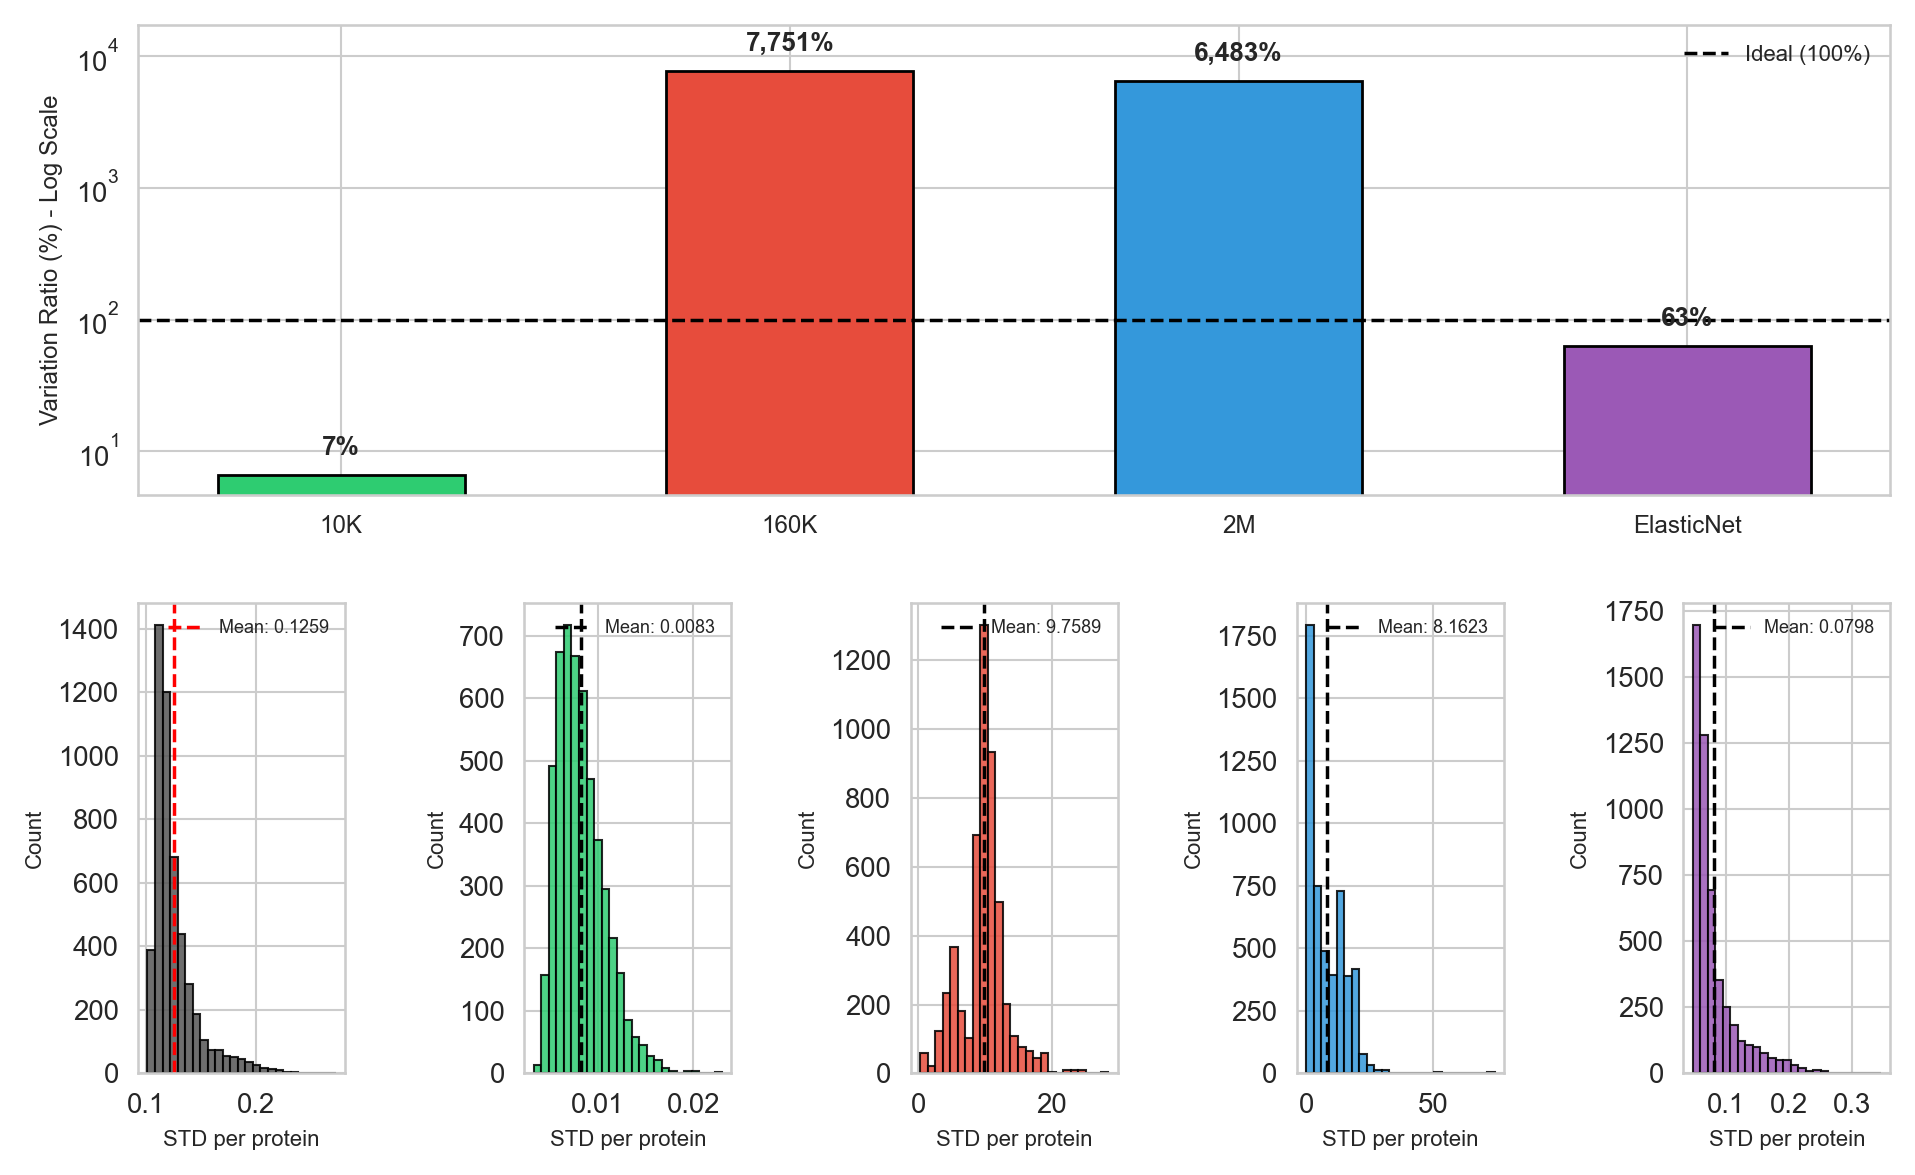

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


GT = GT_scaled
pred_10k = pred_df_10k
pred_160k = pred_df_160k
pred_2m = pred_df_2m
pred_enet = pred_df_enet  


ANALYSIS_MODE = "protein"  

# ----- helpers -----
def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def compute_stds(gt, pred, mode="cell"):
    if mode == "cell":
        true_stds = gt.std(axis=1, skipna=True)
        pred_stds = pred.std(axis=1, skipna=True)
    else:
        true_stds = gt.std(axis=0, skipna=True)
        pred_stds = pred.std(axis=0, skipna=True)
    return true_stds.values, pred_stds.values

def variation_ratio(true_stds, pred_stds):
    return (np.nanmean(pred_stds) / np.nanmean(true_stds)) * 100

# ----- align -----
pred_10k = align_to_gt(GT, pred_10k)
pred_160k = align_to_gt(GT, pred_160k)
pred_2m = align_to_gt(GT, pred_2m)
pred_enet = align_to_gt(GT, pred_enet)

models = {
    "10K": pred_10k,
    "160K": pred_160k,
    "2M": pred_2m,
    "ElasticNet": pred_enet,
}
colors = {
    "10K": "#2ECC71",
    "160K": "#E74C3C",
    "2M": "#3498DB",
    "ElasticNet": "#9B59B6",
}

# ----- compute -----
true_stds, _ = compute_stds(GT, GT, mode=ANALYSIS_MODE)
metrics = {}
for name, pred in models.items():
    _, pred_stds = compute_stds(GT, pred, mode=ANALYSIS_MODE)
    metrics[name] = {
        "pred_stds": pred_stds,
        "mean_var_ratio": variation_ratio(true_stds, pred_stds),
    }

# ----- plot -----
fig = plt.figure(figsize=readable_figsize((18, 10)))
gs = GridSpec(2, 5, figure=fig, height_ratios=[1, 1], hspace=0.49, wspace=0.42)

# Top row: bar chart across all 4 models
ax1 = fig.add_subplot(gs[0, :])
model_names = list(models.keys())
var_ratios = [metrics[m]["mean_var_ratio"] for m in model_names]
x_pos = np.arange(len(model_names))

bars = ax1.bar(
    x_pos, var_ratios,
    color=[colors[m] for m in model_names],
    edgecolor="black", linewidth=2, width=0.55
)

ax1.axhline(y=100, color="black", linestyle="--", linewidth=2.5, label="Ideal (100%)")
ax1.set_yscale("log")
ax1.set_ylabel("Variation Ratio (%) - Log Scale", fontsize=17.4)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(model_names, fontsize=17.4)

title_suffix = "per cell" if ANALYSIS_MODE == "cell" else "per protein"
_remember_axes_name(ax1, f"A. Variation Ratio\n= mean(Pred STD {title_suffix}) / mean(True STD {title_suffix}) × 100")
ax1.legend(fontsize=15.9, loc="upper right")

for bar, val in zip(bars, var_ratios):
    label = f"{val:,.0f}%" if val >= 1000 else f"{val:.0f}%"
    ax1.text(bar.get_x() + bar.get_width()/2, val * 1.3, label,
             ha="center", va="bottom", fontsize=18.8, fontweight="bold")

# Bottom row: 5 histograms (GT + 4 models)
# Ground truth
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(true_stds, bins=25, alpha=0.85, color="#555555", edgecolor="black")
ax2.axvline(np.nanmean(true_stds), color="red", linestyle="--", linewidth=2.5,
            label=f"Mean: {np.nanmean(true_stds):.4f}")
ax2.set_xlabel(f"STD {title_suffix}", fontsize=15.9)
ax2.set_ylabel("Count", fontsize=15.9)
_remember_axes_name(ax2, "B. Ground Truth")
ax2.legend(fontsize=13.0, loc="upper right")

# Each model
for i, name in enumerate(model_names, start=1):
    ax = fig.add_subplot(gs[1, i])
    pred_stds = metrics[name]["pred_stds"]
    ax.hist(pred_stds, bins=25, alpha=0.85, color=colors[name], edgecolor="black")
    ax.axvline(np.nanmean(pred_stds), color="black", linestyle="--", linewidth=2.5,
               label=f"Mean: {np.nanmean(pred_stds):.4f}")
    ax.set_xlabel(f"STD {title_suffix}", fontsize=15.9)
    ax.set_ylabel("Count", fontsize=15.9)
    _remember_axes_name(ax, f"{chr(66+i)}. {name} Model\nVar Ratio: {metrics[name]['mean_var_ratio']:,.0f}%")
    ax.legend(fontsize=13.0, loc="upper right")

_remember_figure_name(fig, f"Per-{title_suffix.capitalize()} Analysis: scTranslator + ElasticNet\n"
    f"Measuring variation {'within each cell' if ANALYSIS_MODE=='cell' else 'across cells'}")
show_readable_figures()

We now turn to looking at the mean of the predictions of the models per cell and per protein. We plot the histogram of the mean of the cells and protein predictions versus that of the ground truth

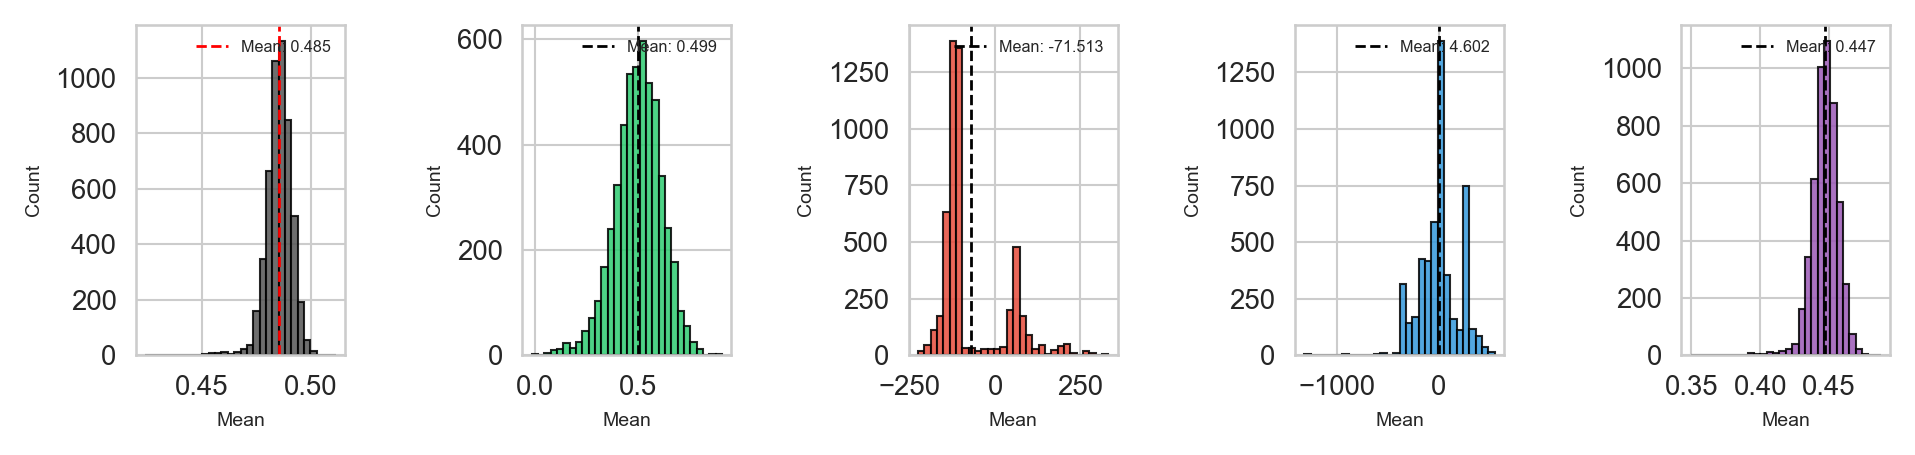

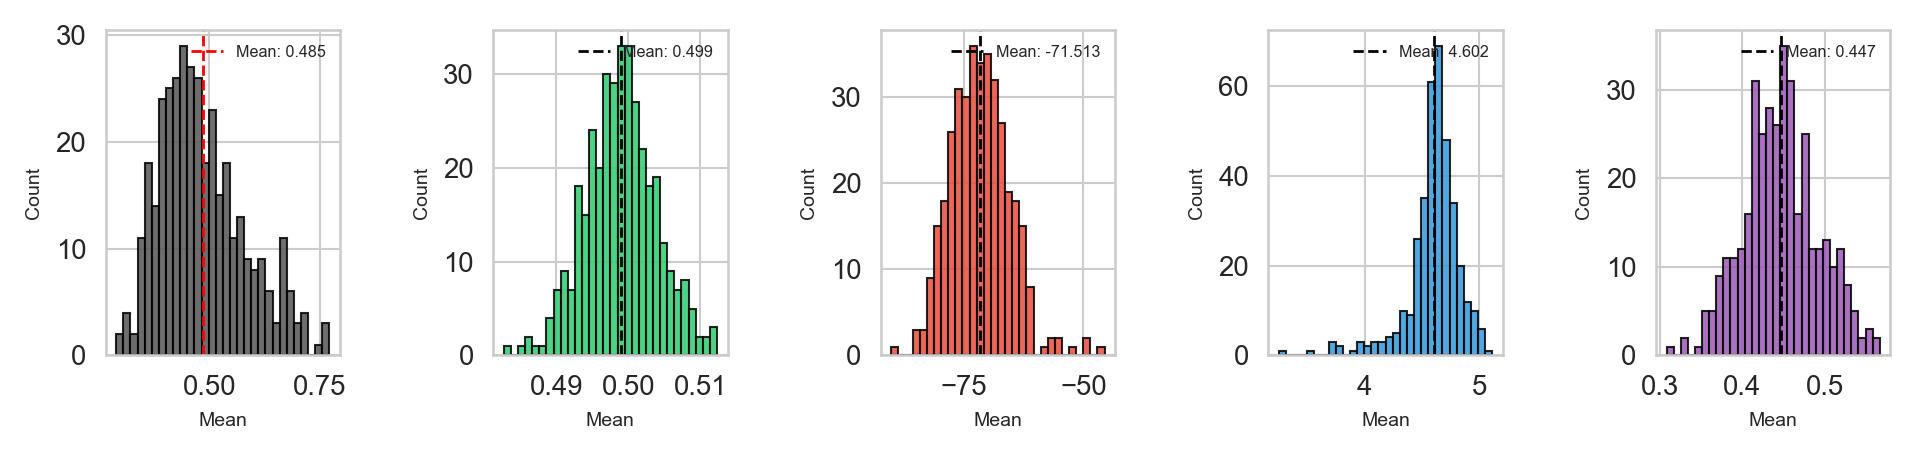

In [33]:

import numpy as np
import matplotlib.pyplot as plt

GT = GT_scaled
pred_10k = pred_df_10k
pred_160k = pred_df_160k
pred_2m = pred_df_2m
pred_enet = pred_df_enet  


def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def mean_per_cell(df):
    return df.mean(axis=1, skipna=True).values

def mean_per_protein(df):
    return df.mean(axis=0, skipna=True).values

# ---------- align ----------
pred_10k = align_to_gt(GT, pred_10k)
pred_160k = align_to_gt(GT, pred_160k)
pred_2m = align_to_gt(GT, pred_2m)
pred_enet = align_to_gt(GT, pred_enet)

models = {
    "GT": GT,
    "10K": pred_10k,
    "160K": pred_160k,
    "2M": pred_2m,
    "ElasticNet": pred_enet,
}
colors = {
    "GT": "#555555",
    "10K": "#2ECC71",
    "160K": "#E74C3C",
    "2M": "#3498DB",
    "ElasticNet": "#9B59B6",
}

def plot_mean_histograms(mode="protein", bins=30):
    fig, axes = plt.subplots(1, 5, figsize=readable_figsize((18, 4)))
    title_suffix = "Per-Protein Mean" if mode == "protein" else "Per-Sample Mean"

    for ax, (name, df) in zip(axes, models.items()):
        vals = mean_per_protein(df) if mode == "protein" else mean_per_cell(df)
        ax.hist(vals, bins=bins, alpha=0.85, color=colors[name], edgecolor="black")
        ax.axvline(np.nanmean(vals), color="black" if name != "GT" else "red",
                   linestyle="--", linewidth=2, label=f"Mean: {np.nanmean(vals):.3f}")
        _remember_axes_name(ax, f"{name}\n{title_suffix}")
        ax.set_xlabel("Mean", fontsize=13.0)
        ax.set_ylabel("Count", fontsize=13.0)
        ax.legend(fontsize=11.6, loc="upper right")

    _remember_figure_name(fig, f"{title_suffix}: Distribution of Mean Expression")
    plt.tight_layout()
    show_readable_figures()


plot_mean_histograms(mode="protein", bins=30)
plot_mean_histograms(mode="cell", bins=30)

Additionally we now rank the best proteins according to the MSE not only to the pearson to see which proteins were able to be predicted the best based on the MSE

In [34]:

def compute_per_protein_mse(ground_truth, predictions):
    """
    Compute MSE for each protein across all samples.
    Returns a DataFrame with protein names and their MSE values.
    """
    per_protein_mse = {"protein": [], "mse": []}
    proteins = predictions.columns.tolist()
    
    for protein in proteins:
        y_true = ground_truth[protein].values.astype(float)
        y_pred = predictions[protein].values.astype(float)
        
        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]
        
        if len(y_true_clean) > 1:
            per_protein_mse["protein"].append(protein)
            per_protein_mse["mse"].append(mse(y_true_clean, y_pred_clean))
    
    return pd.DataFrame(per_protein_mse).sort_values("mse", ascending=True)

# Compute per-protein MSE for each model
mse_enet = compute_per_protein_mse(GT_scaled, PRED_scaled)
mse_10k = compute_per_protein_mse(GT_scaled, pred_df_10k)
mse_160k = compute_per_protein_mse(GT_scaled, pred_df_160k)
mse_2m = compute_per_protein_mse(GT_scaled, pred_df_2m)

# Get top 10 (lowest MSE) and bottom 10 (highest MSE) for each model
top10_mse_enet = mse_enet.head(10)
bottom10_mse_enet = mse_enet.tail(10)

top10_mse_10k = mse_10k.head(10)
bottom10_mse_10k = mse_10k.tail(10)

top10_mse_160k = mse_160k.head(10)
bottom10_mse_160k = mse_160k.tail(10)

top10_mse_2m = mse_2m.head(10)
bottom10_mse_2m = mse_2m.tail(10)

print("Per-protein MSE computed for all models:")
print(f"  ElasticNet: {len(mse_enet)} proteins")
print(f"  scTranslator 10K: {len(mse_10k)} proteins")
print(f"  scTranslator 160K: {len(mse_160k)} proteins")
print(f"  scTranslator 2M: {len(mse_2m)} proteins")

Per-protein MSE computed for all models:
  ElasticNet: 5113 proteins
  scTranslator 10K: 5112 proteins
  scTranslator 160K: 5112 proteins
  scTranslator 2M: 5112 proteins


Saved: protein_mse_ranking_comparison.png


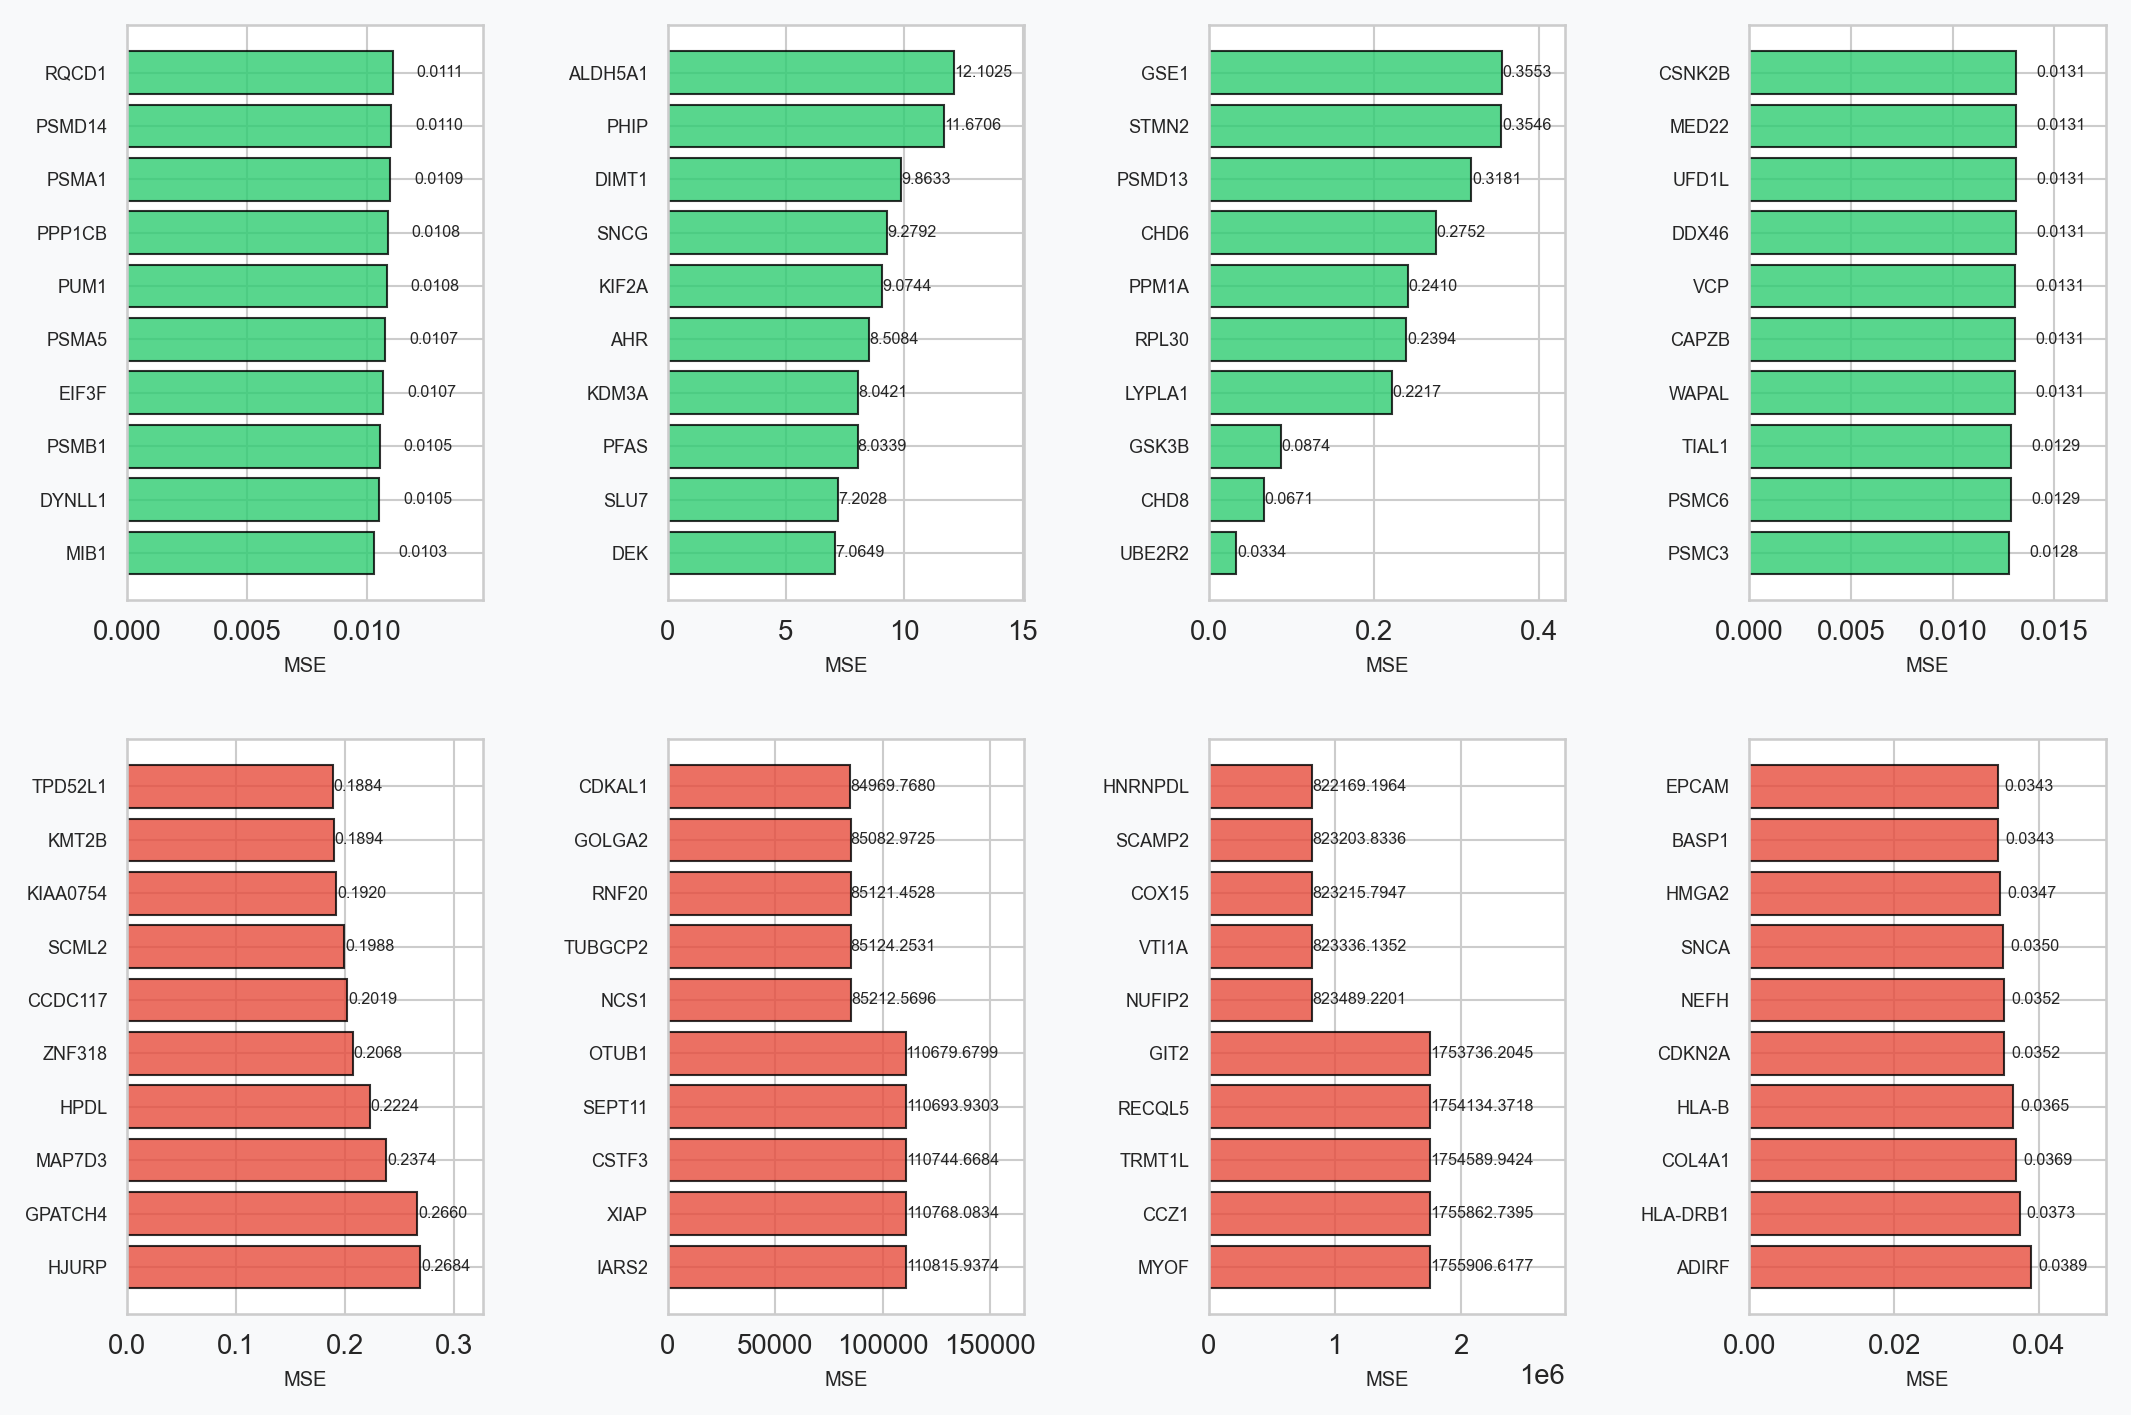


SUMMARY: Top 10 Proteins by MSE (Best Predictions)


,scT 10K,scT 10K MSE,scT 160K,scT 160K MSE,scT 2M,scT 2M MSE,ElasticNet,ENet MSE
0,MIB1,0.010292,DEK,7.064880,UBE2R2,0.033373,PSMC3,0.012790
1,DYNLL1,0.010496,SLU7,7.202769,CHD8,0.067134,PSMC6,0.012856
2,PSMB1,0.010520,PFAS,8.033880,GSK3B,0.087389,TIAL1,0.012874
3,EIF3F,0.010667,KDM3A,8.042097,LYPLA1,0.221725,WAPAL,0.013066
4,PSMA5,0.010741,AHR,8.508410,RPL30,0.239411,CAPZB,0.013068
5,PUM1,0.010804,KIF2A,9.074362,PPM1A,0.240990,VCP,0.013088
6,PPP1CB,0.010849,SNCG,9.279186,CHD6,0.275204,DDX46,0.013105
7,PSMA1,0.010950,DIMT1,9.863266,PSMD13,0.318140,UFD1L,0.013114
8,PSMD14,0.011009,PHIP,11.670559,STMN2,0.354647,MED22,0.013124
9,RQCD1,0.011058,ALDH5A1,12.102450,GSE1,0.355346,CSNK2B,0.013135



SUMMARY: Bottom 10 Proteins by MSE (Worst Predictions)


,scT 10K,scT 10K MSE,scT 160K,scT 160K MSE,scT 2M,scT 2M MSE,ElasticNet,ENet MSE
0,TPD52L1,0.188410,CDKAL1,84969.768004,HNRNPDL,8.221692e+05,EPCAM,0.034291
1,KMT2B,0.189375,GOLGA2,85082.972495,SCAMP2,8.232038e+05,BASP1,0.034336
2,KIAA0754,0.192027,RNF20,85121.452834,COX15,8.232158e+05,HMGA2,0.034662
3,SCML2,0.198772,TUBGCP2,85124.253079,VTI1A,8.233361e+05,SNCA,0.035032
4,CCDC117,0.201942,NCS1,85212.569603,NUFIP2,8.234892e+05,NEFH,0.035172
5,ZNF318,0.206816,OTUB1,110679.679880,GIT2,1.753736e+06,CDKN2A,0.035220
6,HPDL,0.222414,SEPT11,110693.930316,RECQL5,1.754134e+06,HLA-B,0.036475
7,MAP7D3,0.237379,CSTF3,110744.668358,TRMT1L,1.754590e+06,COL4A1,0.036853
8,GPATCH4,0.266039,XIAP,110768.083432,CCZ1,1.755863e+06,HLA-DRB1,0.037332
9,HJURP,0.268386,IARS2,110815.937449,MYOF,1.755907e+06,ADIRF,0.038880


In [35]:

def plot_protein_mse_comparison(model_data, title, out_path=None):
    """
    Plot top 10 (best) and bottom 10 (worst) proteins by MSE for multiple models.
    
    Parameters:
    -----------
    model_data : dict
        Dictionary with model names as keys and tuples of (top10_df, bottom10_df) as values
    title : str
        Plot title
    out_path : Path or str, optional
        Path to save the figure
    """
    n_models = len(model_data)
    fig, axes = plt.subplots(2, n_models, figsize=readable_figsize((5 * n_models, 12)))
    fig.patch.set_facecolor("#F8F9FA")
    
    # Consistent colors: green for best (top 10), red for worst (bottom 10)
    top_color = "#2ECC71"    # Green for best performing
    bottom_color = "#E74C3C"  # Red for worst performing
    
    for col_idx, (model_name, (top10, bottom10)) in enumerate(model_data.items()):
        # Top 10 (lowest MSE - best performing) - GREEN
        ax_top = axes[0, col_idx] if n_models > 1 else axes[0]
        top10_sorted = top10.sort_values("mse", ascending=False)  # Reverse for horizontal bar
        y_pos = np.arange(len(top10_sorted))
        ax_top.barh(y_pos, top10_sorted["mse"].values, color=top_color, edgecolor="black", alpha=0.8)
        ax_top.set_yticks(y_pos)
        ax_top.set_yticklabels(top10_sorted["protein"].values, fontsize=13.0)
        ax_top.set_xlabel("MSE", fontsize=14.5)
        _remember_axes_name(ax_top, f"{model_name}\nTop 10 (Lowest MSE)")
        ax_top.invert_yaxis()
        
        # Add value labels
        for i, (idx, row) in enumerate(top10_sorted.iterrows()):
            ax_top.text(row["mse"] + 0.001, i, f'{row["mse"]:.4f}', va='center', fontsize=11.6)
        
        # Bottom 10 (highest MSE - worst performing) - RED
        ax_bottom = axes[1, col_idx] if n_models > 1 else axes[1]
        bottom10_sorted = bottom10.sort_values("mse", ascending=True)  # Reverse for horizontal bar
        y_pos = np.arange(len(bottom10_sorted))
        ax_bottom.barh(y_pos, bottom10_sorted["mse"].values, color=bottom_color, edgecolor="black", alpha=0.8)
        ax_bottom.set_yticks(y_pos)
        ax_bottom.set_yticklabels(bottom10_sorted["protein"].values, fontsize=13.0)
        ax_bottom.set_xlabel("MSE", fontsize=14.5)
        _remember_axes_name(ax_bottom, f"{model_name}\nBottom 10 (Highest MSE)")
        ax_bottom.invert_yaxis()
        
        # Add value labels
        for i, (idx, row) in enumerate(bottom10_sorted.iterrows()):
            ax_bottom.text(row["mse"] + 0.001, i, f'{row["mse"]:.4f}', va='center', fontsize=11.6)
    
    _remember_figure_name(fig, title)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    if out_path:
        save_readable_current_figure(out_path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")
    
    show_readable_figures()

# Prepare data for plotting
model_data = {
    "scTranslator 10K": (top10_mse_10k, bottom10_mse_10k),
    "scTranslator 160K": (top10_mse_160k, bottom10_mse_160k),
    "scTranslator 2M": (top10_mse_2m, bottom10_mse_2m),
    "ElasticNet": (top10_mse_enet, bottom10_mse_enet),
}

# Plot the comparison
plot_protein_mse_comparison(
    model_data,
    title="Protein Ranking by MSE: Top 10 (Best) and Bottom 10 (Worst) Across Models",
    out_path=Path("protein_mse_ranking_comparison.png")
)

# Display summary tables
print("\n" + "="*80)
print("SUMMARY: Top 10 Proteins by MSE (Best Predictions)")
print("="*80)
summary_top = pd.DataFrame({
    "scT 10K": top10_mse_10k["protein"].values,
    "scT 10K MSE": top10_mse_10k["mse"].values,
    "scT 160K": top10_mse_160k["protein"].values,
    "scT 160K MSE": top10_mse_160k["mse"].values,
    "scT 2M": top10_mse_2m["protein"].values,
    "scT 2M MSE": top10_mse_2m["mse"].values,
    "ElasticNet": top10_mse_enet["protein"].values,
    "ENet MSE": top10_mse_enet["mse"].values,
})
display(summary_top)

print("\n" + "="*80)
print("SUMMARY: Bottom 10 Proteins by MSE (Worst Predictions)")
print("="*80)
summary_bottom = pd.DataFrame({
    "scT 10K": bottom10_mse_10k["protein"].values,
    "scT 10K MSE": bottom10_mse_10k["mse"].values,
    "scT 160K": bottom10_mse_160k["protein"].values,
    "scT 160K MSE": bottom10_mse_160k["mse"].values,
    "scT 2M": bottom10_mse_2m["protein"].values,
    "scT 2M MSE": bottom10_mse_2m["mse"].values,
    "ElasticNet": bottom10_mse_enet["protein"].values,
    "ENet MSE": bottom10_mse_enet["mse"].values,
})
display(summary_bottom)

## Complete all model comparison 

xgb import

In [36]:
import pathlib
import pandas as pd
import numpy as np

try:
    import tables
    tables.file._open_files.close_all()
except Exception:
    pass

p = pathlib.Path("res_data/xgb_all_results.h5")
print("exists:", p.exists())
if p.exists():
    print("size:", p.stat().st_size, "bytes")

h5_file = str(p)
eps = 1e-8

with pd.HDFStore(h5_file, mode="r") as store:
    keys = store.keys()
    print("keys:", keys)
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)

print("Combined DataFrame shape:", combined_df.shape)
display(combined_df.head())
display(combined_df.tail())
print("columns:", combined_df.columns.tolist())

exists: True
size: 94805704 bytes
keys: ['/data']
Combined DataFrame shape: (1886697, 4)


,protein,LOO sample,true,predicted
0,A2M,MDAMB468_BREAST,-0.345562,-0.691980
1,A2M,SH4_SKIN,1.642186,0.469850
2,A2M,AU565_BREAST,-1.129114,-0.811306
3,A2M,KMRC1_KIDNEY,1.493333,0.888209
4,A2M,CAL51_BREAST,0.274652,0.562785


,protein,LOO sample,true,predicted
1886692,ZZZ3,FADU_UPPER_AERODIGESTIVE_TRACT,-0.005547,0.430002
1886693,ZZZ3,KP4_PANCREAS,1.008579,0.178883
1886694,ZZZ3,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-0.157715,0.212874
1886695,ZZZ3,OVCAR8_OVARY,0.196810,-0.015748
1886696,ZZZ3,THP1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.288932,-0.154777


columns: ['protein', 'LOO sample', 'true', 'predicted']


### XGBoost + ElasticNet + scTranslator comparison

This section does two comparisons on the exact shared subset of cells and proteins:

1. **XGBoost vs ElasticNet**, shown for:
   - **RAW**
   - **SCALED**

2. The **best baseline by protein-wise mean PCC** is selected separately for:
   - **RAW**
   - **SCALED**

That winner is then compared against **scTranslator 10K** in the same space.

For scTranslator 10K:
- the stored predictions are treated as **scaled**
- the **raw** version is obtained by inverse min-max transform using the common-subset `GT_raw` protein-wise min/max

Common comparison subset: 369 cells x 4079 proteins
Mean absolute difference between GT_raw and XGB true on common subset: 0.000000
Saved: outputs\xgb_vs_enet_raw_scaled.png


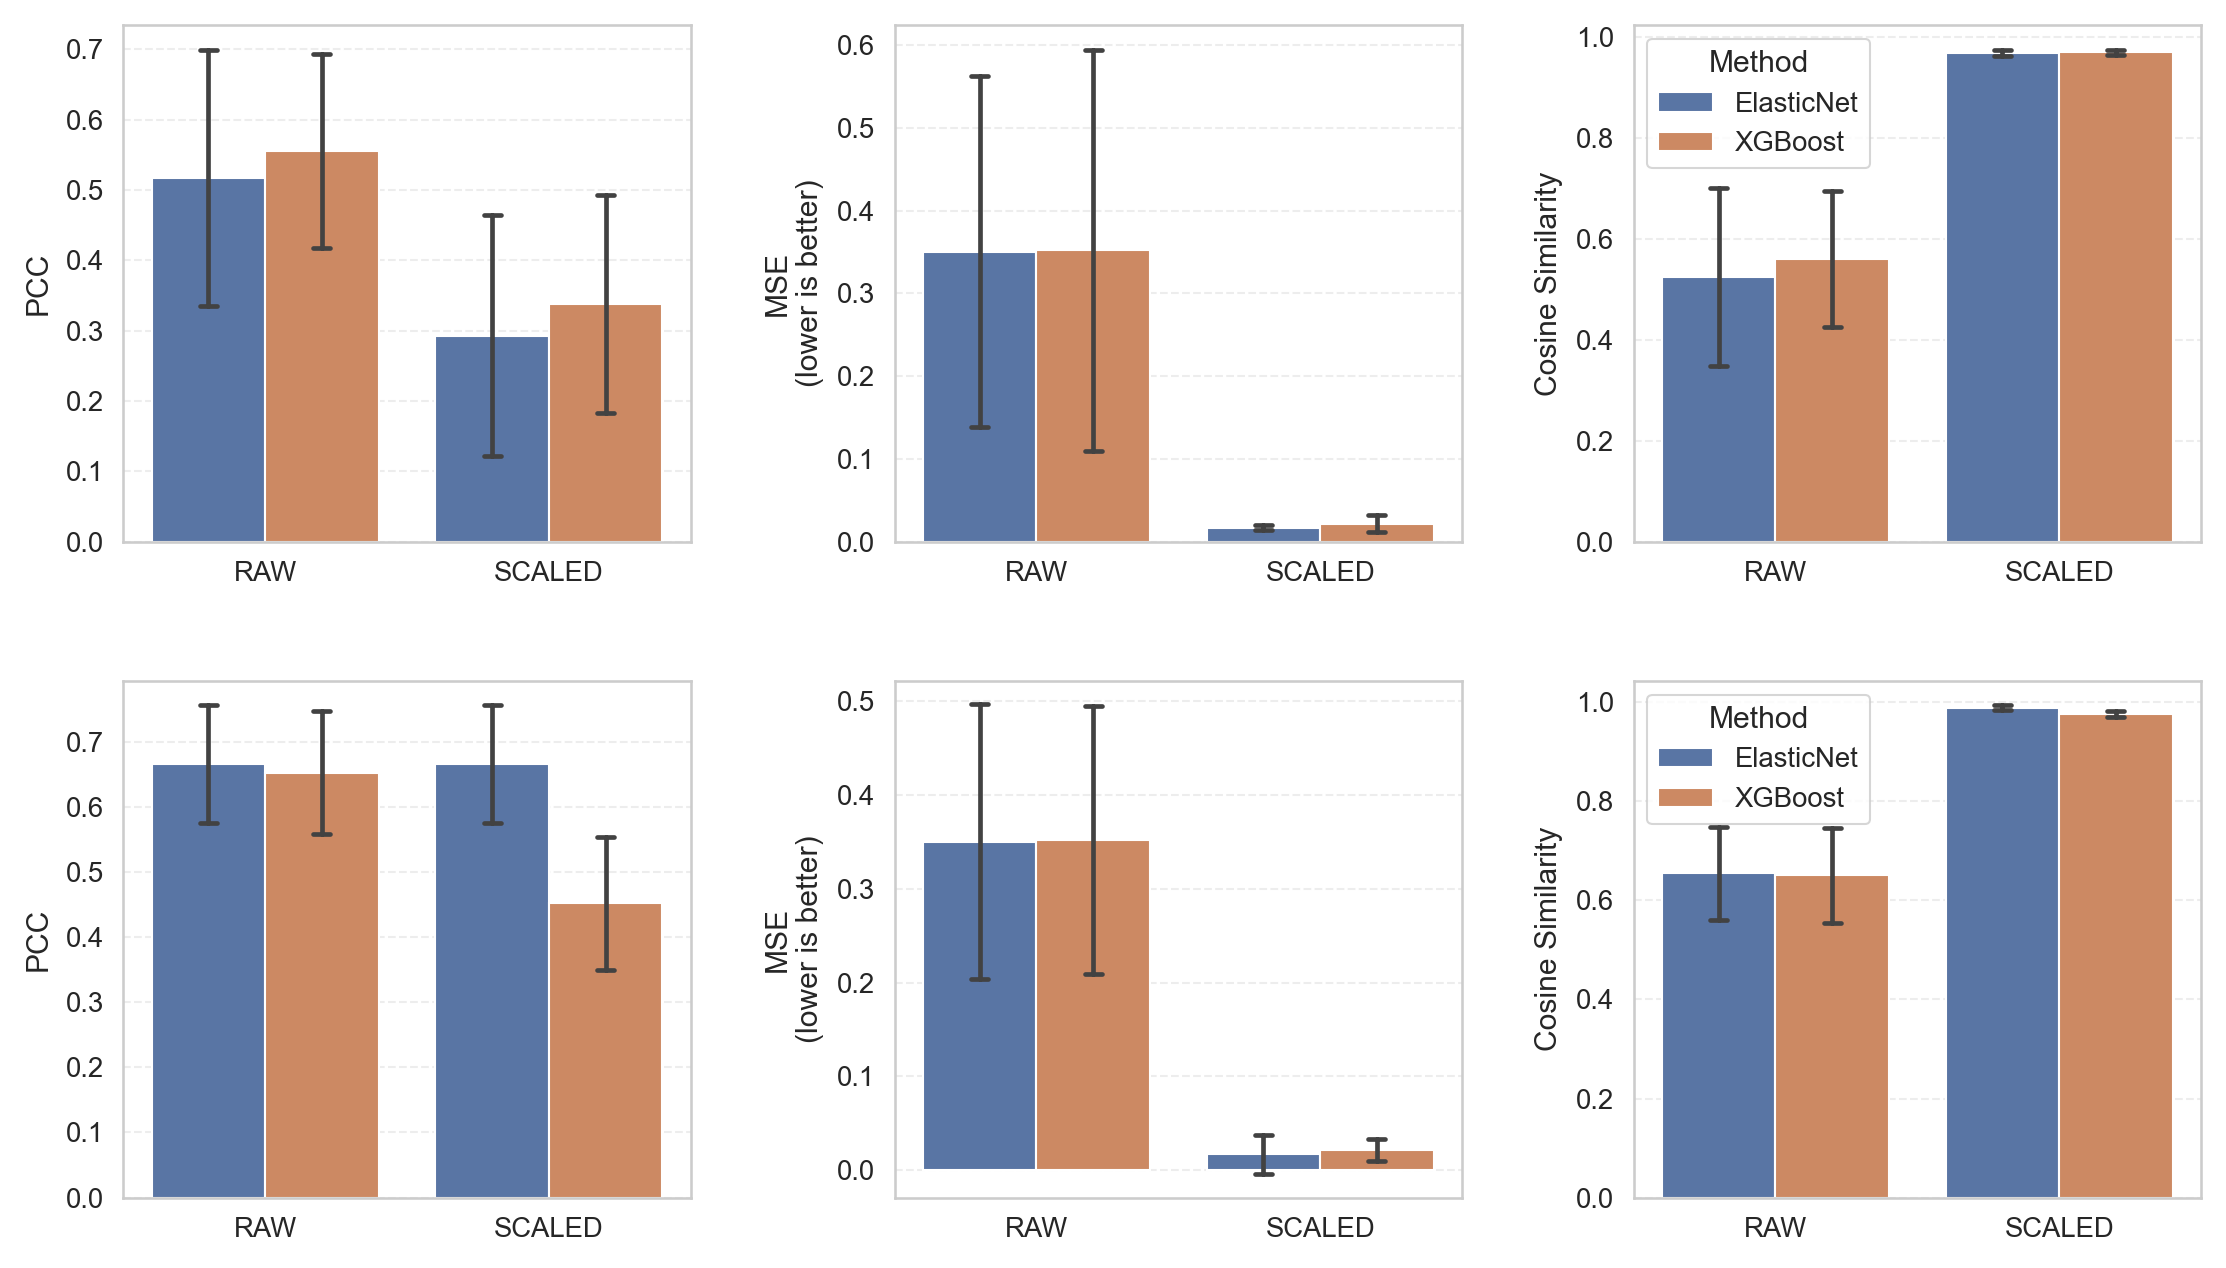

Saved: outputs\enet_xgb_sctranslator10k_raw_scaled.png


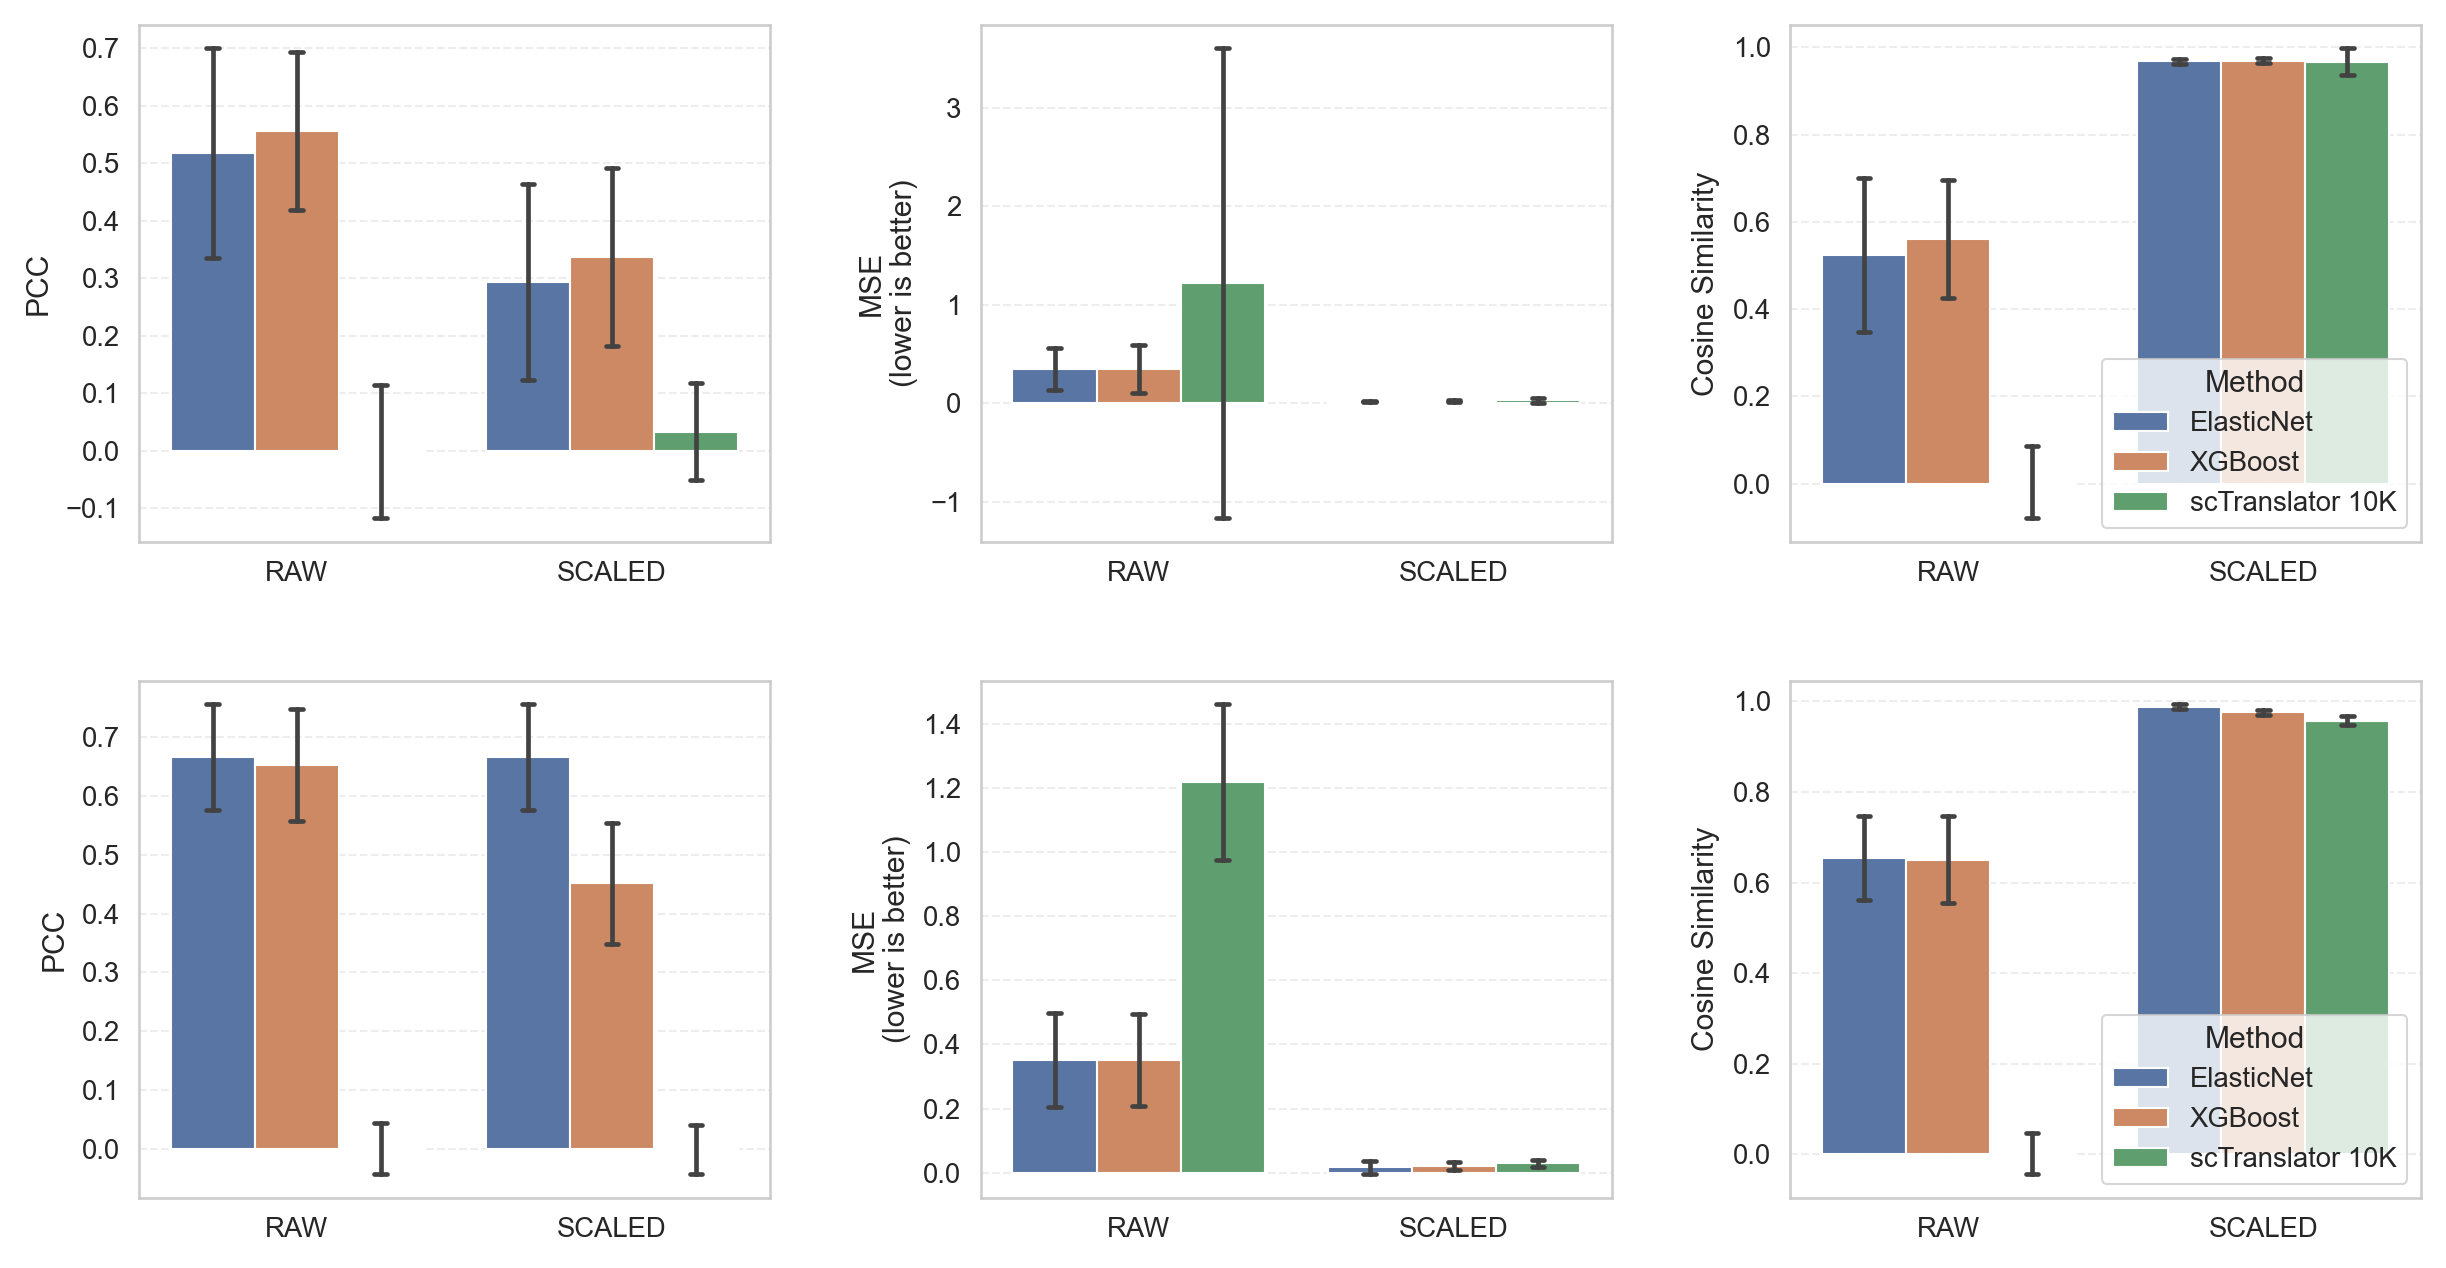

In [37]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Robust output directory
# ------------------------------------------------------------
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

eps = 1e-8

# ------------------------------------------------------------
# Checks
# ------------------------------------------------------------
required_objects = [
    "GT_raw", "PRED_raw",
    "GT_scaled", "PRED_scaled",
    "pred_df_10k", "combined_df",
    "compute_detailed_tables"
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Missing required objects: {missing_objects}")

required_xgb_cols = {"protein", "LOO sample", "true", "predicted"}
missing_xgb_cols = required_xgb_cols - set(combined_df.columns)
if missing_xgb_cols:
    raise ValueError(f"combined_df is missing required columns: {missing_xgb_cols}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def _standardize_df(df):
    out = df.copy()
    out.index = out.index.astype(str)
    out.columns = out.columns.astype(str)
    return out

def _safe_minmax_transform(df, ref_min, ref_max, eps=1e-8):
    denom = (ref_max - ref_min).replace(0, np.nan)
    return df.subtract(ref_min, axis=1).divide(denom + eps, axis=1)

def _safe_minmax_inverse(df_scaled, ref_min, ref_max):
    return df_scaled.multiply((ref_max - ref_min), axis=1).add(ref_min, axis=1)

def build_metric_frames(ground_truth, predictions, method_name, dataset_name):
    per_sample_df, per_protein_df, _, _, _, _ = compute_detailed_tables(ground_truth, predictions)

    sample_metrics = per_sample_df.rename(columns={
        "pearson": "PCC",
        "mse": "MSE",
        "cosine": "Cosine Similarity",
        "r2": "R2",
    }).copy()
    sample_metrics["Dataset"] = dataset_name
    sample_metrics["Method"] = method_name

    protein_metrics = per_protein_df.rename(columns={
        "pearson": "PCC",
        "mse": "MSE",
        "cosine": "Cosine Similarity",
        "r2": "R2",
    }).copy()
    protein_metrics["Dataset"] = dataset_name
    protein_metrics["Method"] = method_name

    return sample_metrics, protein_metrics

# ------------------------------------------------------------
# 1) Standardize main matrices
# ------------------------------------------------------------
GT_raw_cmp = _standardize_df(GT_raw)
PRED_raw_cmp = _standardize_df(PRED_raw)

GT_scaled_cmp = _standardize_df(GT_scaled)
PRED_scaled_cmp = _standardize_df(PRED_scaled)

pred_df_10k_cmp = _standardize_df(pred_df_10k)

# ------------------------------------------------------------
# 2) Build XGBoost matrices from long table
# ------------------------------------------------------------
xgb_pred_raw = combined_df.pivot_table(
    index="LOO sample",
    columns="protein",
    values="predicted",
    aggfunc="mean"
)
xgb_pred_raw = _standardize_df(xgb_pred_raw)

xgb_true_raw = combined_df.pivot_table(
    index="LOO sample",
    columns="protein",
    values="true",
    aggfunc="mean"
)
xgb_true_raw = _standardize_df(xgb_true_raw)

# ------------------------------------------------------------
# 3) Common aligned subset across all methods
# ------------------------------------------------------------
common_index = (
    GT_raw_cmp.index
    .intersection(PRED_raw_cmp.index)
    .intersection(GT_scaled_cmp.index)
    .intersection(PRED_scaled_cmp.index)
    .intersection(pred_df_10k_cmp.index)
    .intersection(xgb_pred_raw.index)
    .intersection(xgb_true_raw.index)
)

common_cols = (
    GT_raw_cmp.columns
    .intersection(PRED_raw_cmp.columns)
    .intersection(GT_scaled_cmp.columns)
    .intersection(PRED_scaled_cmp.columns)
    .intersection(pred_df_10k_cmp.columns)
    .intersection(xgb_pred_raw.columns)
    .intersection(xgb_true_raw.columns)
)

if len(common_index) == 0 or len(common_cols) == 0:
    raise ValueError("No shared cells/proteins found across GT/ENet/XGB/scTranslator objects.")

gt_raw_aligned = GT_raw_cmp.loc[common_index, common_cols]
enet_raw_aligned = PRED_raw_cmp.loc[common_index, common_cols]

gt_scaled_aligned = GT_scaled_cmp.loc[common_index, common_cols]
enet_scaled_aligned = PRED_scaled_cmp.loc[common_index, common_cols]

xgb_true_raw_aligned = xgb_true_raw.loc[common_index, common_cols]
xgb_pred_raw_aligned = xgb_pred_raw.loc[common_index, common_cols]

sct_10k_scaled_aligned = pred_df_10k_cmp.loc[common_index, common_cols]

print(f"Common comparison subset: {len(common_index)} cells x {len(common_cols)} proteins")

xgb_truth_abs_diff = (gt_raw_aligned - xgb_true_raw_aligned).abs().stack().mean()
print(f"Mean absolute difference between GT_raw and XGB true on common subset: {xgb_truth_abs_diff:.6f}")

# ------------------------------------------------------------
# 4) Build scaled/raw counterparts where needed
# ------------------------------------------------------------
ref_min = gt_raw_aligned.min(axis=0)
ref_max = gt_raw_aligned.max(axis=0)

xgb_pred_scaled_aligned = _safe_minmax_transform(xgb_pred_raw_aligned, ref_min, ref_max, eps=eps)
sct_10k_raw_aligned = _safe_minmax_inverse(sct_10k_scaled_aligned, ref_min, ref_max)

# ------------------------------------------------------------
# 5) Figure A: XGBoost vs ElasticNet on RAW and SCALED
# ------------------------------------------------------------
sample_enet_raw, protein_enet_raw = build_metric_frames(
    gt_raw_aligned, enet_raw_aligned, "ElasticNet", "RAW"
)
sample_xgb_raw, protein_xgb_raw = build_metric_frames(
    gt_raw_aligned, xgb_pred_raw_aligned, "XGBoost", "RAW"
)

sample_enet_scaled, protein_enet_scaled = build_metric_frames(
    gt_scaled_aligned, enet_scaled_aligned, "ElasticNet", "SCALED"
)
sample_xgb_scaled, protein_xgb_scaled = build_metric_frames(
    gt_scaled_aligned, xgb_pred_scaled_aligned, "XGBoost", "SCALED"
)

raw_sample_metrics_A = pd.concat(
    [sample_enet_raw, sample_xgb_raw, sample_enet_scaled, sample_xgb_scaled],
    ignore_index=True
)
raw_protein_metrics_A = pd.concat(
    [protein_enet_raw, protein_xgb_raw, protein_enet_scaled, protein_xgb_scaled],
    ignore_index=True
)

set_readable_theme(style="whitegrid", context="talk")
metrics_to_plot = ["PCC", "MSE", "Cosine Similarity"]

fig, axes = plt.subplots(2, 3, figsize=readable_figsize((20, 10)), constrained_layout=True)

# proteins on top
for col, metric in enumerate(metrics_to_plot):
    ax = axes[0, col]
    sns.barplot(
        data=raw_protein_metrics_A,
        x="Dataset",
        y=metric,
        hue="Method",
        errorbar="sd",
        capsize=0.12,
        ax=ax
    )
    _remember_axes_name(ax, f"Protein-wise {metric}")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_ylabel("MSE\n(lower is better)" if metric == "MSE" else metric)
    if col == 2:
        ax.legend(title="Method", frameon=True)
    else:
        ax.get_legend().remove()

# samples below
for col, metric in enumerate(metrics_to_plot):
    ax = axes[1, col]
    sns.barplot(
        data=raw_sample_metrics_A,
        x="Dataset",
        y=metric,
        hue="Method",
        errorbar="sd",
        capsize=0.12,
        ax=ax
    )
    _remember_axes_name(ax, f"Sample-wise {metric}")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_ylabel("MSE\n(lower is better)" if metric == "MSE" else metric)
    if col == 2:
        ax.legend(title="Method", frameon=True)
    else:
        ax.get_legend().remove()

_remember_figure_name(fig, "XGBoost vs ElasticNet (RAW and SCALED)")

save_path_A = OUTPUT_DIR / "xgb_vs_enet_raw_scaled.png"
save_readable_current_figure(save_path_A, dpi=180, bbox_inches="tight")
print("Saved:", save_path_A)
show_readable_figures()

# ------------------------------------------------------------
# 6) Figure B: ElasticNet + XGBoost + scTranslator 10K
#    on RAW and SCALED
# ------------------------------------------------------------
sample_sct_raw, protein_sct_raw = build_metric_frames(
    gt_raw_aligned, sct_10k_raw_aligned, "scTranslator 10K", "RAW"
)
sample_sct_scaled, protein_sct_scaled = build_metric_frames(
    gt_scaled_aligned, sct_10k_scaled_aligned, "scTranslator 10K", "SCALED"
)

raw_sample_metrics_B = pd.concat(
    [
        sample_enet_raw,
        sample_xgb_raw,
        sample_sct_raw,
        sample_enet_scaled,
        sample_xgb_scaled,
        sample_sct_scaled,
    ],
    ignore_index=True
)

raw_protein_metrics_B = pd.concat(
    [
        protein_enet_raw,
        protein_xgb_raw,
        protein_sct_raw,
        protein_enet_scaled,
        protein_xgb_scaled,
        protein_sct_scaled,
    ],
    ignore_index=True
)

fig, axes = plt.subplots(2, 3, figsize=readable_figsize((22, 10)), constrained_layout=True)

# proteins on top
for col, metric in enumerate(metrics_to_plot):
    ax = axes[0, col]
    sns.barplot(
        data=raw_protein_metrics_B,
        x="Dataset",
        y=metric,
        hue="Method",
        errorbar="sd",
        capsize=0.12,
        ax=ax
    )
    _remember_axes_name(ax, f"Protein-wise {metric}")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_ylabel("MSE\n(lower is better)" if metric == "MSE" else metric)
    if col == 2:
        ax.legend(title="Method", frameon=True)
    else:
        ax.get_legend().remove()

# samples below
for col, metric in enumerate(metrics_to_plot):
    ax = axes[1, col]
    sns.barplot(
        data=raw_sample_metrics_B,
        x="Dataset",
        y=metric,
        hue="Method",
        errorbar="sd",
        capsize=0.12,
        ax=ax
    )
    _remember_axes_name(ax, f"Sample-wise {metric}")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_ylabel("MSE\n(lower is better)" if metric == "MSE" else metric)
    if col == 2:
        ax.legend(title="Method", frameon=True)
    else:
        ax.get_legend().remove()

_remember_figure_name(fig, "ElasticNet vs XGBoost vs scTranslator 10K (RAW and SCALED)")

save_path_B = OUTPUT_DIR / "enet_xgb_sctranslator10k_raw_scaled.png"
save_readable_current_figure(save_path_B, dpi=180, bbox_inches="tight")
print("Saved:", save_path_B)
show_readable_figures()

## Compact protein-metric figures and tables

These extra figures come after all earlier plots. Each has one row of three protein-wise distributions: **PCC, MSE and cosine similarity**, with no titles. Red dashed lines mark metric means. Best/worst proteins and summary statistics are printed as tables instead of occupying plot panels. CSV copies are saved in `figures_pdf/tables`.

The final export cell saves the compact PDFs using the stable filenames shown below, without a numerical prefix. The original larger plots remain available as title-free versions. No models are refitted and no metrics are recomputed.

This section reuses `per_protein_raw` and `per_protein_scaled` from the original ElasticNet analyses.


In [38]:
# Compact protein-wise distributions and separate data tables.
# These functions reuse the metric tables computed earlier in the notebook.
COMPACT_TABLE_DIR = FIGURES_PDF_DIR / 'tables'
COMPACT_TABLES = {}


def print_compact_protein_tables(protein_metrics, model_label, file_stem):
    """Print and save summary statistics and metric-specific best/worst proteins."""
    data = protein_metrics.copy()
    if 'protein' not in data.columns:
        if data.index.name == 'protein':
            data = data.reset_index()
        else:
            raise ValueError(f'{model_label}: expected a protein column.')
    metric_specs = [
        ('pearson', 'PCC', True),
        ('mse', 'MSE', False),
        ('cosine', 'Cosine similarity', True),
    ]
    required = ['protein'] + [metric for metric, _, _ in metric_specs]
    missing = [column for column in required if column not in data.columns]
    if missing:
        raise ValueError(f'{model_label}: missing columns {missing}')

    summary_rows = []
    rankings = {}
    for metric, display_name, higher_is_better in metric_specs:
        values = pd.to_numeric(data[metric], errors='coerce').replace([np.inf, -np.inf], np.nan)
        data[metric] = values
        valid = values.dropna()
        summary_rows.append({
            'metric': display_name,
            'n_valid': len(valid),
            'n_missing_or_nonfinite': len(values) - len(valid),
            'mean': valid.mean(),
            'std': valid.std(),
            'min': valid.min(),
            'q25': valid.quantile(0.25),
            'median': valid.median(),
            'q75': valid.quantile(0.75),
            'max': valid.max(),
        })
        ordered = data.loc[values.notna(), ['protein', metric]].sort_values(
            metric, ascending=not higher_is_better, kind='stable',
        )
        best = ordered.head(10).copy()
        worst = ordered.sort_values(metric, ascending=higher_is_better, kind='stable').head(10).copy()
        best.insert(0, 'set', 'Best')
        worst.insert(0, 'set', 'Worst')
        best.insert(1, 'rank', np.arange(1, len(best) + 1))
        worst.insert(1, 'rank', np.arange(1, len(worst) + 1))
        rankings[metric] = pd.concat([best, worst], ignore_index=True)

    summary = pd.DataFrame(summary_rows)
    COMPACT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(COMPACT_TABLE_DIR / f'{file_stem}_summary_statistics.csv', index=False)
    print('\n' + '=' * 80)
    print(model_label)
    print('Summary statistics:')
    print(summary.to_string(index=False, float_format=lambda value: f'{value:.6g}'))
    for metric, display_name, _ in metric_specs:
        table = rankings[metric]
        print(f'\nBest / worst proteins by {display_name}:')
        print(table.to_string(index=False, float_format=lambda value: f'{value:.6g}'))
        table.to_csv(COMPACT_TABLE_DIR / f'{file_stem}_best_worst_{metric}.csv', index=False)
    result = {'summary': summary, 'rankings': rankings}
    COMPACT_TABLES[file_stem] = result
    return result


def plot_compact_protein_metrics(protein_metrics, model_label, file_stem):
    """One title-free row: protein PCC, MSE and cosine-similarity distributions."""
    print_compact_protein_tables(protein_metrics, model_label, file_stem)
    colors = _get_group_colors('proteins')
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 2.6))
    fig.patch.set_facecolor('white')
    fig._compact_protein_metrics = True
    fig._readable_pdf_pad = 0.04
    fig._readable_export_name = f'{file_stem}.pdf'
    for column, (metric, xlabel) in enumerate([
        ('pearson', 'Protein PCC'),
        ('mse', 'Protein MSE'),
        ('cosine', 'Protein cosine similarity'),
    ]):
        ax = axes[column]
        values = pd.to_numeric(protein_metrics[metric], errors='coerce')
        values = values[np.isfinite(values)]
        if len(values):
            ax.hist(values, bins=30, color=colors[metric], edgecolor='black', linewidth=0.6, alpha=0.85)
            ax.axvline(values.mean(), color='red', linestyle='--', linewidth=1.6)
        else:
            ax.text(0.5, 0.5, 'No finite values', transform=ax.transAxes,
                    ha='center', va='center', fontsize=16)
        ax.set_xlabel(xlabel, fontsize=18, labelpad=5)
        ax.set_ylabel('Proteins' if column == 0 else '', fontsize=17, labelpad=5)
        ax.tick_params(axis='both', labelsize=15.5, pad=3)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
        ax.grid(axis='y', linestyle='--', alpha=0.20)
        ax.set_axisbelow(True)
        ax.set_title('')
    prepare_readable_figure(fig)
    _cache_figure_pdf(fig, source_name=file_stem)
    show_readable_figures()
    # The in-memory PDF is retained for the last export cell.
    plt.close(fig)
    return fig



ElasticNet — RAW protein-wise metrics
Summary statistics:
           metric  n_valid  n_missing_or_nonfinite     mean      std       min      q25   median      q75      max
              PCC     5113                       0 0.518826 0.184272        -1 0.388302 0.514816 0.660142 0.908862
              MSE     5113                       0  0.34915 0.209839 0.0757656 0.224138  0.29561 0.403722  2.97216
Cosine similarity     5113                       0 0.525055 0.177755 -0.242665 0.395078 0.518539 0.662418  0.91141

Best / worst proteins by PCC:
  set  rank   protein    pearson
 Best     1   IGF2BP1   0.908862
 Best     2     BASP1   0.906439
 Best     3    MAGEA4    0.89898
 Best     4     MAP1B   0.885239
 Best     5     GNG12   0.885098
 Best     6    CORO1A   0.884077
 Best     7      TJP2   0.879913
 Best     8      LCP1   0.879216
 Best     9     HCLS1   0.878749
 Best    10     RBM47    0.87786
Worst     1    POLRMT         -1
Worst     2      DDX6   -0.37291
Worst     3   FAM175A

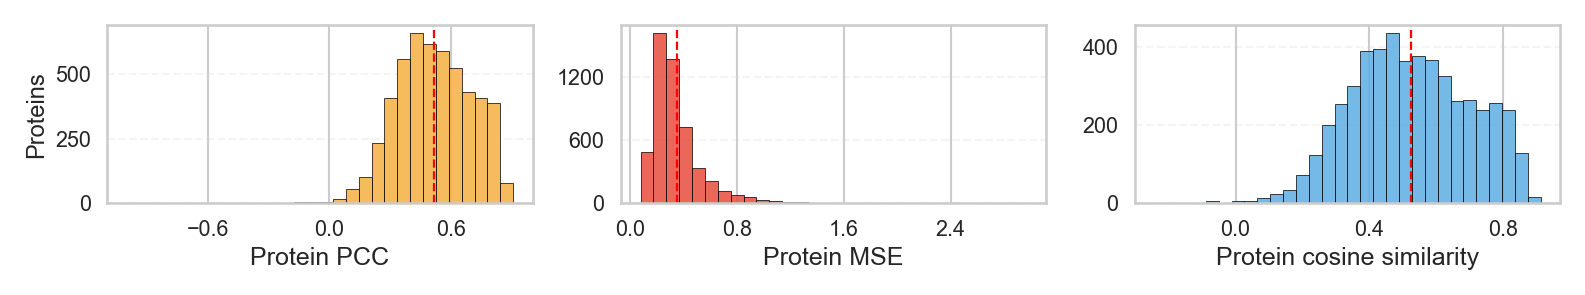


ElasticNet — SCALED protein-wise metrics
Summary statistics:
           metric  n_valid  n_missing_or_nonfinite      mean        std         min       q25    median       q75       max
              PCC     5113                       0  0.294782   0.171391 -0.00757054  0.159992  0.267797   0.39754  0.853678
              MSE     5113                       0 0.0168142 0.00291269   0.0127903 0.0150154 0.0160384 0.0175513 0.0388803
Cosine similarity     5113                       0  0.968082 0.00579707    0.924038  0.966472  0.969667  0.971691  0.976312

Best / worst proteins by PCC:
  set  rank  protein     pearson
 Best     1    BASP1    0.853678
 Best     2    EPCAM    0.805745
 Best     3  S100A14    0.793624
 Best     4   MAGEA4    0.791338
 Best     5  TACSTD2    0.789501
 Best     6     ST14    0.775901
 Best     7      CA2    0.774254
 Best     8 SERPINB5    0.774187
 Best     9   PDLIM4    0.773463
 Best    10  IGF2BP1    0.772038
Worst     1    SRPRB -0.00757054
Worst     2    

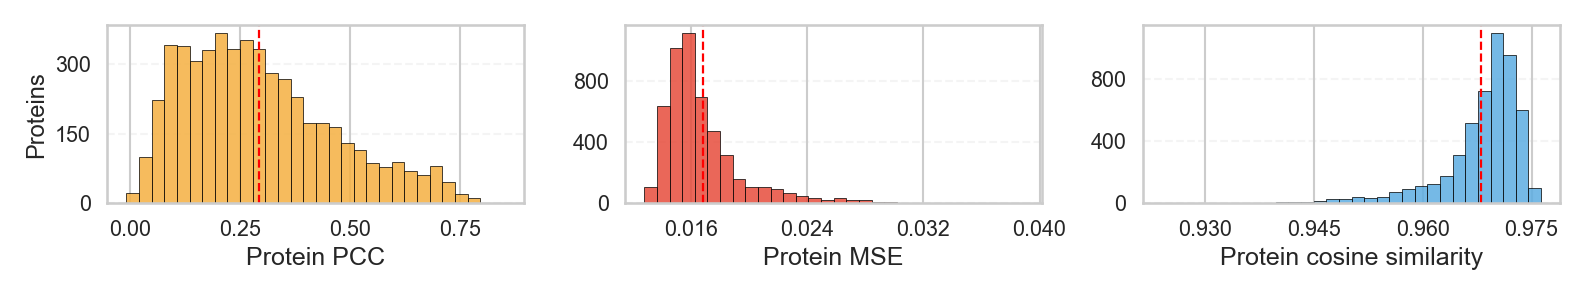

Compact table CSV files: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\figures_pdf\tables


In [39]:
plot_compact_protein_metrics(
    per_protein_raw,
    model_label='ElasticNet — RAW protein-wise metrics',
    file_stem='elasticnet_raw_protein_metrics_1x3',
)
plot_compact_protein_metrics(
    per_protein_scaled,
    model_label='ElasticNet — SCALED protein-wise metrics',
    file_stem='elasticnet_scaled_protein_metrics_1x3',
)
print('Compact table CSV files:', COMPACT_TABLE_DIR)


## Export all figures to PDF

Run this cell after the plotting cells. It creates `figures_pdf` next to the notebook and saves one PDF for every captured figure, including figures already closed.

In [40]:
pdf_files = export_notebook_figures()
pdf_files

Saved 22 PDF figures to: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\figures_pdf
  enet_sctranslator__001__elasticnet_metrics_raw.pdf
  enet_sctranslator__002__elasticnet_detailed_metrics_raw.pdf
  enet_sctranslator__003__elasticnet_detailed_metrics_raw.pdf
  enet_sctranslator__004__elasticnet_metrics_scaled.pdf
  enet_sctranslator__005__elasticnet_detailed_metrics_scaled.pdf
  enet_sctranslator__006__elasticnet_detailed_metrics_scaled.pdf
  enet_sctranslator__007__scTranslator_Benchmark_Overall_Performance_Metrics.pdf
  enet_sctranslator__008__pred_best_10k_vs_enet_minmax_barplot.pdf
  enet_sctranslator__009__enet_raw_vs_minmax_barplot.pdf
  enet_sctranslator__010__Zero-Shot_Per-Protein_View_Ground_Truth_vs_Predictions_across_369_cells.pdf
  enet_sctranslator__011__Zero-Shot_Per-Cell_View_Ground_Truth_vs_Predictions_across_5112_proteins.pdf
  enet_sctranslator__012__ElasticNet_Per-Protein_View_Ground_Truth_vs_Predictions_across_cells.pdf
  enet_sc

[WindowsPath('C:/Users/hp/Desktop/CPPR/Cancer-Protein-RNA-research/03. elasticNet/model_results/figures_pdf/enet_sctranslator__001__elasticnet_metrics_raw.pdf'),
 WindowsPath('C:/Users/hp/Desktop/CPPR/Cancer-Protein-RNA-research/03. elasticNet/model_results/figures_pdf/enet_sctranslator__002__elasticnet_detailed_metrics_raw.pdf'),
 WindowsPath('C:/Users/hp/Desktop/CPPR/Cancer-Protein-RNA-research/03. elasticNet/model_results/figures_pdf/enet_sctranslator__003__elasticnet_detailed_metrics_raw.pdf'),
 WindowsPath('C:/Users/hp/Desktop/CPPR/Cancer-Protein-RNA-research/03. elasticNet/model_results/figures_pdf/enet_sctranslator__004__elasticnet_metrics_scaled.pdf'),
 WindowsPath('C:/Users/hp/Desktop/CPPR/Cancer-Protein-RNA-research/03. elasticNet/model_results/figures_pdf/enet_sctranslator__005__elasticnet_detailed_metrics_scaled.pdf'),
 WindowsPath('C:/Users/hp/Desktop/CPPR/Cancer-Protein-RNA-research/03. elasticNet/model_results/figures_pdf/enet_sctranslator__006__elasticnet_detailed_metri